In [1]:
import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MEDIA_AMPL_2'

# Obtener la ruta absoluta del directorio
directorio_absoluto = os.path.abspath(directorio)

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio_absoluto)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio_absoluto, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean_a_2 = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean_a_2)

                                                  Ruta  Etiqueta
0    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         2
1    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         4
2    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         6
3    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         8
4    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         2
..                                                 ...       ...
171  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         8
172  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         1
173  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         3
174  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         5
175  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         7

[176 rows x 2 columns]


In [2]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms, utils
from torchvision.transforms import v2
import re

import copy
# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = "cuda"
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA version: 12.1
Using device: cuda


## FUNCIÓN SIN TL SIN OC

A continuación se presentan una serie de funciones donde se encapsula todo el entrenamiento de un modelo, para 4 formas diferentes de entrenar. Se comentará exhaustivamente esta primera función. Las demás para las distitnas formas de entrenar son similares, cambiando algunas cosas que se comentarán en el código. Lo recomendable, para entender la función, sería leer la primera y compararla con las demás. Además, en cuanto a los parámetros de la función, cuando se entrena con TL, hay un parámetro más ya que se indican dos número de épocas, una para el modelo congelado y otra para el modelo sin congelar.

In [3]:

# Función para calcular el accuracy
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales para ver cuántas son correctas
    acc = correct.float().sum() / labels.size(0)  # Suma las predicciones correctas y divide por el número total de etiquetas para obtener la precisión
    return acc.item()  # Devuelve la precisión como un valor escalar

# Función para calcular el recall
def recall(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)

    # Mueve los tensores a la CPU para asegurar la compatibilidad en operaciones subsecuentes
    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))  # Calcula los verdaderos positivos (TP): predicciones positivas que son correctas
    FN = sum((preds == 0) & (labels == 1))  # Calcula los falsos negativos (FN): etiquetas reales positivas que fueron predichas como negativas

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0  # Calcula el recall: TP dividido por la suma de TP y FN. Si TP + FN es 0, el recall es 0
    return recall_score  # Devuelve el valor del recall

# Función para calcular la precisión (precision)
def precision(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)

    # Mueve los tensores a la CPU para asegurar la compatibilidad en operaciones subsecuentes
    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))  # Calcula los verdaderos positivos (TP): predicciones positivas que son correctas
    FP = sum((preds == 1) & (labels == 0))  # Calcula los falsos positivos (FP): predicciones positivas que son incorrectas

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0  # Calcula la precisión: TP dividido por la suma de TP y FP. Si TP + FP es 0, la precisión es 0
    return precision_score  # Devuelve el valor de la precisión


#####Parámetros
#####   dataset: el conjunto de datos, siendo una columna la ruta y otra la etiqueta de la imagen
#####   num_folds_outer: el número de folds de test que se ejecutarán
#####   num_epochs: el número total de épocas que se entrenará
#####   op: el optimziador usado
#####   batch_size: tamaño de batch para entrenamiento
#####   lr: learning rate para el optimizador
#####   data_aug: True o False, para si se hace aumento de datos o no
#####   ini: un char representnado uno de los optimizadores que se pueden usar
#####   random_seed: semilla aleatoria para el stratified k fold
#####   seeds_tr_split: lista de tantas semillas como folds se tengan, es para hacer el train test split del conjunto de train en cada ejecución
def prueba_k_fold_resnet_no_pre(dataset, num_folds_outer, num_epochs, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    # Verifica si el aumento de datos está activado
    if data_aug:
        # Transformaciones para los datos de entrenamiento con aumento de datos
        transform_t = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.RandomHorizontalFlip(),  # Aplica un volteo horizontal aleatorio a la imagen
            v2.RandomVerticalFlip(),  # Aplica un volteo vertical aleatorio a la imagen
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])

        # Transformaciones para los datos de validación (sin aumento de datos)
        transform_v = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])
    else:
        # Transformaciones para los datos de entrenamiento sin aumento de datos
        transform_t = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])

        # Transformaciones para los datos de validación (sin aumento de datos)
        transform_v = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])


    # Modelo personalizado basado en ResNet
    # Define una clase para una red ResNet personalizada
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
    
            # Carga el modelo ResNet-18 sin preentrenamiento
            resnet = models.resnet18(weights=None)
            
            # Extrae todas las capas de la ResNet menos la última capa fully connected
            self.features = nn.Sequential(*list(resnet.children())[:-1])
            
            # Define una nueva capa fully connected para la clasificación binaria
            self.fc_binary = nn.Linear(512, num_classes_binary)
    
            # Inicializa los pesos de la red según el método especificado
            if (ini == "G"):
                self.apply(self.init_weights_glorot)  # Inicialización de Glorot (Xavier)
            elif(ini == "H"):
                self.apply(self.init_weights_he)  # Inicialización de He
            elif (ini == "N"):
                self.apply(self.init_weights_normal)  # Inicialización normal
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)  # Inicialización uniforme
            elif (ini == "O"):
                self.apply(self.init_weights_orthogonal)  # Inicialización ortogonal
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)  # Inicialización a ceros
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)  # Inicialización a unos
    
        # Inicialización de pesos con el método de Glorot (Xavier)
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)  # Inicializa los pesos de forma uniforme según Glorot
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con el método de He
        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')  # Inicializa los pesos según He
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con distribución normal
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Inicializa los pesos con una distribución normal con media 0 y desviación estándar 0.01
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con distribución uniforme
        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Inicializa los pesos de forma uniforme entre -0.1 y 0.1
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos ortogonal
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Inicializa los pesos de forma ortogonal
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos a ceros
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)  # Inicializa todos los pesos a cero
                if m.bias is not None:
                    init.zeros_(m.bias)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos a unos
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)  # Inicializa todos los pesos a uno
                if m.bias is not None:
                    init.ones_(m.bias)  # Inicializa los sesgos a uno
    
        # Método forward para el paso de la red
        def forward(self, x):
            x = self.features(x)  # Pasa la entrada a través de la parte de características de la red
            x = x.view(x.size(0), -1)  # Aplana las características a un vector de 1D para la capa fully connected
    
            # Pasa la salida a través de la capa fully connected personalizada para la clasificación binaria
            out_binary = self.fc_binary(x)
    
            return out_binary  # Devuelve la salida para la clasificación binaria

    # Define una clase personalizada para el conjunto de datos
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            """
            Inicializa el conjunto de datos personalizado.

            Args:
                dataframe (pd.DataFrame): DataFrame que contiene rutas a las imágenes y etiquetas.
                transform (callable, optional): Transformaciones que se aplicarán a cada imagen.
            """
            self.data = dataframe  # Almacena el DataFrame con rutas y etiquetas
            self.transform = transform  # Almacena las transformaciones, si se proporcionan

        def __len__(self):
            """
            Devuelve la longitud del conjunto de datos.

            Returns:
                int: Número de ejemplos en el conjunto de datos.
            """
            return len(self.data)  # Retorna el número de filas en el DataFrame

        def __getitem__(self, idx):
            """
            Obtiene una imagen y su etiqueta correspondiente por índice.

            Args:
                idx (int): Índice del ejemplo a obtener.

            Returns:
                tuple: Una imagen transformada y su etiqueta binaria.
            """
            # Obtiene la ruta de la imagen de la primera columna del DataFrame
            img_path = self.data.iloc[idx, 0]

            # Abre la imagen usando PIL y la convierte a RGB
            image = Image.open(img_path).convert('RGB')

            # Obtiene la etiqueta binaria de la segunda columna del DataFrame y la convierte a tensor
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            # Aplica las transformaciones a la imagen, si están definidas
            if self.transform:
                image = self.transform(image)

            # Retorna la imagen (posiblemente transformada) y la etiqueta binaria
            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las métricas de cada fold
    accs = []  # Para almacenar las precisiones de cada fold
    recs = []  # Para almacenar los recalls de cada fold
    precs = []  # Para almacenar las precisiones de cada fold
    
    directorio = './IMGS_MEDIA_AMPL_2'
    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    for i in range(num_folds_outer):
        print(f"Fold {i}")

        # Crear un vector de pacientes con identificadores '01' a '75'
        pacientes = [f'{i:02}' for i in range(2, 76)]

        # Definir los dos strings posibles
        strings = ['HVN', 'H9O']

        # Número de combinaciones a crear
        num_combinaciones = 16

        # Inicializar contadores
        combinaciones_totales = 0
        total_negativo = 0
        total_positivo = 0

        # Lista para almacenar las combinaciones seleccionadas
        combinaciones = []

        # Semilla para la generación aleatoria
        random.seed(seeds_tr_split[i])

        # Obtener la lista de nombres de archivos desde la columna 'Ruta' del DataFrame 'dataset'
        nombres_de_archivos_mal = dataset['Ruta'].to_list()

        # Ajustar los nombres de archivos, obteniendo solo la parte relevante después de "2\"
        nombres_de_archivos = [s.split("2\\")[1] for s in nombres_de_archivos_mal]

        # Bucle para generar las combinaciones hasta alcanzar el número deseado
        while combinaciones_totales < num_combinaciones:
            # Seleccionar un paciente aleatorio de la lista
            paciente_aleatorio = random.choice(pacientes)

            # Seleccionar un string aleatorio de la lista
            string_aleatorio = random.choice(strings)

            # Construir la expresión regular para buscar archivos correspondientes
            expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

            # Filtrar los nombres de archivos que coinciden con la expresión regular
            archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]

            # Verificar si hay exactamente 4 archivos coincidentes
            if len(archivos_coincidentes) == 4:
                # Obtener la etiqueta (asumida como el primer carácter del cuarto componente del nombre de archivo)
                etiqueta = int(archivos_coincidentes[0].split("_")[3][0])

                # Verificar si la etiqueta es par o impar
                if etiqueta % 2 == 0:
                    # Si es par (positiva) y no se ha alcanzado el límite de positivos
                    if total_positivo < 8:
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_positivo += 1
                else:
                    # Si es impar (negativa) y no se ha alcanzado el límite de negativos
                    if total_negativo < 8:
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_negativo += 1

        # Lista para almacenar las rutas completas y las etiquetas
        data = []

        # Obtener la ruta absoluta del directorio
        directorio_absoluto = os.path.abspath(directorio)

        # Iterar sobre los archivos seleccionados en las combinaciones
        for archivo in combinaciones:
            # Construir la ruta completa del archivo
            ruta_completa = os.path.join(directorio_absoluto, archivo)

            # Dividir el nombre del archivo en componentes
            elementos = archivo.split("_")

            # Obtener la etiqueta (asumida como el primer carácter del cuarto componente del nombre de archivo)
            etiqueta = elementos[3] if len(elementos) >= 4 else None

            # Asegurarse de que la etiqueta sea el primer carácter
            etiqueta = etiqueta[0]

            # Agregar la ruta y la etiqueta a la lista de datos
            data.append((ruta_completa, int(etiqueta)))

            # Eliminar el archivo de la lista original de nombres
            nombres_de_archivos.remove(archivo)

        # Crear un DataFrame de Pandas con las rutas y etiquetas
        test_data_fold = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

        

        ##Para entrenamiento, se concatenan el dataset original y el de test y se quitan los duplicados
        train_data_fold = pd.concat([dataset, test_data_fold]).drop_duplicates(keep=False)

        
        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[i], stratify = train_data_fold['Etiqueta'])
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)

        print(len(train_dataset_fold))
        print(len(val_dataset_fold))
        print(len(test_dataset))
        
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        
        ##El bs es 4, porque por el orden del dataset, serán 4 imágenes del mismo paciente
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=4, shuffle=False)
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None
        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            ##Se adapta la etiqueta
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)

            
            # Actualiza el mejor modelo basado en la pérdida de validación

            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch

            
         # Imprime la mejor época y la mejor pérdida de validación para este fold
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        # Evaluación en el conjunto de prueba con el mejor modelo
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        preds_final = []
        labels_final = []
        with torch.no_grad():
            for images, bin_label in test_dataloader:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0

                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    preds = bin_pred > 0.5
                    bin_label = bin_label.tolist()
                    preds = preds.cpu()
                    ones = np.count_nonzero(preds == 1)

                    #Se predice de 4 imágenes de un mismo paciente en 4 imágenes
                    #Si la len es par, exige clara mayoría, si es impar, exige que haya 1 más que la mitad
                    if (ones > len(bin_label)/2):
                        preds = 1
                    else:
                        preds = 0

                    preds_final.append(preds)
                    labels_final.append(int(bin_label[0])) ##Todas las etiquetas del minibatch son iguales, se toma la primera
                    ##La ground truth de un minibatch de un paciente es la misma, por lo que todas las etiquetas son iguales

            
            preds_final = np.array(preds_final)
            labels_final = np.array(labels_final)
                    
            ##Se calculan las diferentes métricas
            avg_acc = accuracy(preds_final, labels_final)
            avg_rec = recall(preds_final, labels_final)
            avg_prec = precision(preds_final, labels_final)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)
        
    # Retorna los promedios y desviaciones estándar de las métricas a través de los folds
    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

## FUNCION SIN TL CON OC

In [4]:

def accuracy(outputs, labels):
    
    correct = (outputs == labels)  # Compara las predicciones con las etiquetas reales
    
    acc = sum(correct) / len(labels)  # Calcula la precisión
    return acc

def recall(outputs, labels):
    
    TP = sum((outputs == 1) & (labels == 1))
    FN = sum((outputs == 0) & (labels == 1))

    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
   
    return recall_score

def precision(outputs, labels):

    TP = sum((outputs == 1) & (labels == 1))
    FP = sum((outputs == 1) & (labels == 0))
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    
    return precision_score



def prueba_k_fold_resnet_no_pre_oc(dataset, num_folds_outer, num_epochs, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])


            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01) 
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    
    directorio = './IMGS_MEDIA_AMPL_2'
    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.


    for i in range(num_folds_outer):
        print(f"Fold {i}")
        # Vector de pacientes y de 2 strings
        pacientes = [f'{i:02}' for i in range(2, 76)]
        strings = ['HVN', 'H9O']
        # Número de combinaciones que deseas crear
        num_combinaciones = 16
        combinaciones_totales = 0
        total_negativo = 0
        total_positivo = 0
        # Lista para almacenar las combinaciones
        combinaciones = []

        random.seed(seeds_tr_split[i])

        
         # Obtener la lista de nombres de archivos que coinciden con la expresión regular
        nombres_de_archivos_mal = dataset['Ruta']  # Reemplaza '*' con el directorio o patrón adecuado si es necesario
        nombres_de_archivos_mal = nombres_de_archivos_mal.to_list()

        nombres_de_archivos = [s.split("2\\")[1] for s in nombres_de_archivos_mal]
        # Dividir el conjunto de datos en entrenamiento y validación para este fold

        while combinaciones_totales < num_combinaciones:
            # Seleccionar un paciente aleatorio

            paciente_aleatorio = random.choice(pacientes)

            # Seleccionar un string aleatorio
            string_aleatorio = random.choice(strings)

            # Expresión regular para filtrar nombres de archivos
            expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

            # Filtrar los nombres de archivos que coinciden con la expresión regular
            archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]
            
            if (len(archivos_coincidentes) == 4):
                etiqueta = int(archivos_coincidentes[0].split("_")[3][0])
                if(etiqueta % 2 == 0):
                    if (total_positivo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_positivo += 1
                else:
                    if (total_negativo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_negativo += 1
                    
                
        data = []
        directorio_absoluto = os.path.abspath(directorio)
        # Iterar sobre los archivos
        for archivo in combinaciones:
            # Obtener la ruta completa del archivo
            ruta_completa = os.path.join(directorio_absoluto, archivo)
            # Obtener los elementos después de hacer split("_")
            elementos = archivo.split("_")
            # Obtener la etiqueta (cuarto elemento)
            etiqueta = elementos[3] if len(elementos) >= 4 else None
            # Agregar la ruta y la etiqueta a la lista de datos
            etiqueta = etiqueta[0]
            # print(etiqueta)
            data.append((ruta_completa, int(etiqueta)))

            nombres_de_archivos.remove(archivo)

    
        # Crear el DataFrame de Pandas
        test_data_fold = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

        


        train_data_fold = pd.concat([dataset, test_data_fold]).drop_duplicates(keep=False)

        
        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[i], stratify = train_data_fold['Etiqueta'])
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        test_dataloader = DataLoader(dataset=test_dataset, batch_size=4, shuffle=False)
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        #####!!!!!!!!!!!!!!!!!!!!!!!######
        ####Esta es una de las diferencias con el código de la función anterior, se implementa un scheduler para la política de ciclo único que se llamará después del optimizador
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold_in), epochs = num_epochs)
        
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None
        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
               
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch

            
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        preds_final = []
        labels_final = []
        with torch.no_grad():
            for images, bin_label in test_dataloader:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0

                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    preds = bin_pred > 0.5
                    bin_label = bin_label.tolist()
                    preds = preds.cpu()
                    ones = np.count_nonzero(preds == 1)

                    #Si la len es par, exige clara mayoría, si es impar, exige que haya 1 más que la mitad
                    if (ones > len(bin_label)/2):
                        preds = 1
                    else:
                        preds = 0

                    preds_final.append(preds)
                    labels_final.append(int(bin_label[0])) ##Todas las etiquetas del minibatch son iguales, se toma la primera

            
            preds_final = np.array(preds_final)
            labels_final = np.array(labels_final)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = accuracy(preds_final, labels_final)
            avg_rec = recall(preds_final, labels_final)
            avg_prec = precision(preds_final, labels_final)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

## FUNCION CON TL SIN OC

In [5]:

def accuracy(outputs, labels):
    
    correct = (outputs == labels)  # Compara las predicciones con las etiquetas reales
    
    acc = sum(correct) / len(labels)  # Calcula la precisión
    return acc

def recall(outputs, labels):
    
    TP = sum((outputs == 1) & (labels == 1))
    FN = sum((outputs == 0) & (labels == 1))

    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
   
    return recall_score

def precision(outputs, labels):

    TP = sum((outputs == 1) & (labels == 1))
    FP = sum((outputs == 1) & (labels == 0))
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    
    return precision_score


### Las épocas totales se dividen en 2 para cuando se entrena con TL
def prueba_k_fold_resnet_pre(dataset, num_folds_outer, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            ####!!!!!!!!####
            ### Al ser coon preentrenamiento, se cargan los pesos del entrenamiento en ImageNet.
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight) 
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    
    directorio = './IMGS_MEDIA_AMPL_2'
    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.


    for i in range(num_folds_outer):
        print(f"Fold {i}")
        # Vector de pacientes y de 2 strings
        pacientes = [f'{i:02}' for i in range(2, 76)]
        strings = ['HVN', 'H9O']
        # Número de combinaciones que deseas crear
        num_combinaciones = 16
        combinaciones_totales = 0
        total_negativo = 0
        total_positivo = 0
        # Lista para almacenar las combinaciones
        combinaciones = []

        random.seed(seeds_tr_split[i])

        
         # Obtener la lista de nombres de archivos que coinciden con la expresión regular
        nombres_de_archivos_mal = dataset['Ruta']  # Reemplaza '*' con el directorio o patrón adecuado si es necesario
        nombres_de_archivos_mal = nombres_de_archivos_mal.to_list()

        nombres_de_archivos = [s.split("2\\")[1] for s in nombres_de_archivos_mal]
        # Dividir el conjunto de datos en entrenamiento y validación para este fold

        while combinaciones_totales < num_combinaciones:
            # Seleccionar un paciente aleatorio

            paciente_aleatorio = random.choice(pacientes)

            # Seleccionar un string aleatorio
            string_aleatorio = random.choice(strings)

            # Expresión regular para filtrar nombres de archivos
            expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

            # Filtrar los nombres de archivos que coinciden con la expresión regular
            archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]
            
            if (len(archivos_coincidentes) == 4):
                etiqueta = int(archivos_coincidentes[0].split("_")[3][0])
                if(etiqueta % 2 == 0):
                    if (total_positivo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_positivo += 1
                else:
                    if (total_negativo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_negativo += 1
                    
                
        data = []
        directorio_absoluto = os.path.abspath(directorio)
        # Iterar sobre los archivos
        for archivo in combinaciones:
            # Obtener la ruta completa del archivo
            ruta_completa = os.path.join(directorio_absoluto, archivo)
            # Obtener los elementos después de hacer split("_")
            elementos = archivo.split("_")
            # Obtener la etiqueta (cuarto elemento)
            etiqueta = elementos[3] if len(elementos) >= 4 else None
            # Agregar la ruta y la etiqueta a la lista de datos
            etiqueta = etiqueta[0]
            # print(etiqueta)
            data.append((ruta_completa, int(etiqueta)))

            nombres_de_archivos.remove(archivo)

    
        # Crear el DataFrame de Pandas
        test_data_fold = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

        


        train_data_fold = pd.concat([dataset, test_data_fold]).drop_duplicates(keep=False)

        
        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[i], stratify = train_data_fold['Etiqueta'])
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        test_dataloader = DataLoader(dataset=test_dataset, batch_size=4, shuffle=False)
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        ####!!!!!!!!!!!!!!!!#####
        ###Esto es otra diferencia con la primera función, se tienen dos optimizadores puesto que el entrenamiento se realizará en dos partes,
        ###una con los pesos bloqueados (no se actualizan, excepto los de la capa FC) y otra sin ellos (se actualizan todos). Es por ello que, a uno de ellos 
        ###se le pasan como parámetros todos los parámetros del modelo y al otro solo los de la FC.
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None
        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer2.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    
            ###El proceso de las pérdidas y de seleccionar el mejor modelo se hará dos veces, después de cada 
            ###fase de entrenamiento.
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

            ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    
                    
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            
        
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        preds_final = []
        labels_final = []
        with torch.no_grad():
            for images, bin_label in test_dataloader:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0

                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    preds = bin_pred > 0.5
                    bin_label = bin_label.tolist()
                    preds = preds.cpu()
                    ones = np.count_nonzero(preds == 1)

                    #Si la len es par, exige clara mayoría, si es impar, exige que haya 1 más que la mitad
                    if (ones > len(bin_label)/2):
                        preds = 1
                    else:
                        preds = 0

                    preds_final.append(preds)
                    labels_final.append(int(bin_label[0])) ##Todas las etiquetas del minibatch son iguales, se toma la primera

            
            preds_final = np.array(preds_final)
            labels_final = np.array(labels_final)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = accuracy(preds_final, labels_final)
            avg_rec = recall(preds_final, labels_final)
            avg_prec = precision(preds_final, labels_final)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

        

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

## FUNCIÓN CON TL Y OC

In [11]:

def accuracy(outputs, labels):
    
    correct = (outputs == labels)  # Compara las predicciones con las etiquetas reales
    
    acc = sum(correct) / len(labels)  # Calcula la precisión
    return acc

def recall(outputs, labels):
    
    TP = sum((outputs == 1) & (labels == 1))
    FN = sum((outputs == 0) & (labels == 1))

    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
   
    return recall_score

def precision(outputs, labels):

    TP = sum((outputs == 1) & (labels == 1))
    FP = sum((outputs == 1) & (labels == 0))
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    
    return precision_score



def prueba_k_fold_resnet_pre_oc(dataset, num_folds_outer, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    
    directorio = './IMGS_MEDIA_AMPL_2'
    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.


    for i in range(num_folds_outer):
        print(f"Fold {i}")
        # Vector de pacientes y de 2 strings
        pacientes = [f'{i:02}' for i in range(2, 76)]
        strings = ['HVN', 'H9O']
        # Número de combinaciones que deseas crear
        num_combinaciones = 16
        combinaciones_totales = 0
        total_negativo = 0
        total_positivo = 0
        # Lista para almacenar las combinaciones
        combinaciones = []

        random.seed(seeds_tr_split[i])

        
         # Obtener la lista de nombres de archivos que coinciden con la expresión regular
        nombres_de_archivos_mal = dataset['Ruta']  # Reemplaza '*' con el directorio o patrón adecuado si es necesario
        nombres_de_archivos_mal = nombres_de_archivos_mal.to_list()

        nombres_de_archivos = [s.split("2\\")[1] for s in nombres_de_archivos_mal]
        # Dividir el conjunto de datos en entrenamiento y validación para este fold

        while combinaciones_totales < num_combinaciones:
            # Seleccionar un paciente aleatorio

            paciente_aleatorio = random.choice(pacientes)

            # Seleccionar un string aleatorio
            string_aleatorio = random.choice(strings)

            # Expresión regular para filtrar nombres de archivos
            expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

            # Filtrar los nombres de archivos que coinciden con la expresión regular
            archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]
            
            if (len(archivos_coincidentes) == 4):
                etiqueta = int(archivos_coincidentes[0].split("_")[3][0])
                if(etiqueta % 2 == 0):
                    if (total_positivo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_positivo += 1
                else:
                    if (total_negativo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_negativo += 1
                    
                
        data = []
        directorio_absoluto = os.path.abspath(directorio)
        # Iterar sobre los archivos
        for archivo in combinaciones:
            # Obtener la ruta completa del archivo
            ruta_completa = os.path.join(directorio_absoluto, archivo)
            # Obtener los elementos después de hacer split("_")
            elementos = archivo.split("_")
            # Obtener la etiqueta (cuarto elemento)
            etiqueta = elementos[3] if len(elementos) >= 4 else None
            # Agregar la ruta y la etiqueta a la lista de datos
            etiqueta = etiqueta[0]
            # print(etiqueta)
            data.append((ruta_completa, int(etiqueta)))

            nombres_de_archivos.remove(archivo)

    
        # Crear el DataFrame de Pandas
        test_data_fold = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

        


        train_data_fold = pd.concat([dataset, test_data_fold]).drop_duplicates(keep=False)

        
        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[i], stratify = train_data_fold['Etiqueta'])
        print(len(train_data_inner))
        print(len(val_data_inner))
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        test_dataloader = DataLoader(dataset=test_dataset, batch_size=4, shuffle=False)
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        ##Se declara el optimizador para dos grupos de parámetros
        optimizer = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)

        #total será 2, al tener 2 grupos de parámetros
        total = len(optimizer.param_groups)
        
        ##!!!!!!!!!!!!!!!!!!!##
        ##Partiendo de los optimizadores de antes, se crearán dos schedulers, siendo el primero con el lr que se pase como parámetro
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold_in), epochs=num_epochs_freeze)
        
        lr /= 2
        
        max_lrs = np.linspace(lr/100, lr, total)
        
        max_lrs = max_lrs.tolist()

        ##El segundo, que será para la segunda parte del entrenamiento, se le pasa un lr max por cada uno de los dos grupos de parámetros que se tienen, al estilo de FastAI.
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold_in), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        val_loss_best = -1
        best_epoc = -1
        best_model = None
        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
               
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer2.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

            ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    
                    
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            
        
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        preds_final = []
        labels_final = []
        with torch.no_grad():
            for images, bin_label in test_dataloader:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0

                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    preds = bin_pred > 0.5
                    bin_label = bin_label.tolist()
                    preds = preds.cpu()
                    ones = np.count_nonzero(preds == 1)

                    #Si la len es par, exige clara mayoría, si es impar, exige que haya 1 más que la mitad
                    if (ones > len(bin_label)/2):
                        preds = 1
                    else:
                        preds = 0

                    preds_final.append(preds)
                    labels_final.append(int(bin_label[0])) ##Todas las etiquetas del minibatch son iguales, se toma la primera

            
            preds_final = np.array(preds_final)
            labels_final = np.array(labels_final)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = accuracy(preds_final, labels_final)
            avg_rec = recall(preds_final, labels_final)
            avg_prec = precision(preds_final, labels_final)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

        

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

## PRUEBAS SIN TL SIN OC

A continuación, se ejecutan las pruebas con Optuna y NSGA-II. Se detallará en esta primera prueba todo lo usado con comentarios, aplicándose de igual manera para las demás. Para cada forma de entrenar, se realiza 1 prueba con cada optimizador

In [4]:
##esto serían 100 semillas para cada ejecución. En este caso, para la función stratified kfold
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 0.0001/2, 0.0001*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100#se hacen 75 por los recursos hardware

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

c:\Users\da01m\anaconda3\envs\tfg_cnn_lv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2024-06-09 17:16:50,844] A new study created in memory with name: no-name-66626ecc-5dd2-4f60-bbb3-7c027c667ba3


Sampler is NSGAIISampler
Fold 0
89
23
64


[W 2024-06-09 17:16:54,199] Trial 0 failed with parameters: {'batch_size': 8, 'lr': 0.00010514498113044316, 'data_aug': True, 'ini': 'O', 'e_freeze': 4, 'e_all': 35} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "c:\Users\da01m\anaconda3\envs\tfg_cnn_lv\Lib\site-packages\optuna\study\_optimize.py", line 196, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\da01m\AppData\Local\Temp\ipykernel_17328\2302078844.py", line 42, in objective
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
                                                                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\da01m\AppData\Local\Temp\ipykernel_17328\4281530242.py", line 318, in 

KeyboardInterrupt: 

In [55]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 0.0001/2, 0.0001*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 17:16:37,724] A new study created in memory with name: no-name-4a996e0b-3847-4a8a-899f-8fd8fe371285


Sampler is NSGAIISampler
Fold 0
Best epoc: 45. Best val loss: 9.588544571670354e-07
Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 1
Best epoc: 46. Best val loss: 7.139083027141169e-05
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 2
Best epoc: 46. Best val loss: 7.991062011569738e-05
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 39. Best val loss: 2.6248400899930857e-05
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 4
Best epoc: 11. Best val loss: 3.5814332477457356e-06


[I 2024-04-28 17:18:21,797] Trial 0 finished with values: [0.8, 0.775, 0.8162698412698413, 0.06123724356957946, 0.09354143466934853, 0.06111111111111109] and parameters: {'batch_size': 16, 'lr': 0.00016235977409422592, 'data_aug': True, 'ini': 'G', 'e_freeze': 6, 'e_all': 47}. 


Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 0
Best epoc: 38. Best val loss: 2.4649030820000917e-05
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 16. Best val loss: 4.647794776246883e-05
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 24. Best val loss: 0.00011455774074420333
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 34. Best val loss: 7.756455306662247e-05
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 33. Best val loss: 2.8064394427929074e-05


[I 2024-04-28 17:19:47,218] Trial 1 finished with values: [0.85, 0.725, 0.9714285714285715, 0.03061862178478973, 0.049999999999999996, 0.05714285714285716] and parameters: {'batch_size': 16, 'lr': 0.00011842214383613273, 'data_aug': False, 'ini': 'O', 'e_freeze': 7, 'e_all': 39}. 


Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 0
Best epoc: 33. Best val loss: 5.561321813729592e-06
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 1
Best epoc: 31. Best val loss: 4.1464085143161356e-07
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 16. Best val loss: 1.7697377188596874e-05
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 39. Best val loss: 7.677317626075819e-05
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 36. Best val loss: 1.0625142294884427e-06


... (142 outputs left out)

[I 2024-04-28 19:27:10,164] Trial 73 finished with values: [0.85, 0.725, 0.975, 0.049999999999999996, 0.1224744871391589, 0.049999999999999996] and parameters: {'batch_size': 16, 'lr': 0.00010601950209531955, 'data_aug': False, 'ini': 'G', 'e_freeze': 3, 'e_all': 49}. 


Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 0
Best epoc: 45. Best val loss: 0.00014299371105153114
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 45. Best val loss: 0.000681757926940918
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 39. Best val loss: 0.00016258546384051442
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 45. Best val loss: 8.181921293726191e-05
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 35. Best val loss: 0.0001323918259004131


[I 2024-04-28 19:28:56,671] Trial 74 finished with values: [0.825, 0.725, 0.9142857142857143, 0.024999999999999998, 0.049999999999999996, 0.06998542122237654] and parameters: {'batch_size': 16, 'lr': 0.00012399351336989009, 'data_aug': False, 'ini': 'None', 'e_freeze': 6, 'e_all': 47}. 


Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Best trial:
Value: [0.85, 0.725, 0.9714285714285715, 0.03061862178478973, 0.049999999999999996, 0.05714285714285716]
Params: 
batch_size: 16
lr: 0.00011842214383613273
data_aug: False
ini: O
e_freeze: 7
e_all: 39
Value: [0.8125, 0.8, 0.8214285714285715, 0.05590169943749474, 0.06123724356957945, 0.058684559732696366]
Params: 
batch_size: 8
lr: 7.312574990104668e-05
data_aug: True
ini: G
e_freeze: 4
e_all: 45
Value: [0.85, 0.825, 0.888888888888889, 0.05, 0.12747548783981963, 0.09938079899999065]
Params: 
batch_size: 16
lr: 0.00016743144895841648
data_aug: True
ini: O
e_freeze: 5
e_all: 35
Value: [0.825, 0.725, 0.9178571428571429, 0.024999999999999998, 0.09354143466934853, 0.06738557951469004]
Params: 
batch_size: 8
lr: 0.00011909488396499865
data_aug: True
ini: None
e_freeze: 6
e_all: 46
Value: [0.8125, 0.775, 0.840079365079365, 0.03952847075210474, 0.09354143466934853, 0.033848997003390655]
Params: 
batch_size: 8
lr: 7.245962229547278e-05


In [56]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 0.01/2, 0.01*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, all, optim.SGD, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_sgd')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 19:28:56,740] A new study created in memory with name: no-name-f5c80cc0-3a6b-42ea-b19e-d7b706b6cb5c


Sampler is NSGAIISampler
Fold 0
Best epoc: 31. Best val loss: 3.5803630453301594e-05
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 23. Best val loss: 2.4746410417719744e-05
Accuracy: 0.8125. Recall: 1.0. Precision: 0.7272727272727273
Fold 2
Best epoc: 36. Best val loss: 0.0001180192266474478
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 3
Best epoc: 25. Best val loss: 0.000792502542026341
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 4
Best epoc: 24. Best val loss: 6.56670454191044e-05


[I 2024-04-28 19:30:27,018] Trial 0 finished with values: [0.85, 0.85, 0.8633116883116883, 0.05, 0.09354143466934853, 0.08649048393767167] and parameters: {'batch_size': 8, 'lr': 0.019776130493437287, 'data_aug': True, 'ini': 'O', 'e_freeze': 5, 'e_all': 37}. 


Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 0
Best epoc: 35. Best val loss: 1.4667823506897548e-06
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 1
Best epoc: 27. Best val loss: 7.411703677462356e-07
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 32. Best val loss: 4.224121767038014e-06
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 3
Best epoc: 33. Best val loss: 5.815222721139435e-06
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 30. Best val loss: 3.521130565786734e-05


[I 2024-04-28 19:32:07,106] Trial 1 finished with values: [0.8375, 0.75, 0.9178571428571429, 0.0637377439199098, 0.13693063937629152, 0.06738557951469004] and parameters: {'batch_size': 8, 'lr': 0.016726971466788934, 'data_aug': False, 'ini': 'G', 'e_freeze': 7, 'e_all': 41}. 


Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 0
Best epoc: 40. Best val loss: 0.00115606386680156
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 1
Best epoc: 49. Best val loss: 0.0006051554228179157
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 47. Best val loss: 0.00026514651835896075
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 46. Best val loss: 0.0006014944519847631
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 4
Best epoc: 49. Best val loss: 0.0005899246316403151


... (142 outputs left out)

[I 2024-04-28 21:30:32,308] Trial 73 finished with values: [0.7875, 0.7, 0.8511904761904763, 0.075, 0.1, 0.09175166127617948] and parameters: {'batch_size': 16, 'lr': 0.019035635151007195, 'data_aug': False, 'ini': 'None', 'e_freeze': 3, 'e_all': 40}. 


Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 0
Best epoc: 9. Best val loss: 0.0001694663369562477
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 31. Best val loss: 4.395134510559728e-06
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 42. Best val loss: 8.603780656812887e-07
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 3
Best epoc: 31. Best val loss: 1.3516720173356589e-05
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 17. Best val loss: 1.8399625787424156e-06


[I 2024-04-28 21:32:26,460] Trial 74 finished with values: [0.85, 0.775, 0.9178571428571429, 0.03061862178478973, 0.049999999999999996, 0.06738557951469006] and parameters: {'batch_size': 8, 'lr': 0.019003813867717264, 'data_aug': False, 'ini': 'G', 'e_freeze': 7, 'e_all': 47}. 


Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Best trial:
Value: [0.85, 0.775, 0.9314285714285713, 0.030618621784789725, 0.1224744871391589, 0.08590455073355947]
Params: 
batch_size: 16
lr: 0.017203803251861792
data_aug: True
ini: O
e_freeze: 5
e_all: 46
Value: [0.875, 0.875, 0.8861111111111111, 0.05590169943749474, 0.0, 0.09953596037316063]
Params: 
batch_size: 16
lr: 0.013524164119342274
data_aug: False
ini: O
e_freeze: 6
e_all: 46
Value: [0.875, 0.825, 0.925, 0.03952847075210474, 0.09999999999999999, 0.06123724356957946]
Params: 
batch_size: 8
lr: 0.018318213135962543
data_aug: False
ini: H
e_freeze: 5
e_all: 48
Value: [0.8625, 0.825, 0.8944444444444445, 0.06123724356957946, 0.1274754878398196, 0.05597067133224967]
Params: 
batch_size: 8
lr: 0.016767683568372337
data_aug: True
ini: H
e_freeze: 6
e_all: 37
Value: [0.85, 0.8, 0.8928571428571429, 0.03061862178478973, 0.06123724356957946, 0.05416339602893966]
Params: 
batch_size: 8
lr: 0.010467677797617338
data_aug: False
ini: None
e_fr

In [57]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 1e-5, 0.0001)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, all, optim.RMSprop, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_rms')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 21:32:26,516] A new study created in memory with name: no-name-e6168981-8753-444b-9351-5c16b7d0eb0c


Sampler is NSGAIISampler
Fold 0
Best epoc: 29. Best val loss: 0.00028948092949576676
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 1
Best epoc: 33. Best val loss: 0.0005992907681502402
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 2
Best epoc: 23. Best val loss: 0.00038943797699175775
Accuracy: 0.6875. Recall: 0.5. Precision: 0.8
Fold 3
Best epoc: 31. Best val loss: 0.0004857515450567007
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 4
Best epoc: 17. Best val loss: 0.00033123200410045683


[I 2024-04-28 21:33:58,410] Trial 0 finished with values: [0.7875, 0.65, 0.9099999999999999, 0.08477912478906585, 0.2, 0.0784219357067906] and parameters: {'batch_size': 8, 'lr': 4.261521123053192e-05, 'data_aug': False, 'ini': 'None', 'e_freeze': 4, 'e_all': 35}. 


Accuracy: 0.6875. Recall: 0.375. Precision: 1.0
Fold 0
Best epoc: 13. Best val loss: 4.8302215873263776e-05
Accuracy: 0.625. Recall: 0.5. Precision: 0.6666666666666666
Fold 1
Best epoc: 21. Best val loss: 9.584520012140274e-05
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 33. Best val loss: 2.0782699721166864e-05
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 27. Best val loss: 0.00011641929449979216
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 36. Best val loss: 7.087939593475312e-05


[I 2024-04-28 21:35:38,733] Trial 1 finished with values: [0.7875, 0.675, 0.8933333333333333, 0.09354143466934853, 0.18708286933869706, 0.13727506854649335] and parameters: {'batch_size': 8, 'lr': 4.704451476878654e-05, 'data_aug': False, 'ini': 'G', 'e_freeze': 7, 'e_all': 39}. 


Accuracy: 0.875. Recall: 1.0. Precision: 0.8
Fold 0
Best epoc: 34. Best val loss: 0.0006719251978211105
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 1
Best epoc: 35. Best val loss: 0.0005012383917346597
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 2
Best epoc: 36. Best val loss: 0.00038703149766661227
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 32. Best val loss: 0.0022851612884551287
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 36. Best val loss: 0.0017502622213214636


... (142 outputs left out)

[I 2024-04-28 23:40:59,342] Trial 73 finished with values: [0.8375, 0.7, 0.9666666666666668, 0.0637377439199098, 0.1, 0.06666666666666667] and parameters: {'batch_size': 8, 'lr': 3.9814737913047156e-05, 'data_aug': True, 'ini': 'G', 'e_freeze': 6, 'e_all': 48}. 


Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 0
Best epoc: 29. Best val loss: 0.00018487057241145521
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 25. Best val loss: 0.00013949675485491753
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 2
Best epoc: 36. Best val loss: 0.00011256318975938484
Accuracy: 0.75. Recall: 0.875. Precision: 0.7
Fold 3
Best epoc: 26. Best val loss: 0.00021764908160548657
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 18. Best val loss: 0.00033330725273117423


[I 2024-04-28 23:42:39,709] Trial 74 finished with values: [0.8, 0.8, 0.8169841269841269, 0.046770717334674264, 0.06123724356957946, 0.10470609383973606] and parameters: {'batch_size': 8, 'lr': 8.300991396375745e-05, 'data_aug': False, 'ini': 'None', 'e_freeze': 6, 'e_all': 39}. 


Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Best trial:
Value: [0.875, 0.775, 0.9666666666666668, 0.06846531968814576, 0.09354143466934853, 0.06666666666666667]
Params: 
batch_size: 16
lr: 1.544562911365309e-05
data_aug: False
ini: H
e_freeze: 6
e_all: 37
Value: [0.875, 0.8, 0.9464285714285715, 0.03952847075210474, 0.06123724356957946, 0.0658538889806635]
Params: 
batch_size: 16
lr: 3.3317719956187095e-05
data_aug: False
ini: H
e_freeze: 5
e_all: 36
Value: [0.8375, 0.775, 0.8880952380952382, 0.049999999999999996, 0.09354143466934853, 0.05800441769085635]
Params: 
batch_size: 8
lr: 4.285498832076228e-05
data_aug: True
ini: None
e_freeze: 6
e_all: 36
Value: [0.8625, 0.8, 0.9214285714285715, 0.04677071733467427, 0.09999999999999999, 0.06448382173309926]
Params: 
batch_size: 8
lr: 3.9814737913047156e-05
data_aug: False
ini: G
e_freeze: 3
e_all: 37
Value: [0.875, 0.85, 0.9019841269841271, 0.05590169943749474, 0.049999999999999996, 0.08646423827151908]
Params: 
batch_size: 8
lr: 6.79626457

## PRUEBAS SIN TL CON OC

In [58]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 0.0001/2, 0.0001*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_oc_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 23:42:39,846] A new study created in memory with name: no-name-bca40fb4-df8f-4150-968d-9721820fd43b


Sampler is NSGAIISampler
Fold 0
Best epoc: 29. Best val loss: 0.0001302280288655311
Accuracy: 0.625. Recall: 0.375. Precision: 0.75
Fold 1
Best epoc: 24. Best val loss: 0.0007300681318156421
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 25. Best val loss: 7.07215367583558e-05
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 3
Best epoc: 29. Best val loss: 0.00019139355572406203
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 21. Best val loss: 0.00012640834029298276


[I 2024-04-28 23:43:59,642] Trial 0 finished with values: [0.775, 0.7, 0.825, 0.09354143466934853, 0.1695582495781317, 0.09999999999999999] and parameters: {'batch_size': 16, 'lr': 0.0001892805473464054, 'data_aug': True, 'ini': 'H', 'e_freeze': 3, 'e_all': 35}. 


Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 0
Best epoc: 32. Best val loss: 0.0008602210436947644
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 29. Best val loss: 0.00100377865601331
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 2
Best epoc: 29. Best val loss: 0.0004910004790872335
Accuracy: 0.625. Recall: 0.5. Precision: 0.6666666666666666
Fold 3
Best epoc: 33. Best val loss: 0.003029361367225647
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 27. Best val loss: 0.0017801786307245493


[I 2024-04-28 23:45:25,984] Trial 1 finished with values: [0.7625, 0.6, 0.9, 0.08291561975888499, 0.09354143466934853, 0.13333333333333333] and parameters: {'batch_size': 16, 'lr': 0.0001667075376883288, 'data_aug': False, 'ini': 'None', 'e_freeze': 7, 'e_all': 38}. 


Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 0
Best epoc: 16. Best val loss: 0.00042622577166184783
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 31. Best val loss: 0.00026657513808459044
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 21. Best val loss: 0.00011294509749859571
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 3
Best epoc: 13. Best val loss: 0.0024001558776944876
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 4


... (142 outputs left out)

[I 2024-04-29 01:52:04,551] Trial 73 finished with values: [0.8375, 0.775, 0.8814285714285713, 0.08477912478906585, 0.1457737973711325, 0.06536397310133339] and parameters: {'batch_size': 16, 'lr': 7.885503426625118e-05, 'data_aug': False, 'ini': 'None', 'e_freeze': 7, 'e_all': 48}. 


Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 0
Best epoc: 41. Best val loss: 0.0017612222582101822
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 1
Best epoc: 37. Best val loss: 0.0008663652115501463
Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 2
Best epoc: 20. Best val loss: 0.025389067828655243
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 3
Best epoc: 39. Best val loss: 0.0036776894703507423
Accuracy: 0.8125. Recall: 1.0. Precision: 0.7272727272727273
Fold 4
Best epoc: 45. Best val loss: 0.0007768532377667725


[I 2024-04-29 01:53:52,783] Trial 74 finished with values: [0.7625, 0.75, 0.779978354978355, 0.10752906583803283, 0.15811388300841897, 0.1283495031062486] and parameters: {'batch_size': 16, 'lr': 7.885503426625118e-05, 'data_aug': False, 'ini': 'O', 'e_freeze': 7, 'e_all': 47}. 


Accuracy: 0.625. Recall: 0.625. Precision: 0.625
Best trial:
Value: [0.85, 0.8, 0.9019841269841269, 0.03061862178478973, 0.06123724356957946, 0.08646423827151907]
Params: 
batch_size: 16
lr: 0.00017091659987469748
data_aug: True
ini: None
e_freeze: 7
e_all: 36
Value: [0.8, 0.675, 0.9142857142857143, 0.024999999999999998, 0.09999999999999999, 0.06998542122237654]
Params: 
batch_size: 16
lr: 7.885503426625118e-05
data_aug: False
ini: O
e_freeze: 7
e_all: 48
Value: [0.875, 0.8, 0.9555555555555555, 0.06846531968814576, 0.18708286933869706, 0.054433105395181765]
Params: 
batch_size: 8
lr: 5.935656696717497e-05
data_aug: True
ini: None
e_freeze: 3
e_all: 35
Value: [0.875, 0.775, 0.975, 0.06846531968814576, 0.1457737973711325, 0.049999999999999996]
Params: 
batch_size: 8
lr: 6.85394926566251e-05
data_aug: True
ini: G
e_freeze: 5
e_all: 38
Value: [0.875, 0.825, 0.9206349206349206, 0.05590169943749474, 0.09999999999999999, 0.06582997255024675]
Params: 
batch_size: 8
lr: 6.482183043990745e-05
da

In [59]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8,32])
    lr = trial.suggest_float('lr', 0.001, 0.01)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, all, optim.SGD, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_oc_sgd')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-29 01:53:52,839] A new study created in memory with name: no-name-ed0833bd-00c0-425c-815c-98a63e7997c9


Sampler is NSGAIISampler
Fold 0
Best epoc: 38. Best val loss: 0.0005912446649745107
Accuracy: 0.6875. Recall: 0.75. Precision: 0.6666666666666666
Fold 1
Best epoc: 29. Best val loss: 0.0005268341046757996
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 2
Best epoc: 37. Best val loss: 2.0425120965228416e-05
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 31. Best val loss: 0.00011924900172743946
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 37. Best val loss: 0.00016964427777566016


[I 2024-04-29 01:55:20,035] Trial 0 finished with values: [0.8, 0.8, 0.815873015873016, 0.06123724356957946, 0.06123724356957945, 0.11024606574085931] and parameters: {'batch_size': 16, 'lr': 0.006533250866422897, 'data_aug': True, 'ini': 'G', 'e_freeze': 4, 'e_all': 39}. 


Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 0
Best epoc: 28. Best val loss: 0.0005928847240284085
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 30. Best val loss: 1.1231293683522381e-05
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 36. Best val loss: 0.0004628114402294159
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 3
Best epoc: 37. Best val loss: 0.00016894393775146455
Accuracy: 0.875. Recall: 1.0. Precision: 0.8
Fold 4
Best epoc: 25. Best val loss: 3.401347930775955e-05


[I 2024-04-29 01:57:07,177] Trial 1 finished with values: [0.8375, 0.85, 0.8425396825396826, 0.03061862178478973, 0.09354143466934853, 0.08391047311337456] and parameters: {'batch_size': 8, 'lr': 0.0029197288176502447, 'data_aug': True, 'ini': 'O', 'e_freeze': 6, 'e_all': 42}. 


Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 0
Best epoc: 32. Best val loss: 1.1765318959078286e-06
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 1
Best epoc: 42. Best val loss: 0.00012133205018471926
Accuracy: 0.6875. Recall: 0.75. Precision: 0.6666666666666666
Fold 2
Best epoc: 46. Best val loss: 0.005585906561464071
Accuracy: 0.75. Recall: 0.875. Precision: 0.7
Fold 3
Best epoc: 48. Best val loss: 0.004160256590694189
Accuracy: 0.875. Recall: 1.0. Precision: 0.8
Fold 4
Best epoc: 39. Best val loss: 0.0029788129031658173


... (142 outputs left out)

[I 2024-04-29 03:54:27,704] Trial 73 finished with values: [0.8, 0.75, 0.8365079365079365, 0.082915619758885, 0.11180339887498948, 0.09544950081506608] and parameters: {'batch_size': 16, 'lr': 0.0042514837761626015, 'data_aug': True, 'ini': 'O', 'e_freeze': 3, 'e_all': 48}. 


Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 0
Best epoc: 38. Best val loss: 0.000285857095150277
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 1
Best epoc: 32. Best val loss: 0.0002454568166285753
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 36. Best val loss: 0.00021969703084323555
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 35. Best val loss: 0.0003191753348801285
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 38. Best val loss: 0.00022026512306183577


[I 2024-04-29 03:55:56,833] Trial 74 finished with values: [0.8375, 0.75, 0.9178571428571429, 0.030618621784789725, 0.07905694150420949, 0.06738557951469004] and parameters: {'batch_size': 16, 'lr': 0.004897029990693005, 'data_aug': True, 'ini': 'O', 'e_freeze': 3, 'e_all': 39}. 


Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Best trial:
Value: [0.8375, 0.85, 0.8425396825396826, 0.03061862178478973, 0.09354143466934853, 0.08391047311337456]
Params: 
batch_size: 8
lr: 0.0029197288176502447
data_aug: True
ini: O
e_freeze: 6
e_all: 42
Value: [0.8, 0.775, 0.8186507936507936, 0.046770717334674264, 0.09354143466934853, 0.047446778341698796]
Params: 
batch_size: 32
lr: 0.00840740512650477
data_aug: True
ini: None
e_freeze: 3
e_all: 46
Value: [0.8, 0.775, 0.8195238095238097, 0.04677071733467427, 0.1224744871391589, 0.040585287147928584]
Params: 
batch_size: 8
lr: 0.008917146408785687
data_aug: True
ini: None
e_freeze: 7
e_all: 46
Value: [0.8625, 0.925, 0.8277777777777778, 0.06123724356957946, 0.06123724356957946, 0.07112413075256978]
Params: 
batch_size: 8
lr: 0.007467614916692359
data_aug: True
ini: None
e_freeze: 6
e_all: 38
Value: [0.7625, 0.725, 0.7857142857142857, 0.046770717334674264, 0.049999999999999996, 0.05976143046671965]
Params: 
batch_size: 16
lr: 0.0088

In [60]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 1e-5/2, 1e-5*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, all, optim.RMSprop, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_oc_rms')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-29 03:55:56,896] A new study created in memory with name: no-name-9d5172a4-b5e9-42ae-bc1b-dc5430a4f19c


Sampler is NSGAIISampler
Fold 0
Best epoc: 19. Best val loss: 0.0006956825964152813
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 1
Best epoc: 29. Best val loss: 0.0034775955136865377
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 2
Best epoc: 31. Best val loss: 0.0006672475719824433
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 3
Best epoc: 26. Best val loss: 0.0008789840503595769
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 31. Best val loss: 0.0025182198733091354


[I 2024-04-29 03:57:19,188] Trial 0 finished with values: [0.85, 0.8, 0.9, 0.0637377439199098, 0.1, 0.09354143466934853] and parameters: {'batch_size': 16, 'lr': 8.532802493737857e-06, 'data_aug': True, 'ini': 'None', 'e_freeze': 6, 'e_all': 35}. 


Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 0
Best epoc: 32. Best val loss: 5.6546223277109675e-06
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 1
Best epoc: 21. Best val loss: 1.2008802514174022e-05
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 2
Best epoc: 44. Best val loss: 6.0119116824353114e-05
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 14. Best val loss: 3.544526407495141e-05
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 4
Best epoc: 45. Best val loss: 9.474249964114279e-06


[I 2024-04-29 03:59:05,445] Trial 1 finished with values: [0.8375, 0.675, 1.0, 0.06373774391990981, 0.12747548783981963, 0.0] and parameters: {'batch_size': 16, 'lr': 1.459508832358321e-05, 'data_aug': False, 'ini': 'G', 'e_freeze': 6, 'e_all': 46}. 


Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 0
Best epoc: 37. Best val loss: 0.00010125155677087605
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 6. Best val loss: 6.746147846570238e-05
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 2
Best epoc: 26. Best val loss: 0.0006558434688486159
Accuracy: 0.875. Recall: 1.0. Precision: 0.8
Fold 3
Best epoc: 27. Best val loss: 8.079106919467449e-05
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 27. Best val loss: 0.0001424813235644251


... (142 outputs left out)

[I 2024-04-29 06:10:10,426] Trial 73 finished with values: [0.7625, 0.625, 0.8845238095238095, 0.06123724356957946, 0.13693063937629152, 0.10803858385274692] and parameters: {'batch_size': 8, 'lr': 1.2128053740822725e-05, 'data_aug': False, 'ini': 'O', 'e_freeze': 5, 'e_all': 45}. 


Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 0
Best epoc: 42. Best val loss: 0.0001567179278936237
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 43. Best val loss: 0.00031093551660887897
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 2
Best epoc: 32. Best val loss: 0.0002058990503428504
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 3
Best epoc: 41. Best val loss: 0.0002957707329187542
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 4
Best epoc: 40. Best val loss: 0.0006467818166129291


[I 2024-04-29 06:12:15,526] Trial 74 finished with values: [0.8, 0.7, 0.8892857142857142, 0.06123724356957945, 0.1, 0.10618620533798932] and parameters: {'batch_size': 8, 'lr': 8.413435431069704e-06, 'data_aug': True, 'ini': 'O', 'e_freeze': 3, 'e_all': 46}. 


Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Best trial:
Value: [0.7875, 0.725, 0.8317460317460317, 0.030618621784789725, 0.09354143466934853, 0.029008995051582623]
Params: 
batch_size: 8
lr: 1.1442973643776136e-05
data_aug: False
ini: H
e_freeze: 7
e_all: 46
Value: [0.8875, 0.8, 0.975, 0.024999999999999998, 0.06123724356957945, 0.049999999999999996]
Params: 
batch_size: 16
lr: 1.5633587478406695e-05
data_aug: False
ini: H
e_freeze: 6
e_all: 48
Value: [0.8125, 0.775, 0.8664285714285714, 0.09682458365518543, 0.049999999999999996, 0.14616875905079368]
Params: 
batch_size: 8
lr: 8.868343930093532e-06
data_aug: True
ini: O
e_freeze: 6
e_all: 36
Value: [0.85, 0.7, 1.0, 0.0637377439199098, 0.1274754878398196, 0.0]
Params: 
batch_size: 16
lr: 8.607619197284359e-06
data_aug: True
ini: O
e_freeze: 7
e_all: 46
Value: [0.8375, 0.875, 0.8165656565656565, 0.1159202311936963, 0.19364916731037085, 0.11797979797979798]
Params: 
batch_size: 8
lr: 1.8501294141928518e-05
data_aug: False

## PRUEBAS CON TL SIN OC

In [64]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8,32])
    lr = trial.suggest_float('lr', 1e-5, 0.0001)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mean_a_2, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_tl_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-29 09:57:52,533] A new study created in memory with name: no-name-b0a9414b-0547-47cf-b6dc-a636a5267ab4


Sampler is NSGAIISampler
Fold 0
Best epoc: 41. Best val loss: 5.6220644182758406e-05
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 1
Best epoc: 42. Best val loss: 6.488373037427664e-05
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 33. Best val loss: 2.6821235223906115e-05
Accuracy: 0.6875. Recall: 0.375. Precision: 1.0
Fold 3
Best epoc: 26. Best val loss: 9.377631067764014e-05
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 26. Best val loss: 9.842321742326021e-05


[I 2024-04-29 09:59:49,198] Trial 0 finished with values: [0.7625, 0.6, 0.9166666666666667, 0.06123724356957945, 0.1457737973711325, 0.10540925533894598] and parameters: {'batch_size': 8, 'lr': 6.29339337853482e-05, 'data_aug': False, 'ini': 'G', 'e_freeze': 3, 'e_all': 42}. 


Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 0
Best epoc: 38. Best val loss: 0.0009106418583542109
Accuracy: 0.875. Recall: 1.0. Precision: 0.8
Fold 1
Best epoc: 41. Best val loss: 0.00028807882335968316
Accuracy: 0.625. Recall: 0.5. Precision: 0.6666666666666666
Fold 2
Best epoc: 38. Best val loss: 0.00016691625933162868
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 41. Best val loss: 0.00012566542136482894
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 39. Best val loss: 0.000104172904684674


[I 2024-04-29 10:01:19,724] Trial 1 finished with values: [0.775, 0.775, 0.7703174603174603, 0.08477912478906585, 0.16583123951777, 0.06266042650779337] and parameters: {'batch_size': 32, 'lr': 8.76038755006484e-05, 'data_aug': True, 'ini': 'H', 'e_freeze': 3, 'e_all': 39}. 


Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 0
Best epoc: 37. Best val loss: 0.0005186618654988706
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 1
Best epoc: 28. Best val loss: 0.00023166299797594547
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 2
Best epoc: 30. Best val loss: 0.0001613893691683188
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 3
Best epoc: 50. Best val loss: 0.00020835960458498448
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 4
Best epoc: 50. Best val loss: 0.00026952411280944943


... (142 outputs left out)

[I 2024-04-29 12:16:26,597] Trial 73 finished with values: [0.7875, 0.7, 0.855952380952381, 0.06373774391990981, 0.1, 0.09131813767031002] and parameters: {'batch_size': 8, 'lr': 4.275647599019517e-05, 'data_aug': True, 'ini': 'None', 'e_freeze': 7, 'e_all': 40}. 


Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 0
Best epoc: 28. Best val loss: 4.704244202002883e-05
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 1
Best epoc: 14. Best val loss: 0.00010268142068525776
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 36. Best val loss: 5.502645581145771e-05
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 38. Best val loss: 7.028777326922864e-05
Accuracy: 0.75. Recall: 0.875. Precision: 0.7
Fold 4
Best epoc: 28. Best val loss: 2.5240437025786377e-05


[I 2024-04-29 12:17:54,251] Trial 74 finished with values: [0.7875, 0.75, 0.8380952380952381, 0.05, 0.1767766952966369, 0.09707747566340577] and parameters: {'batch_size': 16, 'lr': 9.015702255420958e-05, 'data_aug': False, 'ini': 'G', 'e_freeze': 4, 'e_all': 35}. 


Accuracy: 0.875. Recall: 1.0. Precision: 0.8
Best trial:
Value: [0.85, 0.8, 0.9055555555555556, 0.0637377439199098, 0.15, 0.08489281549964513]
Params: 
batch_size: 16
lr: 7.372746517147471e-05
data_aug: True
ini: O
e_freeze: 3
e_all: 48
Value: [0.825, 0.8, 0.8448412698412697, 0.024999999999999998, 0.06123724356957946, 0.03423754700019521]
Params: 
batch_size: 32
lr: 9.476750221425968e-05
data_aug: False
ini: None
e_freeze: 3
e_all: 41
Value: [0.8, 0.7, 0.8797619047619047, 0.04677071733467427, 0.1, 0.06213327786047565]
Params: 
batch_size: 8
lr: 2.8454581893589827e-05
data_aug: True
ini: H
e_freeze: 5
e_all: 38
Value: [0.825, 0.75, 0.8928571428571429, 0.046770717334674264, 0.13693063937629152, 0.05416339602893966]
Params: 
batch_size: 16
lr: 9.015702255420958e-05
data_aug: True
ini: O
e_freeze: 7
e_all: 40
Value: [0.8625, 0.775, 0.9464285714285715, 0.024999999999999998, 0.049999999999999996, 0.0658538889806635]
Params: 
batch_size: 32
lr: 8.005396960748575e-05
data_aug: True
ini: G
e_fr

In [65]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 0.01/2, 0.01*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mean_a_2, 5, freeze, all, optim.SGD, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_tl_sgd')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-29 12:17:54,377] A new study created in memory with name: no-name-65e30a42-8a48-4c2b-b101-d9a76327df5d


Sampler is NSGAIISampler
Fold 0
Best epoc: 37. Best val loss: 3.125367948086932e-05
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 1
Best epoc: 26. Best val loss: 0.0018417511601001024
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 2
Best epoc: 20. Best val loss: 5.4966865718597546e-05
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 3
Best epoc: 41. Best val loss: 5.027517318012542e-07
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 36. Best val loss: 2.0995679733459838e-05


[I 2024-04-29 12:19:37,537] Trial 0 finished with values: [0.7625, 0.75, 0.8055194805194805, 0.10752906583803283, 0.07905694150420949, 0.15233605694396612] and parameters: {'batch_size': 8, 'lr': 0.01874293736069119, 'data_aug': True, 'ini': 'G', 'e_freeze': 3, 'e_all': 39}. 


Accuracy: 0.5625. Recall: 0.75. Precision: 0.5454545454545454
Fold 0
Best epoc: 53. Best val loss: 0.0005541612044908106
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 1
Best epoc: 50. Best val loss: 0.0005553903174586594
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 2
Best epoc: 50. Best val loss: 0.0005442081019282341
Accuracy: 0.625. Recall: 0.875. Precision: 0.5833333333333334
Fold 3
Best epoc: 51. Best val loss: 0.00030186271760612726
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 42. Best val loss: 0.0005236630677245557


[I 2024-04-29 12:21:32,856] Trial 1 finished with values: [0.725, 0.7, 0.7833333333333334, 0.049999999999999996, 0.1274754878398196, 0.13540064007726602] and parameters: {'batch_size': 16, 'lr': 0.01662822844620865, 'data_aug': True, 'ini': 'O', 'e_freeze': 7, 'e_all': 47}. 


Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 0
Best epoc: 44. Best val loss: 8.877838808984961e-06
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 1
Best epoc: 24. Best val loss: 6.937205762369558e-05
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 2
Best epoc: 44. Best val loss: 8.292803954645933e-07
Accuracy: 0.6875. Recall: 0.5. Precision: 0.8
Fold 3
Best epoc: 38. Best val loss: 4.250066467648139e-07
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 45. Best val loss: 1.1972686024819268e-06


... (142 outputs left out)

[I 2024-04-29 14:28:20,308] Trial 73 finished with values: [0.825, 0.775, 0.8987012987012987, 0.07288689868556626, 0.049999999999999996, 0.14236041149137374] and parameters: {'batch_size': 16, 'lr': 0.012232401533272338, 'data_aug': True, 'ini': 'None', 'e_freeze': 3, 'e_all': 47}. 


Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 0
Best epoc: 53. Best val loss: 0.0008578296401537955
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 1
Best epoc: 53. Best val loss: 0.0008141404832713306
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 2
Best epoc: 47. Best val loss: 0.00636921264231205
Accuracy: 0.875. Recall: 1.0. Precision: 0.8
Fold 3
Best epoc: 48. Best val loss: 0.00642362842336297
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 44. Best val loss: 0.01674463227391243


[I 2024-04-29 14:30:16,705] Trial 74 finished with values: [0.8, 0.8, 0.8036507936507938, 0.046770717334674264, 0.1274754878398196, 0.0382193744654476] and parameters: {'batch_size': 16, 'lr': 0.009284670838894973, 'data_aug': False, 'ini': 'G', 'e_freeze': 4, 'e_all': 50}. 


Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Best trial:
Value: [0.825, 0.75, 0.8880952380952382, 0.04677071733467427, 0.11180339887498948, 0.05800441769085634]
Params: 
batch_size: 16
lr: 0.015321296373813034
data_aug: False
ini: None
e_freeze: 4
e_all: 47
Value: [0.8375, 0.725, 0.9555555555555555, 0.0637377439199098, 0.1457737973711325, 0.08888888888888888]
Params: 
batch_size: 16
lr: 0.012232401533272338
data_aug: True
ini: G
e_freeze: 3
e_all: 46
Value: [0.8125, 0.675, 0.9428571428571428, 0.0, 0.06123724356957946, 0.06998542122237654]
Params: 
batch_size: 16
lr: 0.006939578200446639
data_aug: True
ini: H
e_freeze: 6
e_all: 39
Value: [0.8375, 0.725, 0.9380952380952381, 0.0637377439199098, 0.09354143466934853, 0.0761904761904762]
Params: 
batch_size: 16
lr: 0.013383821960992356
data_aug: False
ini: O
e_freeze: 7
e_all: 36
Value: [0.85, 0.775, 0.925, 0.03061862178478973, 0.1224744871391589, 0.06123724356957946]
Params: 
batch_size: 16
lr: 0.010143795834886525
data_aug: True
ini: H
e_

In [66]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8, 32])
    lr = trial.suggest_float('lr', 1e-5, 0.0001)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mean_a_2, 5, freeze, all, optim.RMSprop, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_tl_rms')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-29 14:30:16,764] A new study created in memory with name: no-name-65c93e4d-fe14-4baf-ab8a-9d55299910fc


Sampler is NSGAIISampler
Fold 0
Best epoc: 31. Best val loss: 0.00017343992658425122
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 1
Best epoc: 32. Best val loss: 0.0002472264168318361
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 2
Best epoc: 37. Best val loss: 0.0001838897296693176
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 3
Best epoc: 34. Best val loss: 0.0017001943197101355
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 4
Best epoc: 36. Best val loss: 0.00029059441294521093


[I 2024-04-29 14:32:00,385] Trial 0 finished with values: [0.775, 0.625, 0.9, 0.030618621784789725, 0.0, 0.08164965809277258] and parameters: {'batch_size': 8, 'lr': 8.308321657983306e-05, 'data_aug': True, 'ini': 'None', 'e_freeze': 5, 'e_all': 36}. 


Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 0
Best epoc: 31. Best val loss: 1.4299687791208271e-05
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 32. Best val loss: 2.3006281480775215e-05
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 2
Best epoc: 34. Best val loss: 0.02770064026117325
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 3
Best epoc: 24. Best val loss: 0.0006400042911991477
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 4
Best epoc: 37. Best val loss: 0.0004538632638286799


[I 2024-04-29 14:33:23,060] Trial 1 finished with values: [0.8375, 0.775, 0.8936507936507937, 0.0637377439199098, 0.09354143466934853, 0.09057360392182288] and parameters: {'batch_size': 16, 'lr': 5.033836701688158e-05, 'data_aug': False, 'ini': 'G', 'e_freeze': 3, 'e_all': 35}. 


Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 0
Best epoc: 30. Best val loss: 0.00016463584324810654
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 1
Best epoc: 39. Best val loss: 0.00011886598804267123
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 45. Best val loss: 7.624011777807027e-05
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 3
Best epoc: 38. Best val loss: 7.282429578481242e-05
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 39. Best val loss: 3.197596743120812e-05


... (142 outputs left out)

[I 2024-04-29 16:37:31,775] Trial 73 finished with values: [0.775, 0.625, 0.9166666666666667, 0.0637377439199098, 0.13693063937629152, 0.10540925533894598] and parameters: {'batch_size': 8, 'lr': 3.870791867076207e-05, 'data_aug': False, 'ini': 'None', 'e_freeze': 3, 'e_all': 44}. 


Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 0
Best epoc: 34. Best val loss: 7.008034299360588e-05
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 1
Best epoc: 37. Best val loss: 0.0001105635819840245
Accuracy: 0.75. Recall: 0.875. Precision: 0.7
Fold 2
Best epoc: 45. Best val loss: 2.3022021196084097e-05
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 3
Best epoc: 48. Best val loss: 0.0006135069997981191
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 4
Best epoc: 51. Best val loss: 5.390935984905809e-05


[I 2024-04-29 16:39:47,329] Trial 74 finished with values: [0.85, 0.825, 0.89, 0.0637377439199098, 0.09999999999999999, 0.11022703842524303] and parameters: {'batch_size': 8, 'lr': 7.489518050726836e-05, 'data_aug': True, 'ini': 'G', 'e_freeze': 6, 'e_all': 48}. 


Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Best trial:
Value: [0.775, 0.625, 0.9, 0.030618621784789725, 0.0, 0.08164965809277258]
Params: 
batch_size: 8
lr: 8.308321657983306e-05
data_aug: True
ini: None
e_freeze: 5
e_all: 36
Value: [0.8125, 0.775, 0.8380952380952381, 0.05590169943749474, 0.09354143466934853, 0.046626561970395566]
Params: 
batch_size: 16
lr: 4.866312110293636e-05
data_aug: False
ini: G
e_freeze: 6
e_all: 40
Value: [0.8625, 0.8, 0.9214285714285715, 0.024999999999999998, 0.06123724356957945, 0.06448382173309926]
Params: 
batch_size: 16
lr: 6.769373830087126e-05
data_aug: True
ini: None
e_freeze: 6
e_all: 41
Value: [0.85, 0.725, 0.9714285714285715, 0.03061862178478973, 0.049999999999999996, 0.05714285714285716]
Params: 
batch_size: 32
lr: 6.27452100989335e-05
data_aug: True
ini: H
e_freeze: 7
e_all: 43
Value: [0.8625, 0.825, 0.8928571428571429, 0.046770717334674264, 0.06123724356957946, 0.05416339602893966]
Params: 
batch_size: 32
lr: 9.432371418097213e-05
data_aug: 

## PRUEBAS CON TL Y OC

In [69]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8, 32])
    lr = trial.suggest_float('lr', 0.001, 0.01)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_tl_oc_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-29 16:55:52,438] A new study created in memory with name: no-name-df067f9f-d5e4-459c-ab56-78f15210ac7b


Sampler is NSGAIISampler
Fold 0
Best epoc: 47. Best val loss: 0.02734055183827877
Accuracy: 0.6875. Recall: 0.75. Precision: 0.6666666666666666
Fold 1
Best epoc: 48. Best val loss: 0.09560124576091766
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 52. Best val loss: 0.19672682881355286
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 52. Best val loss: 0.3634987771511078
Accuracy: 0.5. Recall: 0.125. Precision: 0.5
Fold 4
Best epoc: 48. Best val loss: 0.48718681931495667


[I 2024-04-29 16:57:42,345] Trial 0 finished with values: [0.6875, 0.55, 0.7547619047619047, 0.10458250331675945, 0.257390753524675, 0.1692989412822017] and parameters: {'batch_size': 32, 'lr': 0.0036572531761319468, 'data_aug': False, 'ini': 'None', 'e_freeze': 3, 'e_all': 50}. 


Accuracy: 0.6875. Recall: 0.375. Precision: 1.0
Fold 0
Best epoc: 44. Best val loss: 0.0043077170848846436
Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 1
Best epoc: 41. Best val loss: 0.00786726363003254
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 2
Best epoc: 42. Best val loss: 0.03680494800209999
Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 3
Best epoc: 40. Best val loss: 0.09129038453102112
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 47. Best val loss: 0.22659724950790405


[I 2024-04-29 16:59:42,112] Trial 1 finished with values: [0.8, 0.7, 0.8845238095238095, 0.07288689868556626, 0.09999999999999999, 0.10803858385274692] and parameters: {'batch_size': 8, 'lr': 0.004520558816054654, 'data_aug': False, 'ini': 'O', 'e_freeze': 5, 'e_all': 43}. 


Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 0
Best epoc: 36. Best val loss: 0.012404289096593857
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 36. Best val loss: 0.034472934901714325
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 38. Best val loss: 0.13229592144489288
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 37. Best val loss: 0.15357919037342072
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 37. Best val loss: 0.34836089611053467


... (142 outputs left out)

[I 2024-04-29 19:11:12,744] Trial 73 finished with values: [0.8125, 0.775, 0.8416666666666666, 0.07905694150420949, 0.09354143466934853, 0.0927960727138337] and parameters: {'batch_size': 8, 'lr': 0.0035616528652693295, 'data_aug': True, 'ini': 'None', 'e_freeze': 3, 'e_all': 42}. 


Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 0
Best epoc: 38. Best val loss: 0.0006817083922214806
Accuracy: 0.5625. Recall: 0.125. Precision: 1.0
Fold 1
Best epoc: 37. Best val loss: 0.010472819209098816
Accuracy: 0.75. Recall: 0.875. Precision: 0.7
Fold 2
Best epoc: 36. Best val loss: 0.06535493582487106
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 37. Best val loss: 0.0804251879453659
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 4
Best epoc: 40. Best val loss: 0.25055405497550964


[I 2024-04-29 19:12:59,461] Trial 74 finished with values: [0.7625, 0.625, 0.9066666666666666, 0.11456439237389598, 0.2622022120425379, 0.12183777921664711] and parameters: {'batch_size': 8, 'lr': 0.0058677233000204825, 'data_aug': False, 'ini': 'O', 'e_freeze': 5, 'e_all': 36}. 


Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Best trial:
Value: [0.8, 0.625, 0.9666666666666668, 0.06123724356957946, 0.11180339887498948, 0.06666666666666665]
Params: 
batch_size: 16
lr: 0.009620895178547539
data_aug: True
ini: None
e_freeze: 3
e_all: 39
Value: [0.7875, 0.8, 0.8123626373626374, 0.08477912478906585, 0.1274754878398196, 0.13383266501257843]
Params: 
batch_size: 16
lr: 0.00496835502237815
data_aug: False
ini: G
e_freeze: 3
e_all: 39
Value: [0.8375, 0.75, 0.9206349206349206, 0.09354143466934853, 0.15811388300841897, 0.11178931340735879]
Params: 
batch_size: 16
lr: 0.0075634078931805
data_aug: True
ini: G
e_freeze: 4
e_all: 39
Value: [0.825, 0.75, 0.9055555555555556, 0.046770717334674264, 0.07905694150420949, 0.11600340565456166]
Params: 
batch_size: 8
lr: 0.004825255340857224
data_aug: True
ini: G
e_freeze: 7
e_all: 35
Value: [0.7375, 0.55, 0.8933333333333333, 0.024999999999999998, 0.06123724356957945, 0.08793937305515276]
Params: 
batch_size: 32
lr: 0.008623130439358114

In [70]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 0.01/2, 0.01*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, freeze, all, optim.SGD, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_tl_oc_sgd')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-29 19:12:59,515] A new study created in memory with name: no-name-50b1e793-7496-4ab2-9ea5-82676ebe7d63


Sampler is NSGAIISampler
Fold 0
Best epoc: 41. Best val loss: 0.030666610226035118
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 47. Best val loss: 0.10208116471767426
Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 2
Best epoc: 42. Best val loss: 0.17639964818954468
Accuracy: 0.6875. Recall: 0.375. Precision: 1.0
Fold 3
Best epoc: 46. Best val loss: 0.465223103761673
Accuracy: 0.5625. Recall: 0.125. Precision: 1.0
Fold 4
Best epoc: 44. Best val loss: 0.48991659283638


[I 2024-04-29 19:15:05,534] Trial 0 finished with values: [0.75, 0.55, 0.9428571428571428, 0.13693063937629152, 0.2692582403567252, 0.11428571428571428] and parameters: {'batch_size': 8, 'lr': 0.009495954116273585, 'data_aug': True, 'ini': 'G', 'e_freeze': 6, 'e_all': 45}. 


Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 0
Best epoc: 37. Best val loss: 0.016522100195288658
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 1
Best epoc: 51. Best val loss: 0.0500556118786335
Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 2
Best epoc: 40. Best val loss: 0.14301197230815887
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 3
Best epoc: 51. Best val loss: 0.22637800872325897
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 49. Best val loss: 0.38218432664871216


[I 2024-04-29 19:17:20,433] Trial 1 finished with values: [0.8, 0.675, 0.9222222222222222, 0.024999999999999998, 0.09999999999999999, 0.09686442096757052] and parameters: {'batch_size': 8, 'lr': 0.015541943974238717, 'data_aug': True, 'ini': 'H', 'e_freeze': 6, 'e_all': 49}. 


Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 0
Best epoc: 45. Best val loss: 0.09894197434186935
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 1
Best epoc: 47. Best val loss: 0.1690070480108261
Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 2
Best epoc: 49. Best val loss: 0.43351656198501587
Accuracy: 0.5625. Recall: 0.25. Precision: 0.6666666666666666
Fold 3
Best epoc: 48. Best val loss: 0.39702531695365906
Accuracy: 0.6875. Recall: 0.375. Precision: 1.0
Fold 4
Best epoc: 43. Best val loss: 0.5526410341262817


... (142 outputs left out)

[I 2024-04-29 21:30:53,046] Trial 73 finished with values: [0.6, 0.3, 0.76, 0.1015504800579495, 0.16955824957813173, 0.22449944320643647] and parameters: {'batch_size': 16, 'lr': 0.008744542722307375, 'data_aug': False, 'ini': 'O', 'e_freeze': 3, 'e_all': 41}. 


Accuracy: 0.5. Recall: 0.25. Precision: 0.5
Fold 0
Best epoc: 24. Best val loss: 0.03602245822548866
Accuracy: 0.5625. Recall: 0.25. Precision: 0.6666666666666666
Fold 1
Best epoc: 49. Best val loss: 0.21213079988956451
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 42. Best val loss: 0.22876422107219696
Accuracy: 0.625. Recall: 0.5. Precision: 0.6666666666666666
Fold 3
Best epoc: 42. Best val loss: 0.2711392045021057
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 47. Best val loss: 0.4035390019416809


[I 2024-04-29 21:32:54,971] Trial 74 finished with values: [0.675, 0.5, 0.7766666666666666, 0.07288689868556626, 0.15811388300841897, 0.12274635093014646] and parameters: {'batch_size': 8, 'lr': 0.011897558574966646, 'data_aug': True, 'ini': 'G', 'e_freeze': 5, 'e_all': 45}. 


Accuracy: 0.6875. Recall: 0.5. Precision: 0.8
Best trial:
Value: [0.75, 0.55, 0.9428571428571428, 0.13693063937629152, 0.2692582403567252, 0.11428571428571428]
Params: 
batch_size: 8
lr: 0.009495954116273585
data_aug: True
ini: G
e_freeze: 6
e_all: 45
Value: [0.8, 0.675, 0.9222222222222222, 0.024999999999999998, 0.09999999999999999, 0.09686442096757052]
Params: 
batch_size: 8
lr: 0.015541943974238717
data_aug: True
ini: H
e_freeze: 6
e_all: 49
Value: [0.775, 0.625, 0.9064285714285714, 0.0637377439199098, 0.15811388300841897, 0.08031824455354626]
Params: 
batch_size: 8
lr: 0.01963029889650636
data_aug: False
ini: G
e_freeze: 5
e_all: 41
Value: [0.7625, 0.625, 0.8664285714285714, 0.07288689868556625, 0.15811388300841897, 0.07324824996168151]
Params: 
batch_size: 16
lr: 0.013498749904807508
data_aug: False
ini: H
e_freeze: 6
e_all: 44
Value: [0.7375, 0.5, 0.9666666666666668, 0.06123724356957945, 0.13693063937629152, 0.06666666666666667]
Params: 
batch_size: 16
lr: 0.016589519944707944
dat

In [71]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,8])
    lr = trial.suggest_float('lr', 0.0001, 0.001)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, freeze, all, optim.RMSprop, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=75)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio2_tl_oc_rms')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-29 21:32:55,018] A new study created in memory with name: no-name-b5483567-48ef-44d5-afaa-6bbb3e3c6da3


Sampler is NSGAIISampler
Fold 0
Best epoc: 44. Best val loss: 0.01464027352631092
Accuracy: 0.625. Recall: 0.5. Precision: 0.6666666666666666
Fold 1
Best epoc: 47. Best val loss: 0.10087523609399796
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 47. Best val loss: 0.15438269078731537
Accuracy: 0.625. Recall: 0.375. Precision: 0.75
Fold 3
Best epoc: 51. Best val loss: 0.33080145716667175
Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 4
Best epoc: 50. Best val loss: 0.8647193908691406


[I 2024-04-29 21:34:51,124] Trial 0 finished with values: [0.675, 0.65, 0.75, 0.1274754878398196, 0.21505813167606566, 0.16666666666666669] and parameters: {'batch_size': 16, 'lr': 0.0001116817473598424, 'data_aug': False, 'ini': 'H', 'e_freeze': 4, 'e_all': 48}. 


Accuracy: 0.5. Recall: 1.0. Precision: 0.5
Fold 0
Best epoc: 20. Best val loss: 0.0017203297466039658
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 42. Best val loss: 0.007476350758224726
Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 2
Best epoc: 36. Best val loss: 0.016432417556643486
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 40. Best val loss: 0.06652802973985672
Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 4
Best epoc: 42. Best val loss: 0.21750935912132263


[I 2024-04-29 21:36:27,499] Trial 1 finished with values: [0.85, 0.75, 0.95, 0.06373774391990981, 0.07905694150420949, 0.09999999999999999] and parameters: {'batch_size': 16, 'lr': 0.0008486920130866818, 'data_aug': False, 'ini': 'None', 'e_freeze': 4, 'e_all': 39}. 


Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 0
Best epoc: 35. Best val loss: 0.0001393277634633705
Accuracy: 0.6875. Recall: 0.75. Precision: 0.6666666666666666
Fold 1
Best epoc: 35. Best val loss: 0.0014278644230216742
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 38. Best val loss: 0.01472045574337244
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 38. Best val loss: 0.018397333100438118
Accuracy: 0.6875. Recall: 0.5. Precision: 0.8
Fold 4
Best epoc: 36. Best val loss: 0.09168709814548492


... (142 outputs left out)

[I 2024-04-29 23:58:05,131] Trial 73 finished with values: [0.7375, 0.675, 0.7675396825396825, 0.12119199643540822, 0.18708286933869706, 0.1042122424861926] and parameters: {'batch_size': 16, 'lr': 0.0005012896374565307, 'data_aug': True, 'ini': 'G', 'e_freeze': 7, 'e_all': 43}. 


Accuracy: 0.625. Recall: 0.625. Precision: 0.625
Fold 0
Best epoc: 51. Best val loss: 0.028000127524137497
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 1
Best epoc: 48. Best val loss: 0.056489646434783936
Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 50. Best val loss: 0.18915784358978271
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 51. Best val loss: 0.28201404213905334
Accuracy: 0.5625. Recall: 0.25. Precision: 0.6666666666666666
Fold 4
Best epoc: 46. Best val loss: 0.354310542345047


[I 2024-04-30 00:00:06,096] Trial 74 finished with values: [0.7125, 0.5, 0.8647619047619047, 0.08477912478906585, 0.15811388300841897, 0.12654845898569975] and parameters: {'batch_size': 16, 'lr': 0.0001116817473598424, 'data_aug': False, 'ini': 'G', 'e_freeze': 4, 'e_all': 48}. 


Accuracy: 0.6875. Recall: 0.5. Precision: 0.8
Best trial:
Value: [0.85, 0.75, 0.95, 0.06373774391990981, 0.07905694150420949, 0.09999999999999999]
Params: 
batch_size: 16
lr: 0.0008486920130866818
data_aug: False
ini: None
e_freeze: 4
e_all: 39
Value: [0.8375, 0.8, 0.8722222222222221, 0.049999999999999996, 0.09999999999999999, 0.07317744373510827]
Params: 
batch_size: 16
lr: 0.0009615892821782051
data_aug: True
ini: None
e_freeze: 7
e_all: 48
Value: [0.85, 0.725, 0.9714285714285715, 0.049999999999999996, 0.09354143466934853, 0.05714285714285716]
Params: 
batch_size: 8
lr: 0.0007310703053012809
data_aug: False
ini: None
e_freeze: 7
e_all: 45
Value: [0.8125, 0.775, 0.8472222222222221, 0.05590169943749474, 0.09354143466934853, 0.0878410461157883]
Params: 
batch_size: 8
lr: 0.0005970036096151649
data_aug: False
ini: None
e_freeze: 7
e_all: 45
Value: [0.7875, 0.8, 0.7853174603174603, 0.06373774391990981, 0.06123724356957946, 0.07560955786548923]
Params: 
batch_size: 8
lr: 0.0002136815504753

## IMPRESIÓN FINAL

Para esta parte, se reutilizan las funciones encapsuladas del principio, pero ahora van guardando por cada fold el loss en train y validación, para al final de cada fold mostrar una curva de aprendizaje. Cada ejecución de los 5 folds de test, se hace otras 5 veces, almacenando y promediando todas las métricas y desviaciones.

In [6]:
def learning_curve(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    plt.plot(epochs, np.array(train_loss), label='Training Loss')
    plt.plot(epochs, np.array(val_loss), label='Validation Loss')

    plt.title('Learning Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

### SIN TL NI OC

In [4]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
def accuracy(outputs, labels):
    
    correct = (outputs == labels)  # Compara las predicciones con las etiquetas reales
    
    acc = sum(correct) / len(labels)  # Calcula la precisión
    return acc

def recall(outputs, labels):
    
    TP = sum((outputs == 1) & (labels == 1))
    FN = sum((outputs == 0) & (labels == 1))

    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
   
    return recall_score

def precision(outputs, labels):

    TP = sum((outputs == 1) & (labels == 1))
    FP = sum((outputs == 1) & (labels == 0))
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    
    return precision_score



def prueba_k_fold_resnet_no_pre_impr_fin(dataset, num_folds_outer, num_epochs, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])


            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    
    directorio = './IMGS_MEDIA_AMPL_2'
    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    ##Por otro lado, la parte de train, se verá otra vez sometida a un kfold, 

    for i in range(num_folds_outer):
        print(f"Fold {i}")
        # Vector de pacientes y de 2 strings
        pacientes = [f'{i:02}' for i in range(2, 76)]
        strings = ['HVN', 'H9O']
        # Número de combinaciones que deseas crear
        num_combinaciones = 16
        combinaciones_totales = 0
        total_negativo = 0
        total_positivo = 0
        # Lista para almacenar las combinaciones
        combinaciones = []

        random.seed(seeds_tr_split[i])

        
         # Obtener la lista de nombres de archivos que coinciden con la expresión regular
        nombres_de_archivos_mal = dataset['Ruta']  # Reemplaza '*' con el directorio o patrón adecuado si es necesario
        nombres_de_archivos_mal = nombres_de_archivos_mal.to_list()

        nombres_de_archivos = [s.split("2\\")[1] for s in nombres_de_archivos_mal]
        # Dividir el conjunto de datos en entrenamiento y validación para este fold

        while combinaciones_totales < num_combinaciones:
            # Seleccionar un paciente aleatorio

            paciente_aleatorio = random.choice(pacientes)

            # Seleccionar un string aleatorio
            string_aleatorio = random.choice(strings)

            # Expresión regular para filtrar nombres de archivos
            expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

            # Filtrar los nombres de archivos que coinciden con la expresión regular
            archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]
            
            if (len(archivos_coincidentes) == 4):
                etiqueta = int(archivos_coincidentes[0].split("_")[3][0])
                if(etiqueta % 2 == 0):
                    if (total_positivo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_positivo += 1
                else:
                    if (total_negativo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_negativo += 1
                    
                
        data = []
        directorio_absoluto = os.path.abspath(directorio)
        # Iterar sobre los archivos
        for archivo in combinaciones:
            # Obtener la ruta completa del archivo
            ruta_completa = os.path.join(directorio_absoluto, archivo)
            # Obtener los elementos después de hacer split("_")
            elementos = archivo.split("_")
            # Obtener la etiqueta (cuarto elemento)
            etiqueta = elementos[3] if len(elementos) >= 4 else None
            # Agregar la ruta y la etiqueta a la lista de datos
            etiqueta = etiqueta[0]
            # print(etiqueta)
            data.append((ruta_completa, int(etiqueta)))

            nombres_de_archivos.remove(archivo)

    
        # Crear el DataFrame de Pandas
        test_data_fold = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

        


        train_data_fold = pd.concat([dataset, test_data_fold]).drop_duplicates(keep=False)

        
        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[i], stratify = train_data_fold['Etiqueta'])
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)

        
        
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        ##Aqui el batch size será de la longitud del test_dataset
        ##como se usa con model eval daría un poco igual el batch size, como en validacion
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=4, shuffle=False)
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None

        train_losses_fold = []
        val_losses_fold = []
        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            train_losses_fold.append(avg_loss_total_acumulada)

            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch


            val_losses_fold.append(avg_val_loss)
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)
        
        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        preds_final = []
        labels_final = []
        with torch.no_grad():
            for images, bin_label in test_dataloader:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0

                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    preds = bin_pred > 0.5
                    bin_label = bin_label.tolist()
                    preds = preds.cpu()
                    ones = np.count_nonzero(preds == 1)

                    #Si la len es par, exige clara mayoría, si es impar, exige que haya 1 más que la mitad
                    if (ones > len(bin_label)/2):
                        preds = 1
                    else:
                        preds = 0

                    preds_final.append(preds)
                    labels_final.append(int(bin_label[0])) ##Todas las etiquetas del minibatch son iguales, se toma la primera

            
            preds_final = np.array(preds_final)
            labels_final = np.array(labels_final)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = accuracy(preds_final, labels_final)
            avg_rec = recall(preds_final, labels_final)
            avg_prec = precision(preds_final, labels_final)
           
            # plt.figure(figsize=(8, 6))
            # sns.heatmap(confusion_matrix(labels_final, preds_final), annot=True, fmt='d', cmap='Blues', cbar=True,
            # xticklabels=['Pred. Negativo', 'Pred. Positivo'],
            # yticklabels=['Verd. Negativo', 'Verd. Positivo'])
            # plt.xlabel('Etiqueta Predicha')
            # plt.ylabel('Etiqueta Verdadera')
            # plt.title('Matriz de Confusión')
            # plt.show()
            

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

Fold 0
Best epoc: 45. Best val loss: 0.0005093392101116478


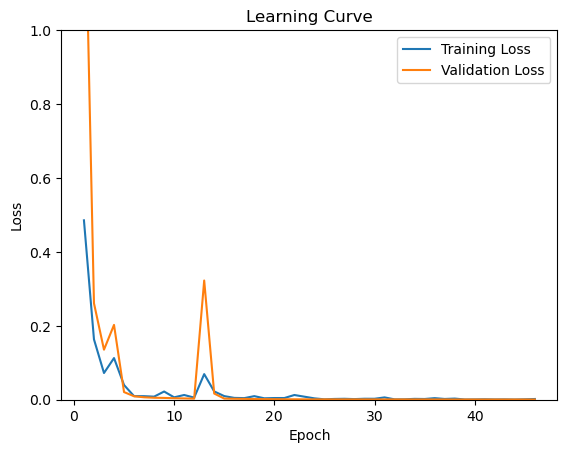

Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 1
Best epoc: 45. Best val loss: 0.003689573844894767


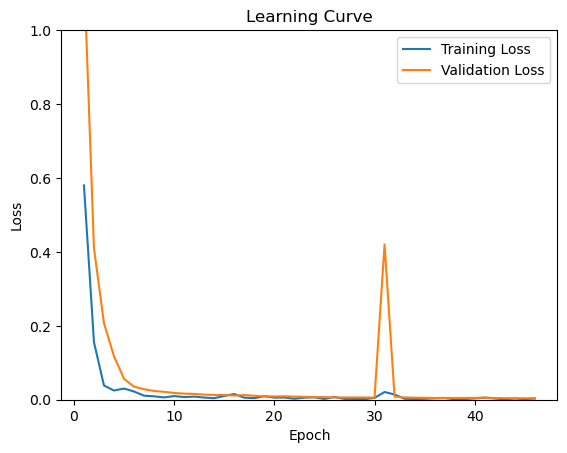

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 39. Best val loss: 0.0010518493363633752


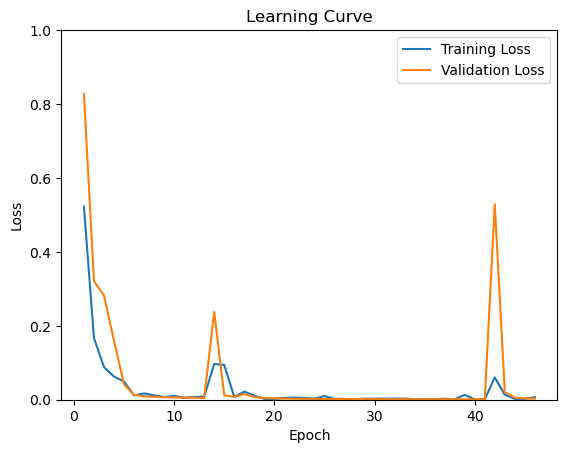

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 42. Best val loss: 0.0009596931631676853


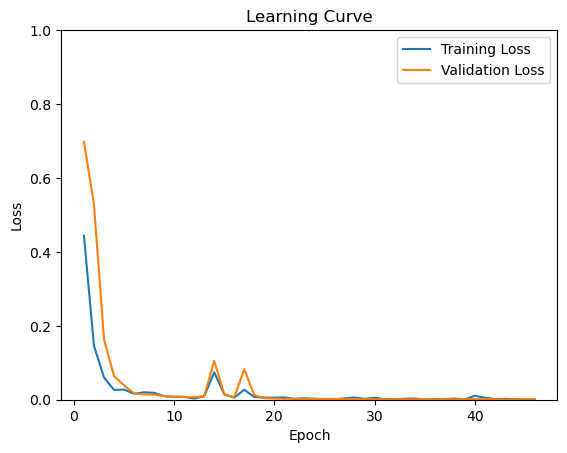

Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 4
Best epoc: 44. Best val loss: 0.0013893081340938807


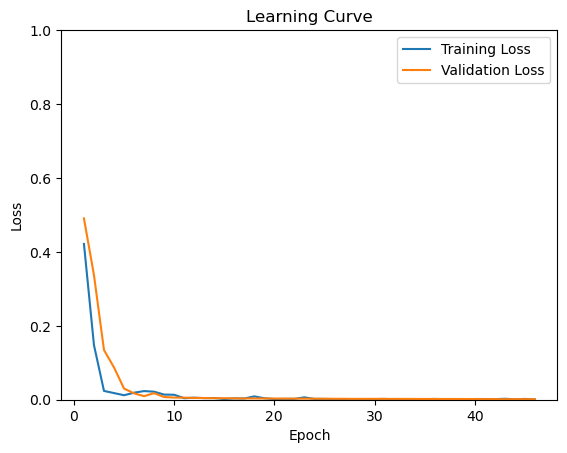

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 0
Best epoc: 45. Best val loss: 0.0008125070598907769


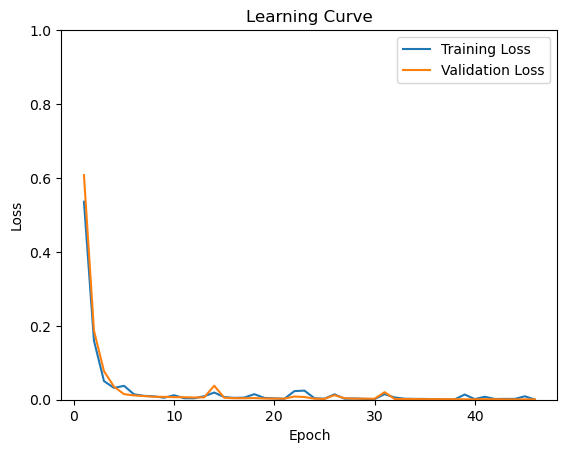

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 45. Best val loss: 0.0005391584127210081


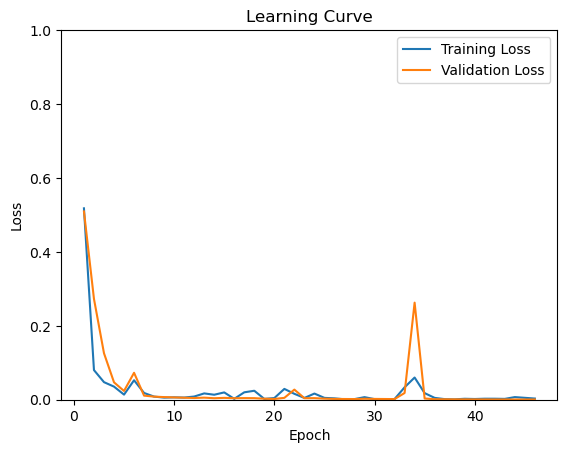

Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 2
Best epoc: 45. Best val loss: 0.001161175430752337


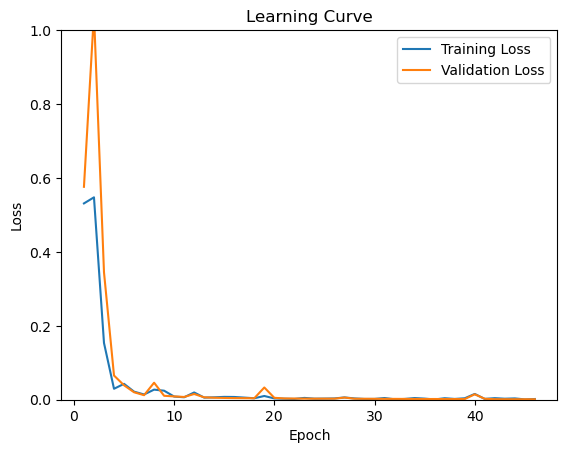

Accuracy: 0.6875. Recall: 0.75. Precision: 0.6666666666666666
Fold 3
Best epoc: 41. Best val loss: 0.0017672082176432014


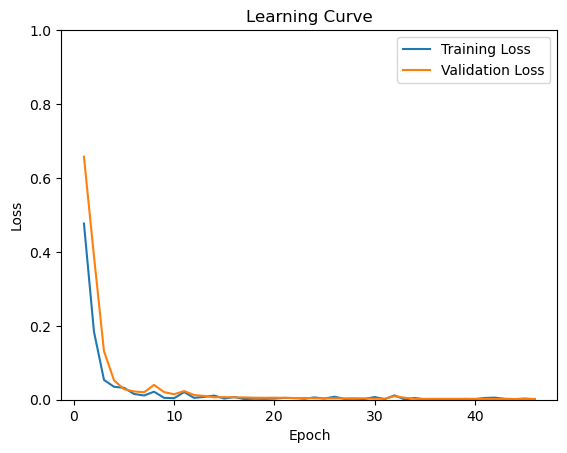

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 44. Best val loss: 0.0038177825044840574


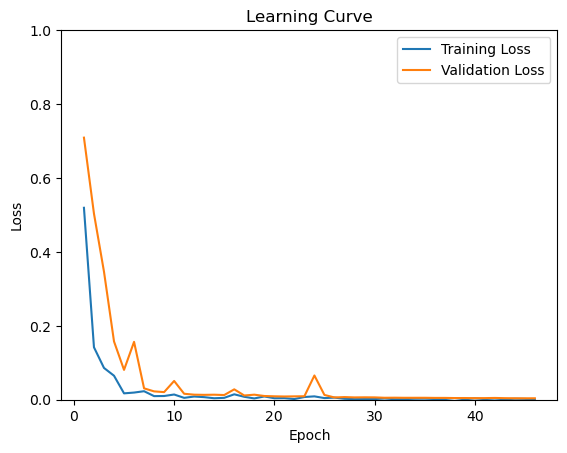

Accuracy: 0.6875. Recall: 0.375. Precision: 1.0
Fold 0
Best epoc: 37. Best val loss: 0.1724749505519867


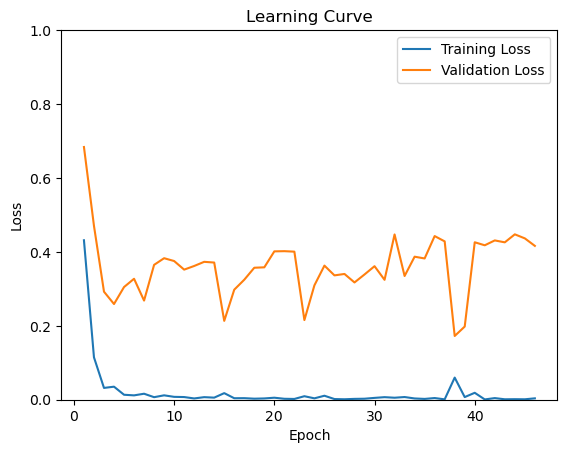

Accuracy: 0.6875. Recall: 0.375. Precision: 1.0
Fold 1
Best epoc: 44. Best val loss: 0.002533450722694397


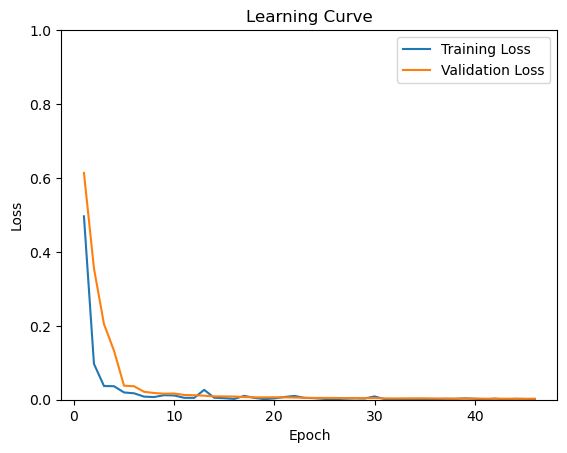

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 2
Best epoc: 44. Best val loss: 0.0010350908851251006


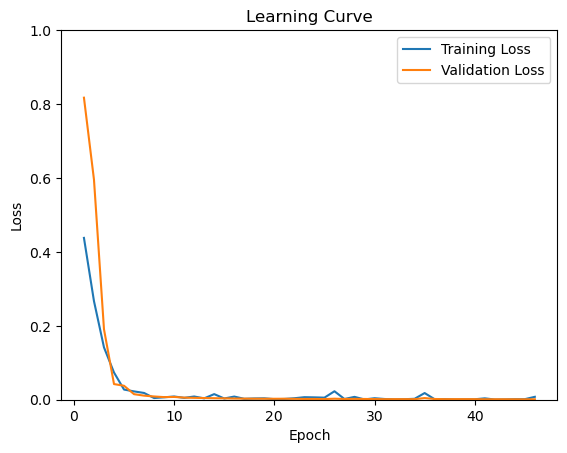

Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 3
Best epoc: 44. Best val loss: 0.000648565823212266


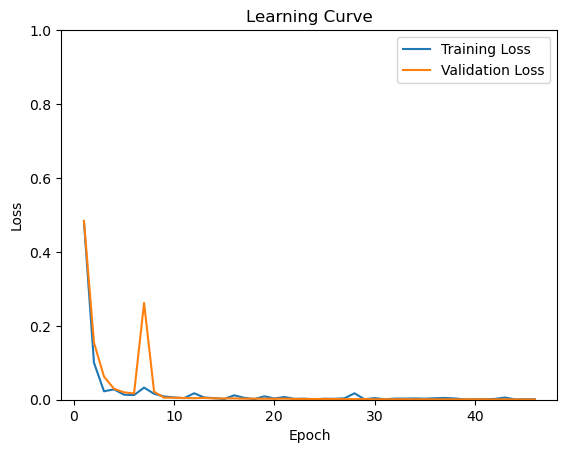

Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 4
Best epoc: 45. Best val loss: 0.0016492822906002402


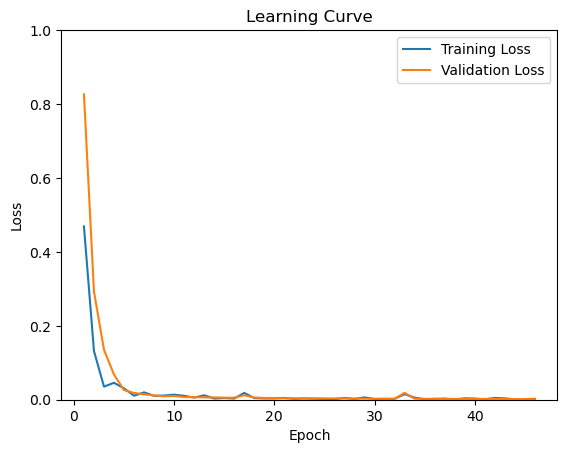

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 0
Best epoc: 45. Best val loss: 0.0012953511904925108


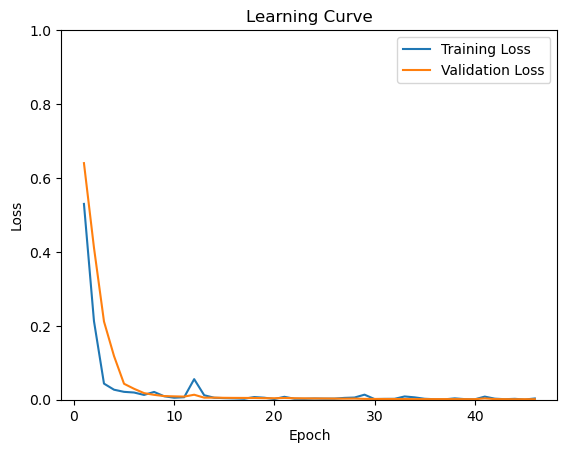

Accuracy: 0.875. Recall: 1.0. Precision: 0.8
Fold 1
Best epoc: 45. Best val loss: 0.001519586774520576


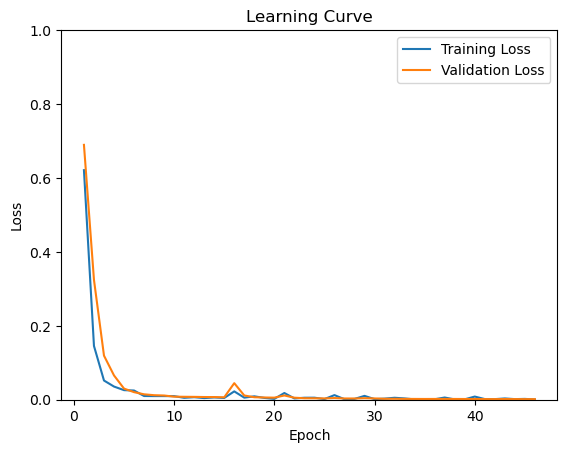

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 45. Best val loss: 0.0015269983559846878


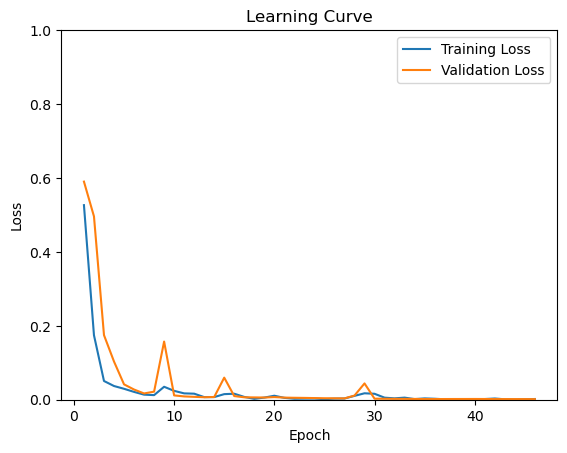

Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 3
Best epoc: 39. Best val loss: 0.0034794865641742945


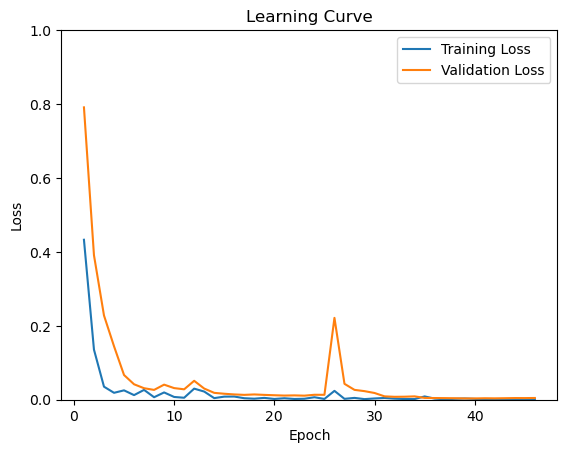

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 43. Best val loss: 0.002604925772175193


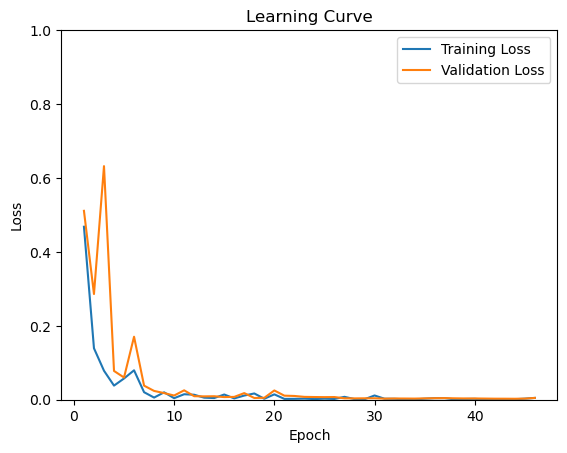

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 0
Best epoc: 44. Best val loss: 0.0014402546221390367


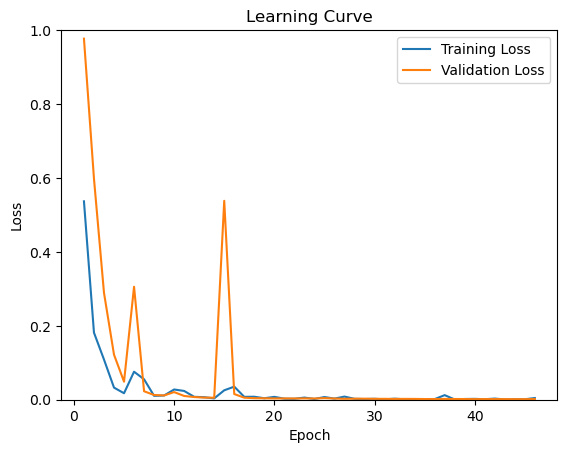

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 44. Best val loss: 0.001344536547549069


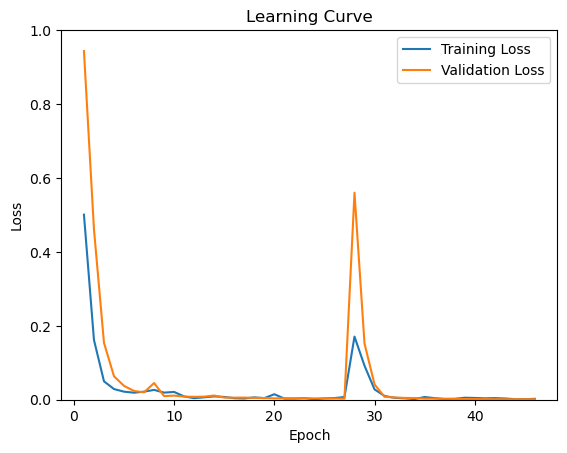

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 45. Best val loss: 0.0006494995905086398


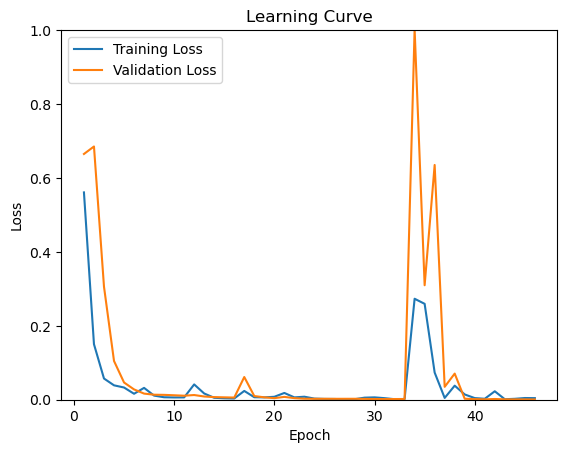

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 45. Best val loss: 0.0015060227597132325


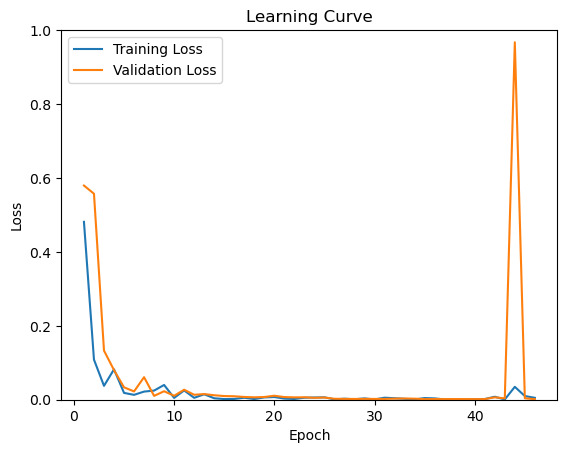

Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 45. Best val loss: 0.003857427043840289


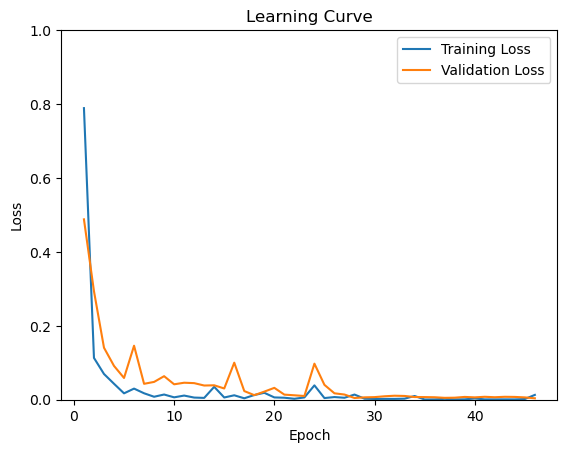

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
ACCS: [0.8125, 0.7375, 0.75, 0.8375, 0.85]
RECS: [0.75, 0.65, 0.6, 0.775, 0.75]
PRECS: [0.8678571428571429, 0.819047619047619, 0.8857142857142858, 0.8980952380952381, 0.9428571428571428]
F1S: [0.804635761589404, 0.7247974068071312, 0.7153846153846154, 0.8320193539205919, 0.8354430379746834]
STD-ACC: [0.03952847075210474, 0.06123724356957946, 0.07905694150420949, 0.06373774391990981, 0.08477912478906585]
STD-REC: [0.07905694150420949, 0.1457737973711325, 0.1224744871391589, 0.1457737973711325, 0.15811388300841897]
STD-PREC: [0.07953949089757174, 0.11818736805705578, 0.13997084244475302, 0.08516224345184058, 0.06998542122237654]
ACC: 0.7975
0.04568916720624265
0.05211367972529019
RECALL: 0.705
PRECISION: 0.8827142857142858
F1: 0.7824560351352852
STD-ACC: 0.06566790490697387
STD-REC: 0.13023858127881047
STD-PREC: 0.09856907321471954


In [8]:
accs = []
recs = []
precs = []
f1 = []
std_accs = []
std_recs = []
std_precs = []
seeds = random.sample(range(1,10001), 100)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
for i in range(5):
    acc, rec, prec, std_acc, std_rec, std_prec = prueba_k_fold_resnet_no_pre_impr_fin(df_mean_a_2, 5, 46, optim.SGD, 16, 0.013524164119342274, False, 'O', seeds[0], seeds_tr[0])
    accs.append(acc)
    recs.append(rec)
    precs.append(prec)
    std_accs.append(std_acc)
    std_recs.append(std_rec)
    std_precs.append(std_prec)
    f1.append(2*(rec*prec)/(rec+prec))
    seeds.pop(0)
    seeds_tr.pop(0)

print(f"ACCS: {accs}")
print(f"RECS: {recs}")
print(f"PRECS: {precs}")
print(f"F1S: {f1}")

print(f"STD-ACC: {std_accs}")
print(f"STD-REC: {std_recs}")
print(f"STD-PREC: {std_precs}")

print(f"ACC: {np.mean(accs)}")
print(np.std(accs))
print(np.std(f1))
print(f"RECALL: {np.mean(recs)}")
print(f"PRECISION: {np.mean(precs)}")
print(f"F1: {np.mean(f1)}")
print(f"STD-ACC: {np.mean(std_accs)}")
print(f"STD-REC: {np.mean(std_recs)}")
print(f"STD-PREC: {np.mean(std_precs)}")

Fold 0
Best epoc: 44. Best val loss: 0.0004936965997330844


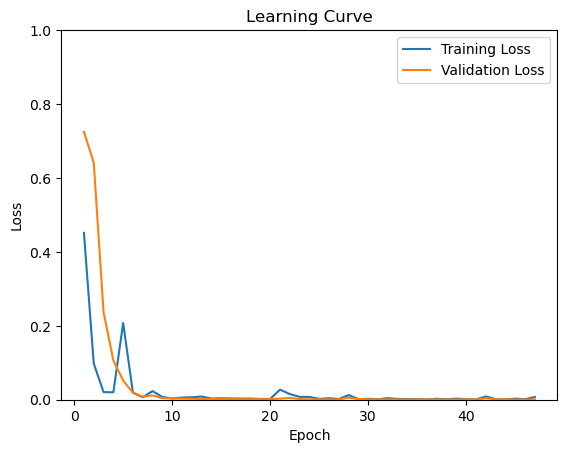

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 1
Best epoc: 46. Best val loss: 0.0009452915983274579


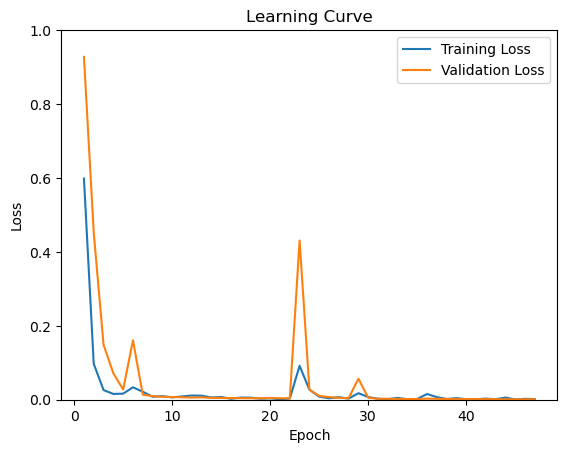

Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 2
Best epoc: 42. Best val loss: 0.0021448980551213026


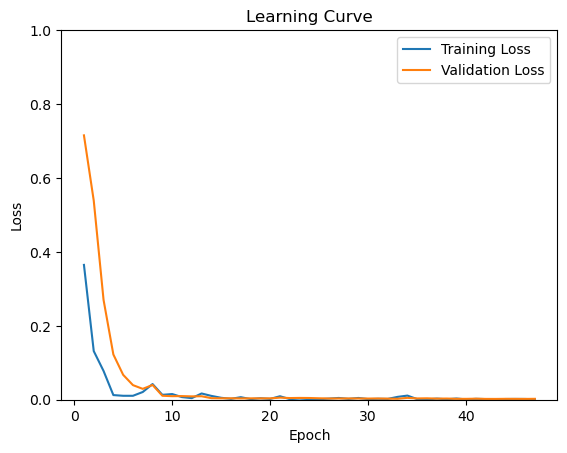

Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 42. Best val loss: 0.0031571784056723118


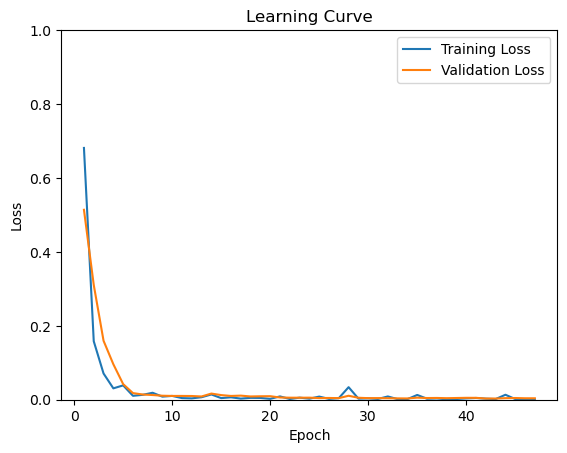

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 4
Best epoc: 42. Best val loss: 0.0008243003976531327


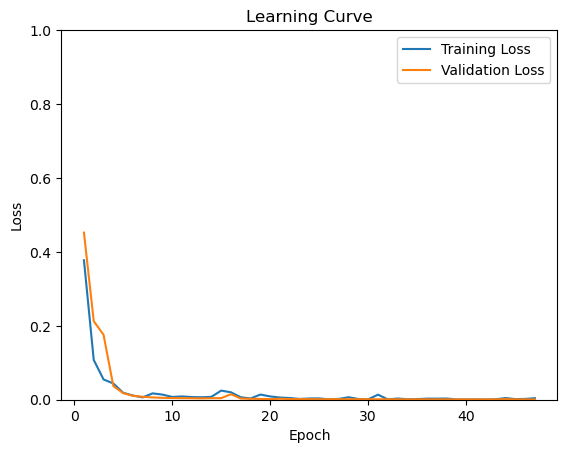

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 0
Best epoc: 38. Best val loss: 0.0030220437329262495


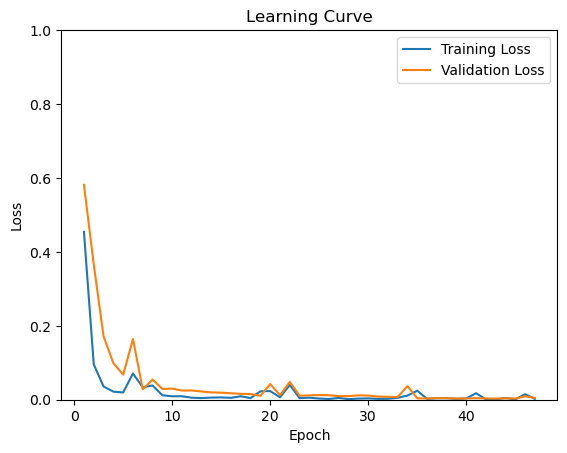

Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 1
Best epoc: 45. Best val loss: 0.0029011399019509554


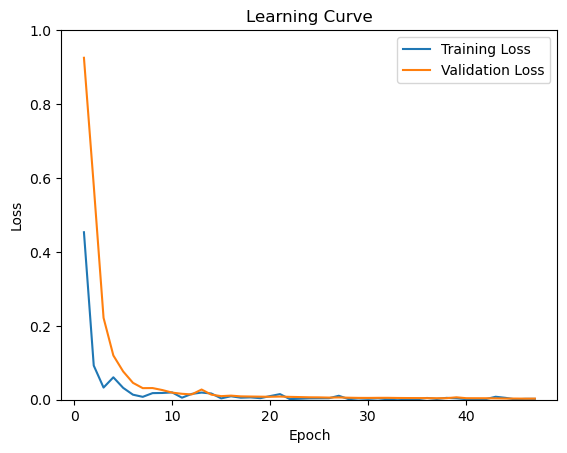

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 43. Best val loss: 0.002666635438799858


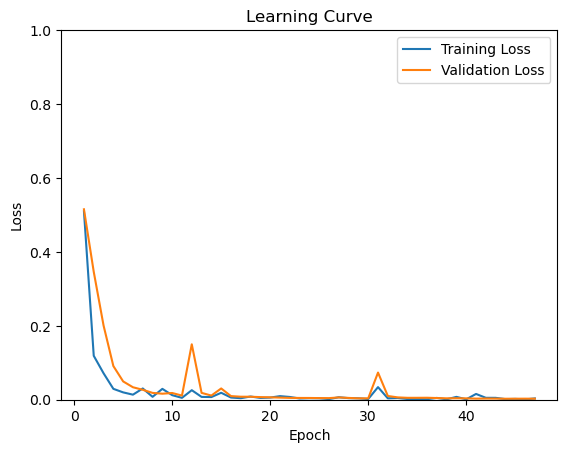

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 43. Best val loss: 0.0017372837755829096


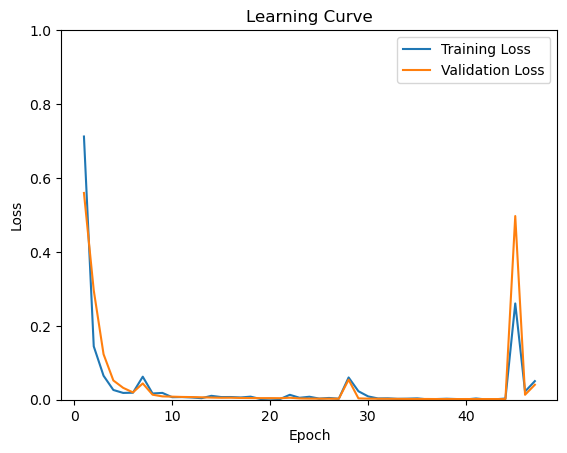

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 39. Best val loss: 0.0012616722378879786


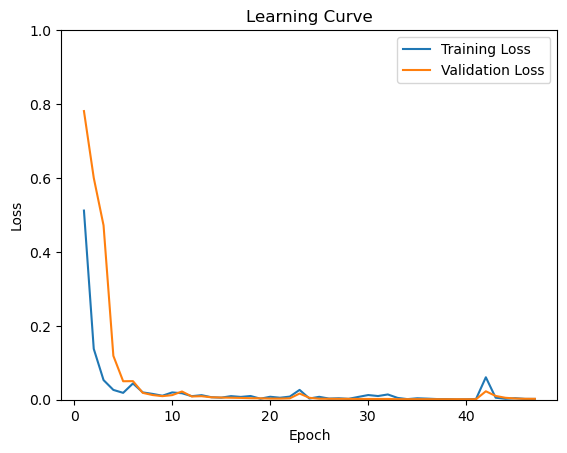

Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 0
Best epoc: 46. Best val loss: 0.0008611118537373841


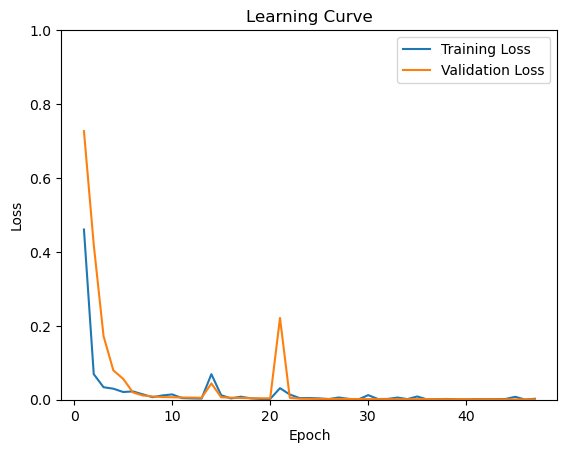

Accuracy: 0.6875. Recall: 0.375. Precision: 1.0
Fold 1
Best epoc: 46. Best val loss: 0.0012698527425527573


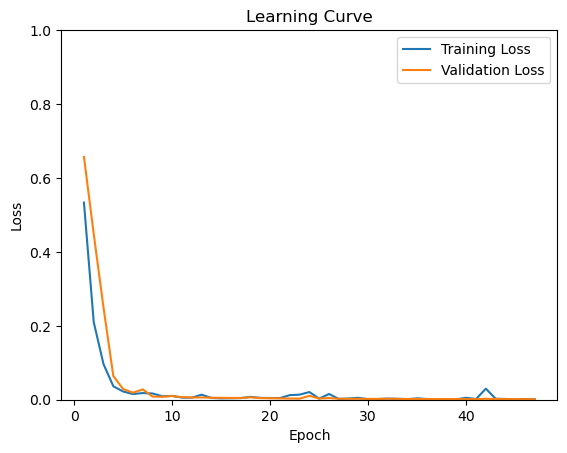

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 46. Best val loss: 0.0020640783477574587


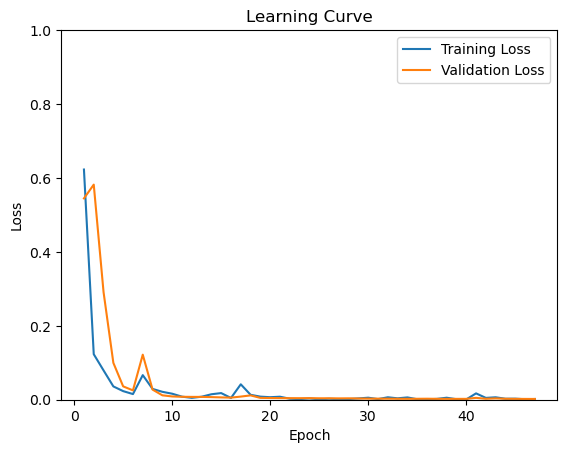

Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 3
Best epoc: 44. Best val loss: 0.0022972167935222387


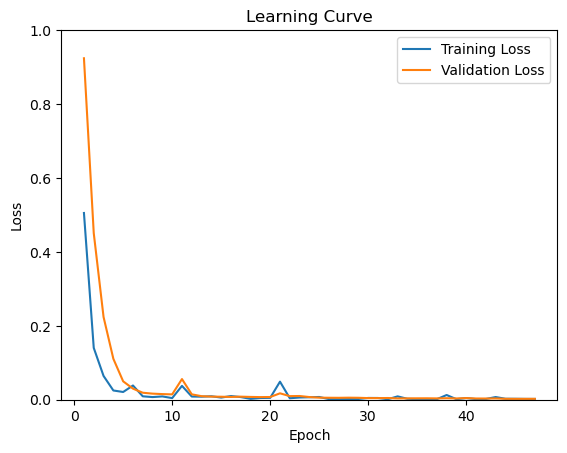

Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 4
Best epoc: 45. Best val loss: 0.0020419536158442497


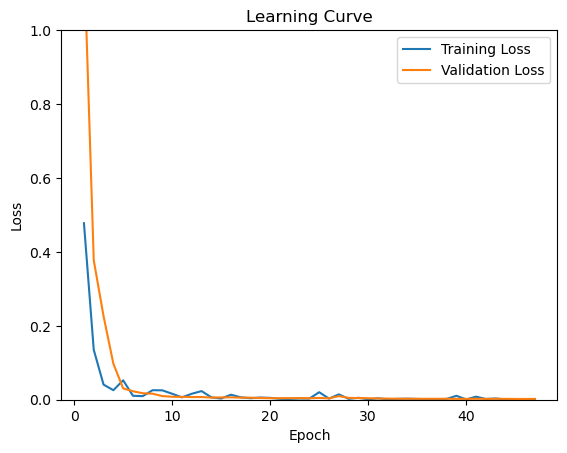

Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 0
Best epoc: 38. Best val loss: 0.003271604422479868


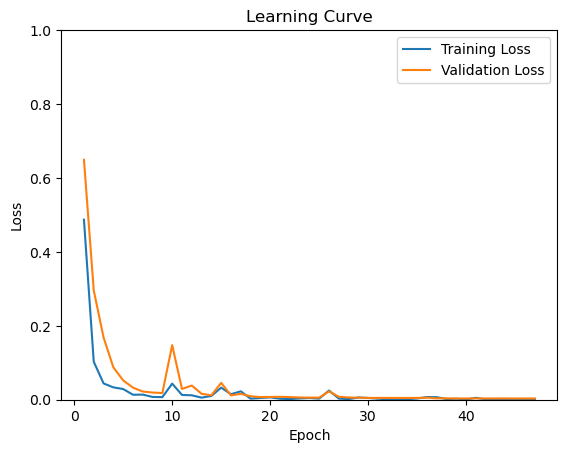

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 43. Best val loss: 0.0011706628138199449


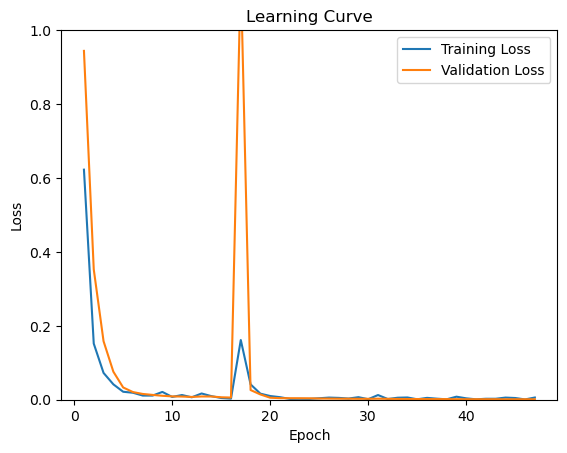

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 46. Best val loss: 0.0009577451273798943


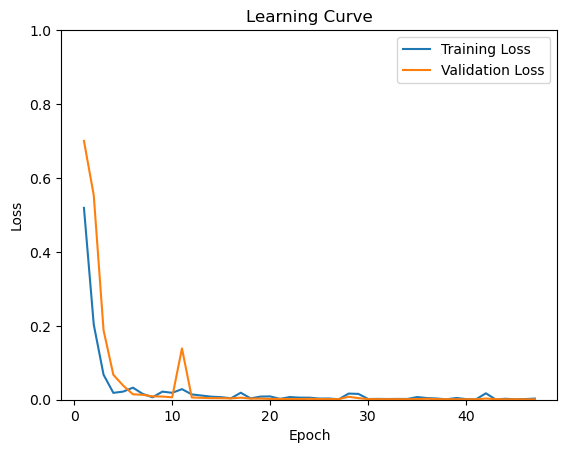

Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 46. Best val loss: 0.0007038993062451482


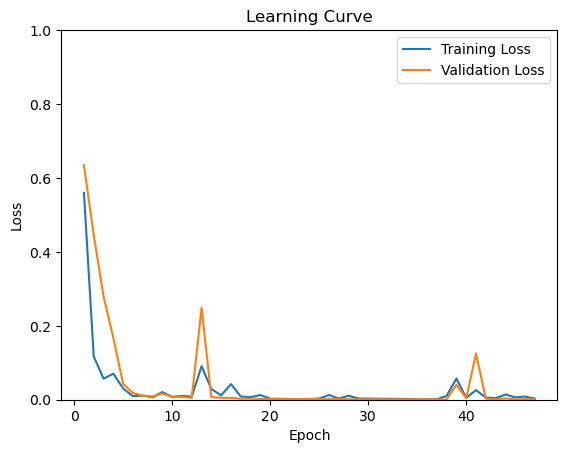

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 44. Best val loss: 0.0021849118638783693


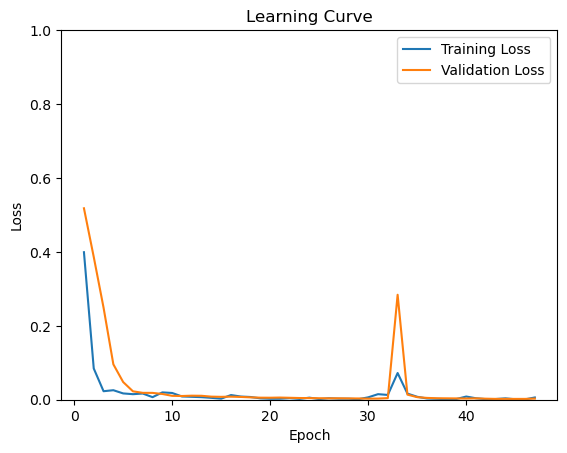

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 0
Best epoc: 46. Best val loss: 0.00306023471057415


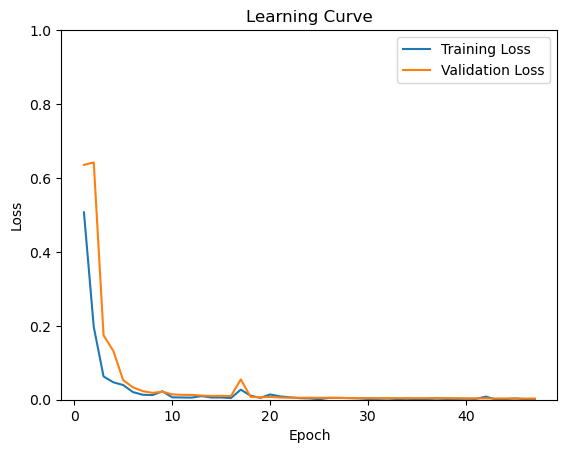

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 45. Best val loss: 0.0015990959946066141


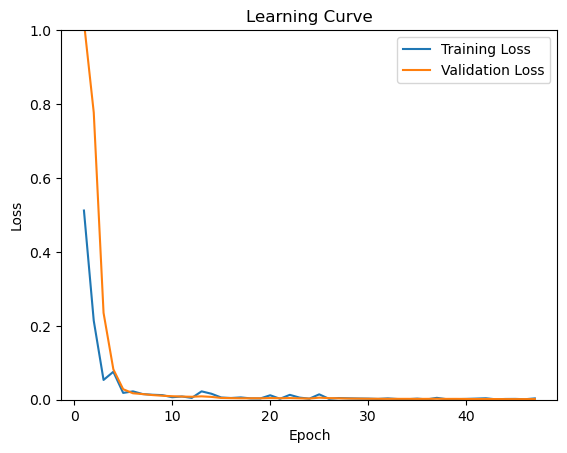

Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 2
Best epoc: 46. Best val loss: 0.0027009437326341867


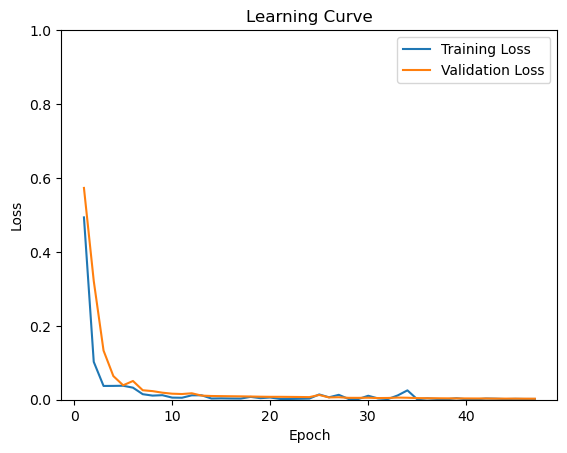

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 46. Best val loss: 0.0024316133931279182


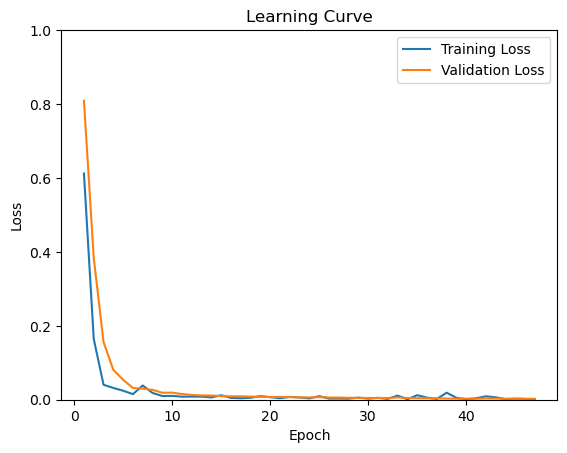

Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 4
Best epoc: 43. Best val loss: 0.0033888849429786205


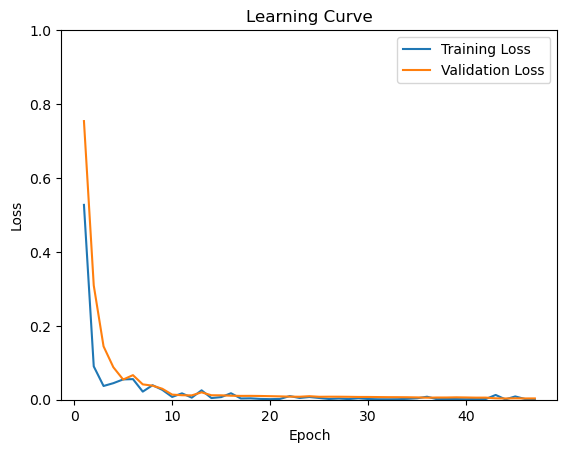

Accuracy: 0.75. Recall: 0.875. Precision: 0.7
ACCS: [0.775, 0.8625, 0.8, 0.8375, 0.8375]
RECS: [0.675, 0.8, 0.75, 0.75, 0.825]
PRECS: [0.8603174603174603, 0.9178571428571429, 0.8575396825396826, 0.9214285714285714, 0.8578571428571429]
F1S: [0.7564745412251228, 0.854885654885655, 0.8001727968402864, 0.826923076923077, 0.8411078098471986]
STD-ACC: [0.030618621784789725, 0.046770717334674264, 0.06123724356957945, 0.049999999999999996, 0.06373774391990981]
STD-REC: [0.1274754878398196, 0.06123724356957945, 0.19364916731037085, 0.0, 0.06123724356957946]
STD-PREC: [0.07455249883058652, 0.06738557951469004, 0.08163808560910696, 0.10202040612204072, 0.0953083074521196]
ACC: 0.8225
0.031024184114977142
0.03480101275168804
RECALL: 0.76
PRECISION: 0.883
F1: 0.8159127759442679
STD-ACC: 0.05047286532179065
STD-REC: 0.08871982845786987
STD-PREC: 0.08418097550570877


In [9]:
accs = []
recs = []
precs = []
f1 = []
std_accs = []
std_recs = []
std_precs = []
seeds = random.sample(range(1,10001), 100)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
for i in range(5):
    acc, rec, prec, std_acc, std_rec, std_prec = prueba_k_fold_resnet_no_pre_impr_fin(df_mean_a_2, 5, 47, optim.SGD, 16, 0.008455809379834926, False, 'G', seeds[0], seeds_tr[0])
    accs.append(acc)
    recs.append(rec)
    precs.append(prec)
    std_accs.append(std_acc)
    std_recs.append(std_rec)
    std_precs.append(std_prec)
    f1.append(2*(rec*prec)/(rec+prec))
    seeds.pop(0)
    seeds_tr.pop(0)

print(f"ACCS: {accs}")
print(f"RECS: {recs}")
print(f"PRECS: {precs}")
print(f"F1S: {f1}")

print(f"STD-ACC: {std_accs}")
print(f"STD-REC: {std_recs}")
print(f"STD-PREC: {std_precs}")

print(f"ACC: {np.mean(accs)}")
print(np.std(accs))
print(np.std(f1))
print(f"RECALL: {np.mean(recs)}")
print(f"PRECISION: {np.mean(precs)}")
print(f"F1: {np.mean(f1)}")
print(f"STD-ACC: {np.mean(std_accs)}")
print(f"STD-REC: {np.mean(std_recs)}")
print(f"STD-PREC: {np.mean(std_precs)}")

### CON TL SIN OC

In [10]:

def accuracy(outputs, labels):
    
    correct = (outputs == labels)  # Compara las predicciones con las etiquetas reales
    
    acc = sum(correct) / len(labels)  # Calcula la precisión
    return acc

def recall(outputs, labels):
    
    TP = sum((outputs == 1) & (labels == 1))
    FN = sum((outputs == 0) & (labels == 1))

    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
   
    return recall_score

def precision(outputs, labels):

    TP = sum((outputs == 1) & (labels == 1))
    FP = sum((outputs == 1) & (labels == 0))
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    
    return precision_score



def prueba_k_fold_resnet_pre_impr_fin(dataset, num_folds_outer, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    
    directorio = './IMGS_MEDIA_AMPL_2'
    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    ##Por otro lado, la parte de train, se verá otra vez sometida a un kfold, 

    for i in range(num_folds_outer):
        print(f"Fold {i}")
        # Vector de pacientes y de 2 strings
        pacientes = [f'{i:02}' for i in range(2, 76)]
        strings = ['HVN', 'H9O']
        # Número de combinaciones que deseas crear
        num_combinaciones = 16
        combinaciones_totales = 0
        total_negativo = 0
        total_positivo = 0
        # Lista para almacenar las combinaciones
        combinaciones = []

        random.seed(seeds_tr_split[i])

        
         # Obtener la lista de nombres de archivos que coinciden con la expresión regular
        nombres_de_archivos_mal = dataset['Ruta']  # Reemplaza '*' con el directorio o patrón adecuado si es necesario
        nombres_de_archivos_mal = nombres_de_archivos_mal.to_list()

        nombres_de_archivos = [s.split("2\\")[1] for s in nombres_de_archivos_mal]
        # Dividir el conjunto de datos en entrenamiento y validación para este fold

        while combinaciones_totales < num_combinaciones:
            # Seleccionar un paciente aleatorio

            paciente_aleatorio = random.choice(pacientes)

            # Seleccionar un string aleatorio
            string_aleatorio = random.choice(strings)

            # Expresión regular para filtrar nombres de archivos
            expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

            # Filtrar los nombres de archivos que coinciden con la expresión regular
            archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]
            
            if (len(archivos_coincidentes) == 4):
                etiqueta = int(archivos_coincidentes[0].split("_")[3][0])
                if(etiqueta % 2 == 0):
                    if (total_positivo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_positivo += 1
                else:
                    if (total_negativo < 8):
                        combinaciones.extend(archivos_coincidentes)
                        combinaciones_totales += 1
                        pacientes.remove(paciente_aleatorio)
                        total_negativo += 1
                    
                
        data = []
        directorio_absoluto = os.path.abspath(directorio)
        # Iterar sobre los archivos
        for archivo in combinaciones:
            # Obtener la ruta completa del archivo
            ruta_completa = os.path.join(directorio_absoluto, archivo)
            # Obtener los elementos después de hacer split("_")
            elementos = archivo.split("_")
            # Obtener la etiqueta (cuarto elemento)
            etiqueta = elementos[3] if len(elementos) >= 4 else None
            # Agregar la ruta y la etiqueta a la lista de datos
            etiqueta = etiqueta[0]
            # print(etiqueta)
            data.append((ruta_completa, int(etiqueta)))

            nombres_de_archivos.remove(archivo)

    
        # Crear el DataFrame de Pandas
        test_data_fold = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

        


        train_data_fold = pd.concat([dataset, test_data_fold]).drop_duplicates(keep=False)

        
        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[i], stratify = train_data_fold['Etiqueta'])
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        ##Aqui el batch size será de la longitud del test_dataset
        ##como se usa con model eval daría un poco igual el batch size, como en validacion
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=4, shuffle=False)
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None

        train_losses_fold = []
        val_losses_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer2.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            train_losses_fold.append(avg_loss_total_acumulada)

            avg_val_loss = val_loss / len(val_loader_fold_in)
            val_losses_fold.append(avg_val_loss)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

            ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    ##La cosa sería comparar cada loss con la anterior e ir quedándote con la más baja, guardando el modelo o algo por el estilo
                    ##también se podría hacer por accuracy + recall, o hacer una ponderación de los tres
                    ###ALGO COMO
                    ################### modelo_mejor = modelo si se cumplen las características, posteriormente se hará predicción en test.
                    
                    
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            train_losses_fold.append(avg_loss_total_acumulada)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            val_losses_fold.append(avg_val_loss)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            
        
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")
        
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)
        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        preds_final = []
        labels_final = []
        with torch.no_grad():
            for images, bin_label in test_dataloader:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0

                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    preds = bin_pred > 0.5
                    bin_label = bin_label.tolist()
                    preds = preds.cpu()
                    ones = np.count_nonzero(preds == 1)

                    #Si la len es par, exige clara mayoría, si es impar, exige que haya 1 más que la mitad
                    if (ones > len(bin_label)/2):
                        preds = 1
                    else:
                        preds = 0

                    preds_final.append(preds)
                    labels_final.append(int(bin_label[0])) ##Todas las etiquetas del minibatch son iguales, se toma la primera

            
            preds_final = np.array(preds_final)
            labels_final = np.array(labels_final)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = accuracy(preds_final, labels_final)
            avg_rec = recall(preds_final, labels_final)
            avg_prec = precision(preds_final, labels_final)

            plt.figure(figsize=(8, 6))
            sns.heatmap(confusion_matrix(labels_final, preds_final), annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Pred. Negativo', 'Pred. Positivo'],
            yticklabels=['Verd. Negativo', 'Verd. Positivo'])
            plt.xlabel('Etiqueta Predicha')
            plt.ylabel('Etiqueta Verdadera')
            plt.title('Matriz de Confusión')
            plt.show()

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

        

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

Fold 0
Best epoc: 42. Best val loss: 0.002157393377274275


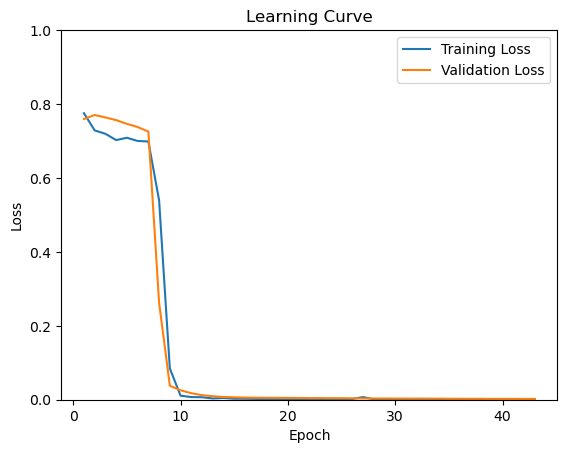

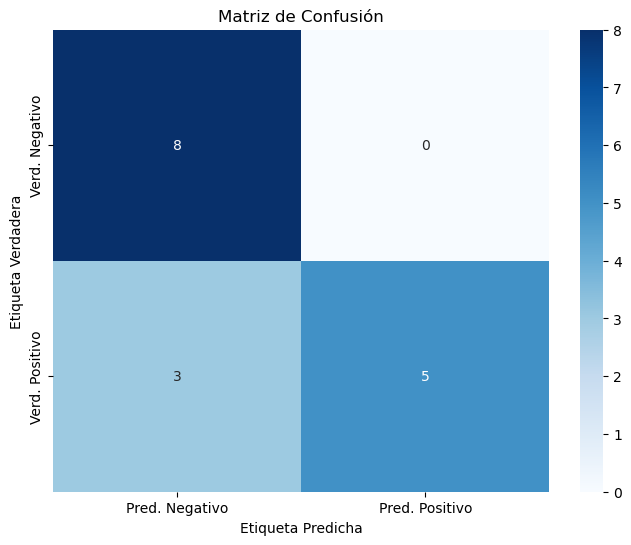

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 1
Best epoc: 41. Best val loss: 0.0019438277231529355


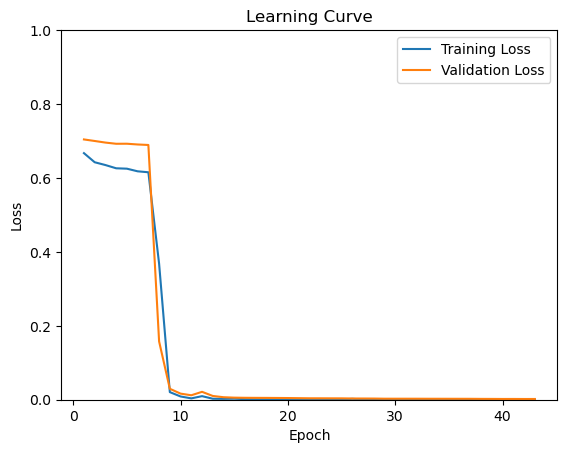

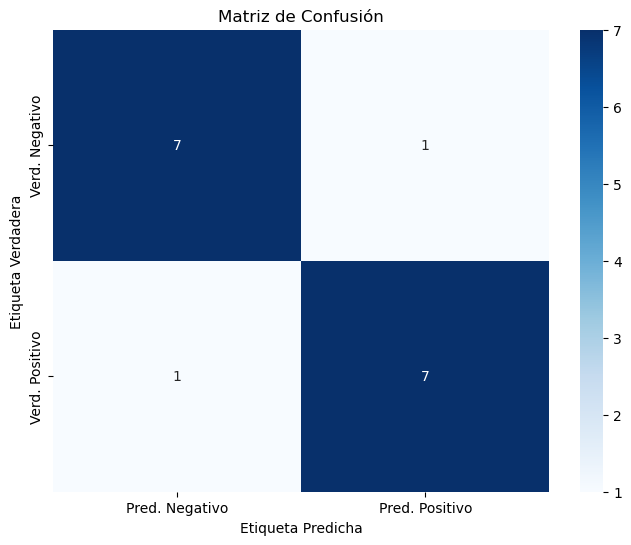

Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 2
Best epoc: 41. Best val loss: 0.00044144107960164547


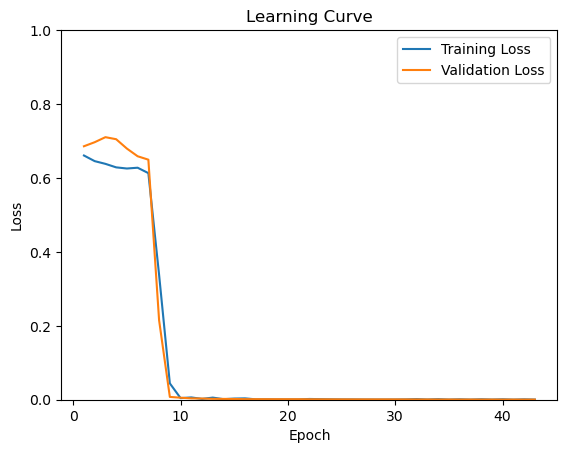

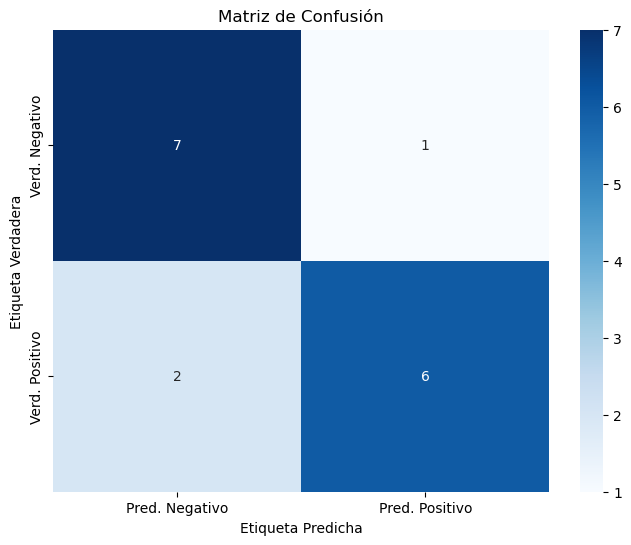

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 3
Best epoc: 42. Best val loss: 0.0007407459779642522


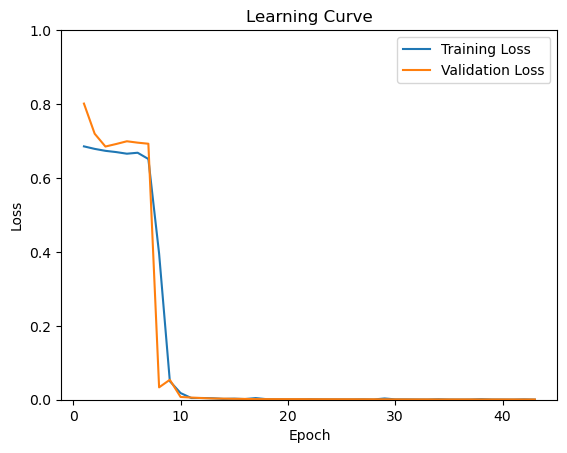

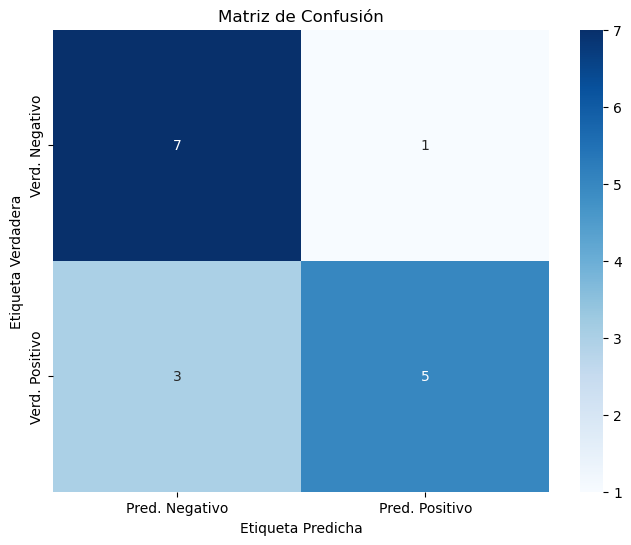

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 4
Best epoc: 42. Best val loss: 0.0009496603161096573


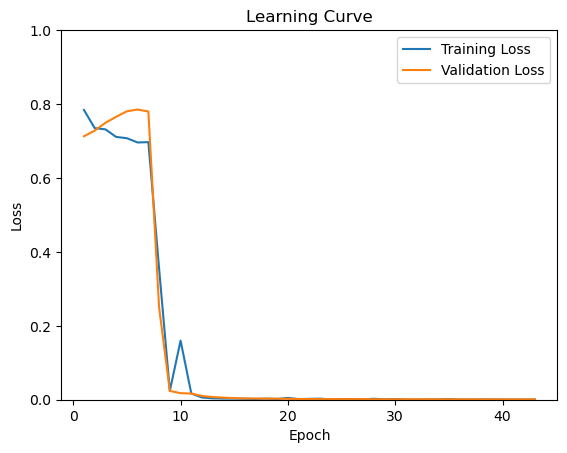

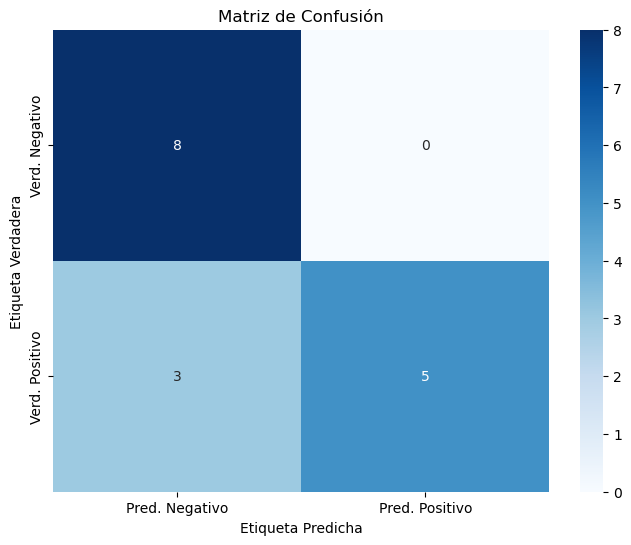

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 0
Best epoc: 38. Best val loss: 0.003135190112516284


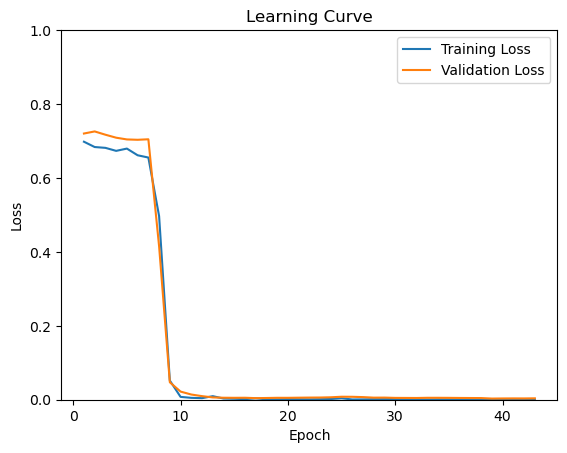

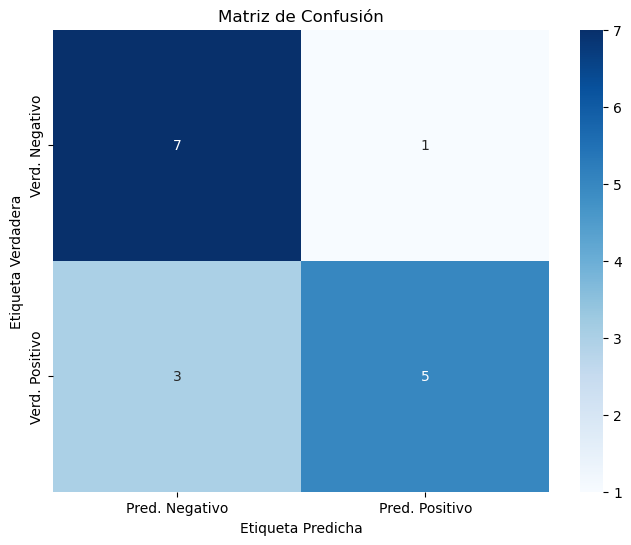

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 1
Best epoc: 41. Best val loss: 0.00048473072820343077


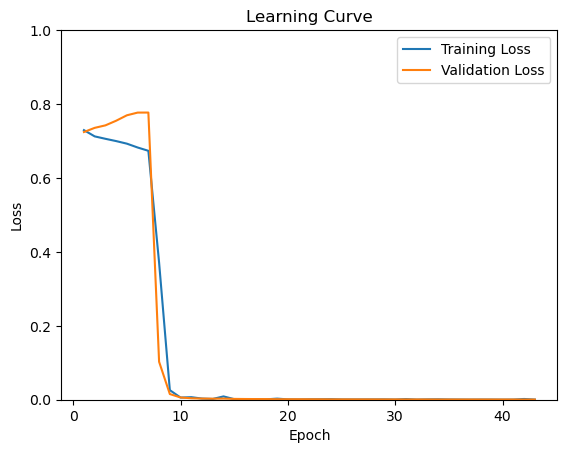

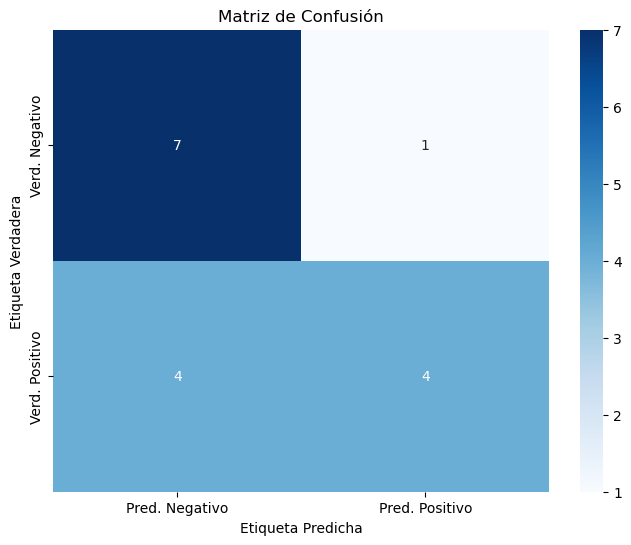

Accuracy: 0.6875. Recall: 0.5. Precision: 0.8
Fold 2
Best epoc: 42. Best val loss: 0.0010118347126990557


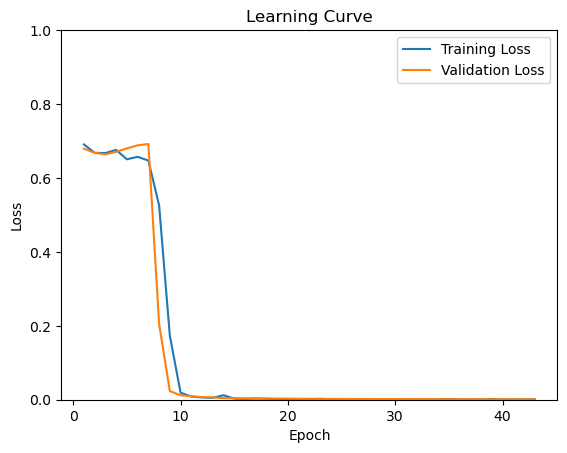

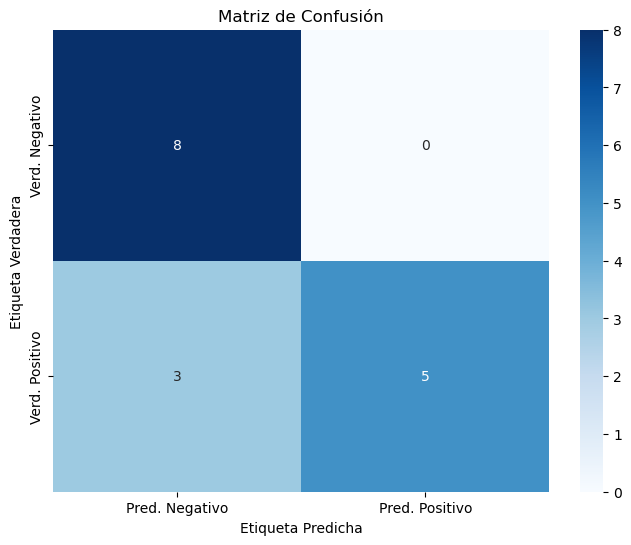

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 3
Best epoc: 42. Best val loss: 0.0004826837684959173


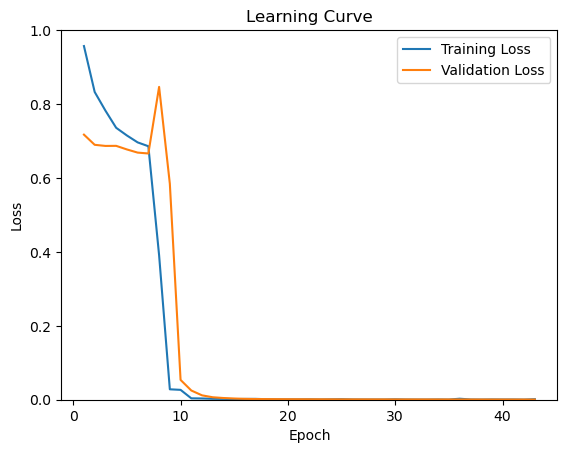

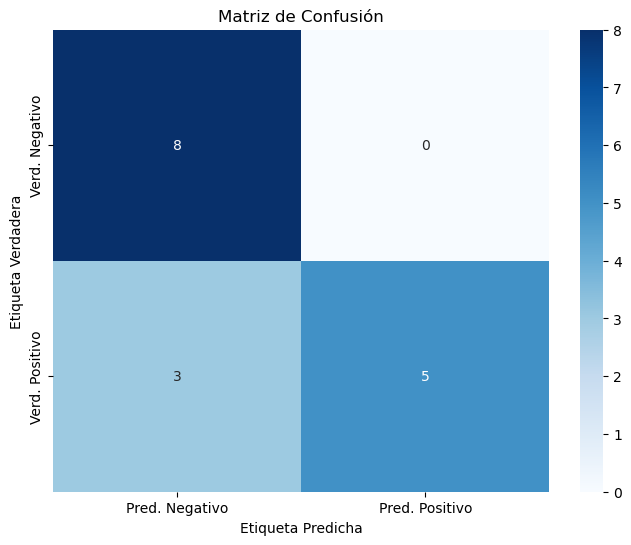

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 42. Best val loss: 0.001192512339912355


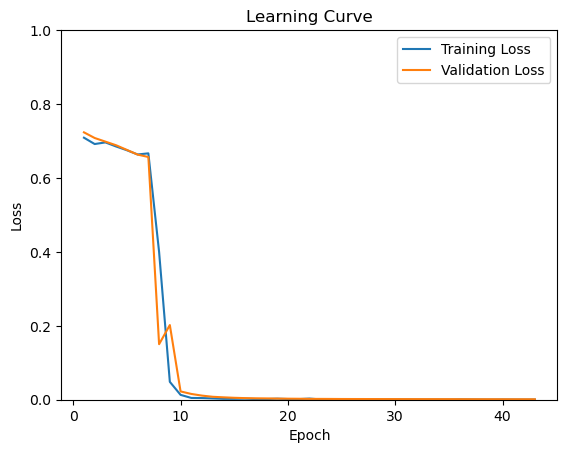

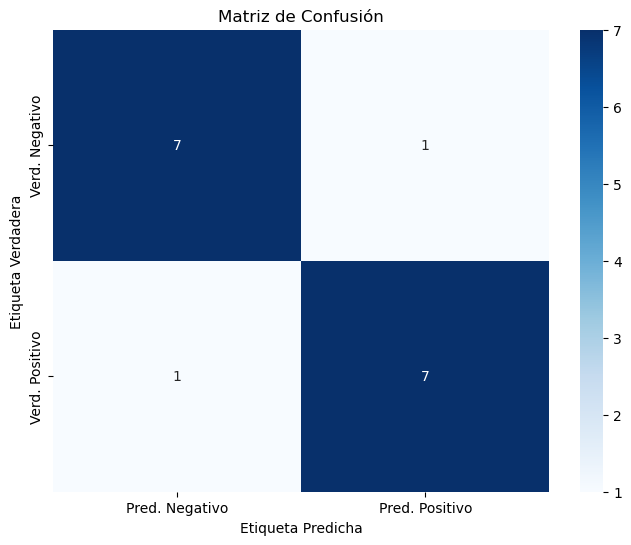

Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 0
Best epoc: 42. Best val loss: 0.0009040654404088855


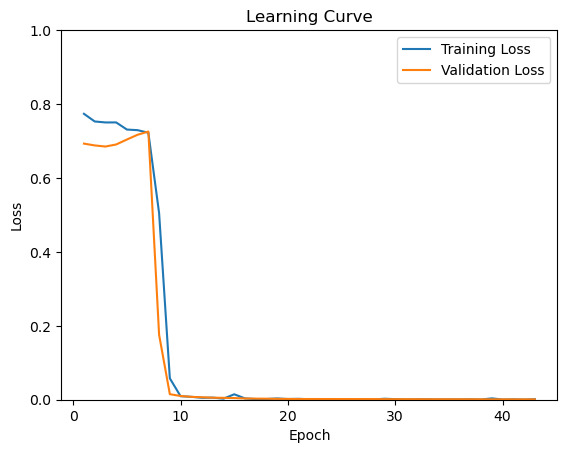

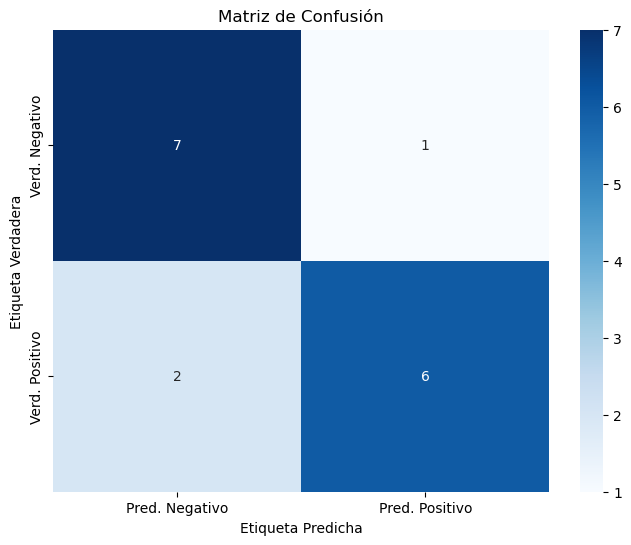

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 40. Best val loss: 0.0022085767704993486


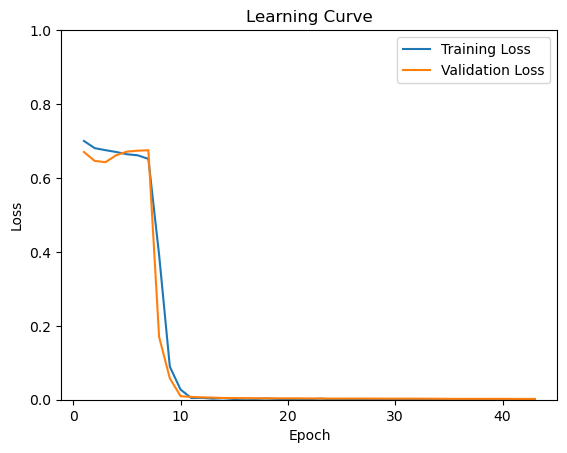

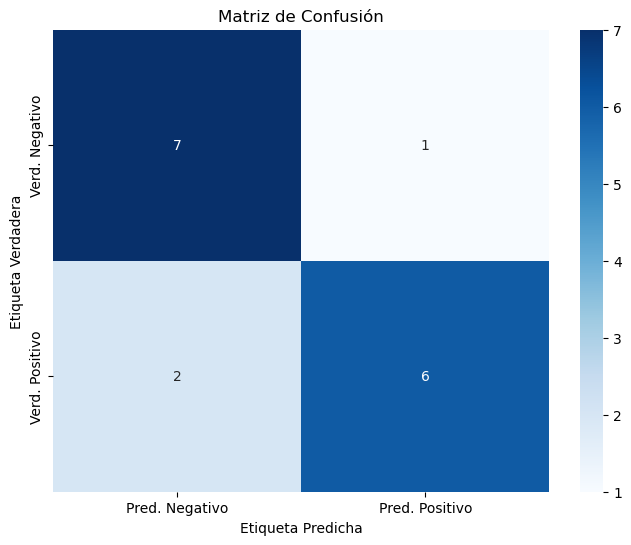

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 41. Best val loss: 0.0009593275608494878


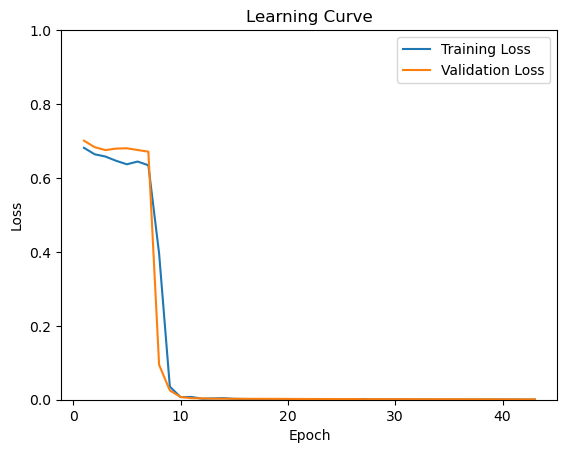

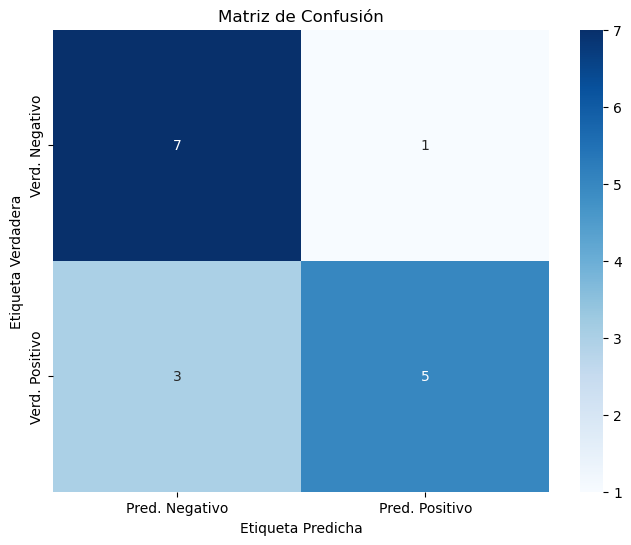

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 3
Best epoc: 36. Best val loss: 0.00035818872856907547


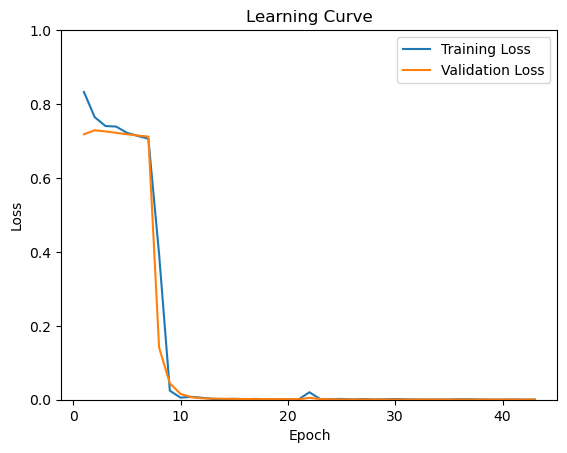

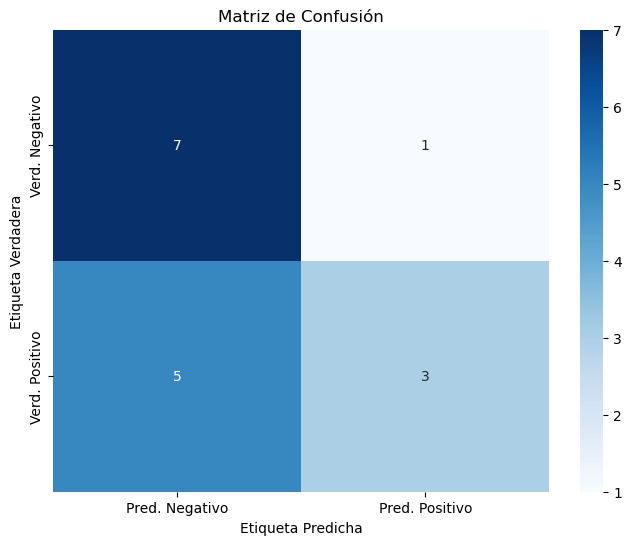

Accuracy: 0.625. Recall: 0.375. Precision: 0.75
Fold 4
Best epoc: 42. Best val loss: 0.0019040380138903856


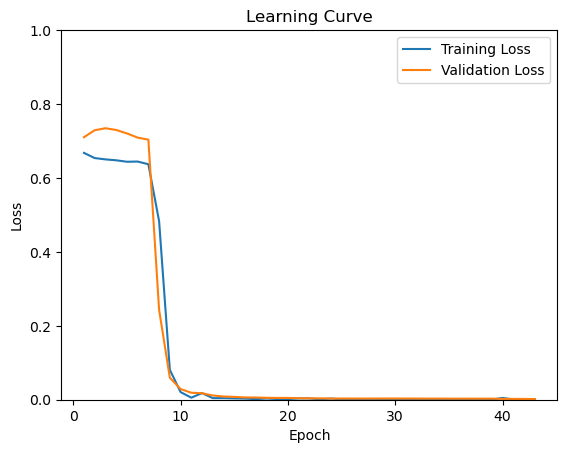

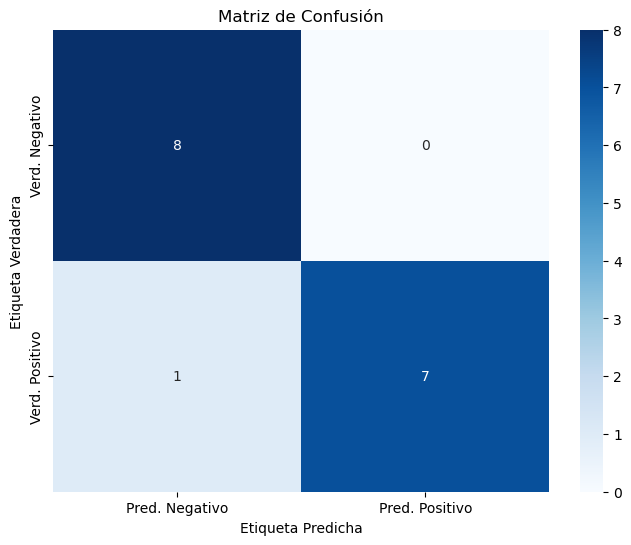

Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 0
Best epoc: 38. Best val loss: 0.0010613143676891923


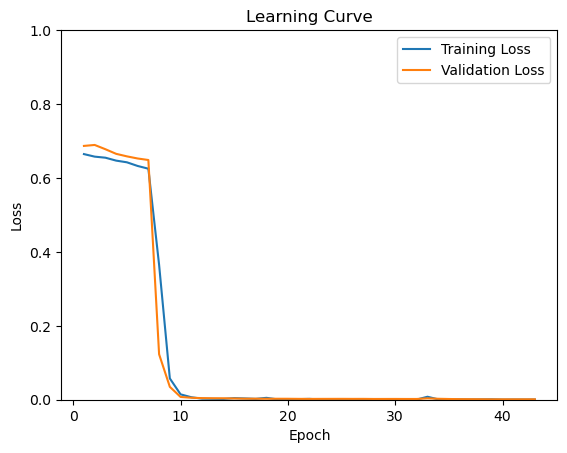

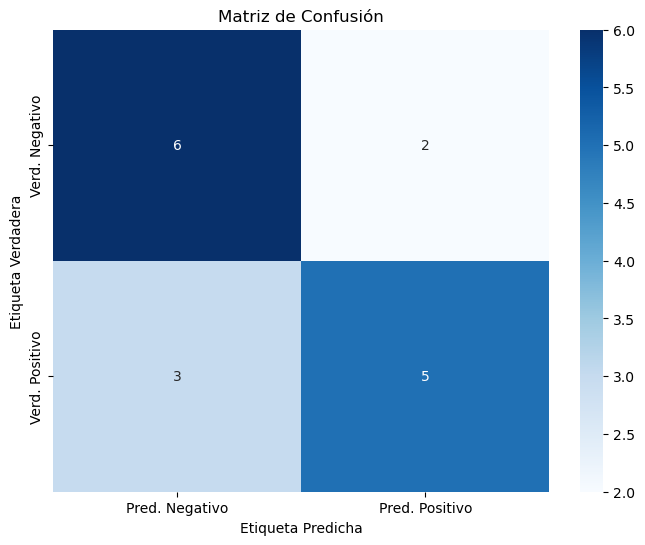

Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 1
Best epoc: 42. Best val loss: 0.0005551226786337793


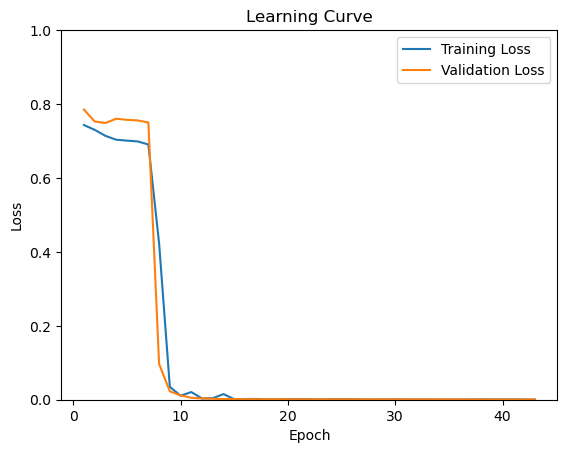

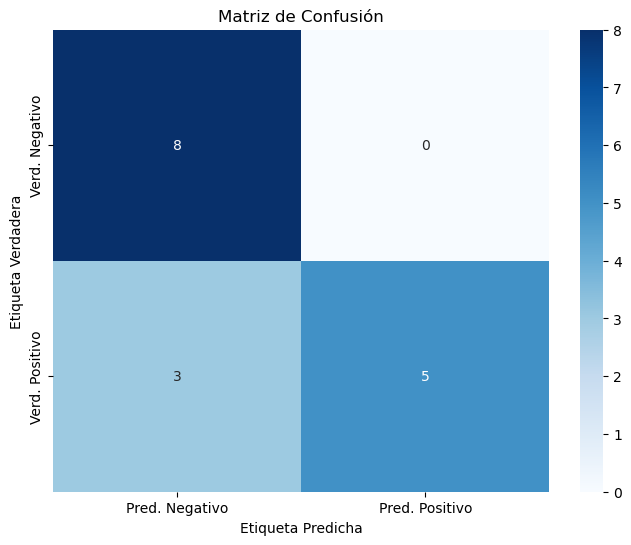

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 2
Best epoc: 36. Best val loss: 0.001495135948061943


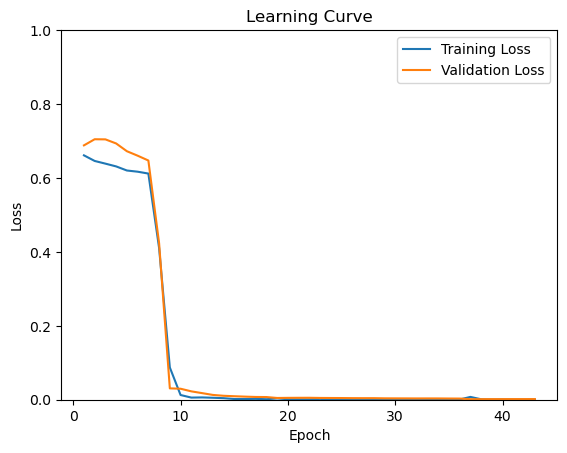

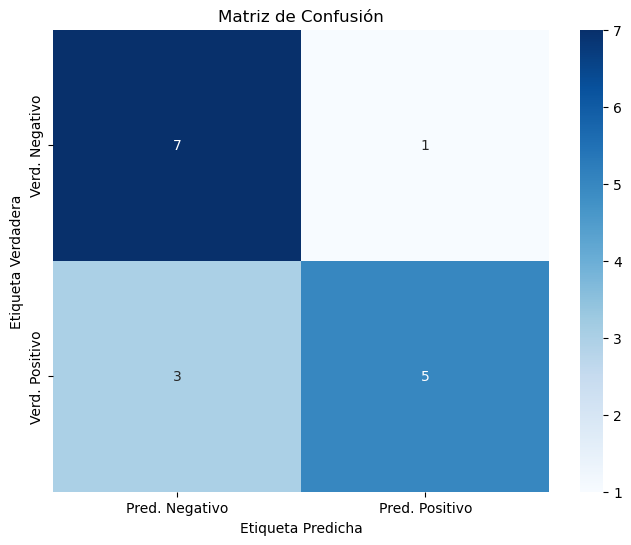

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 3
Best epoc: 39. Best val loss: 0.0012866051401942968


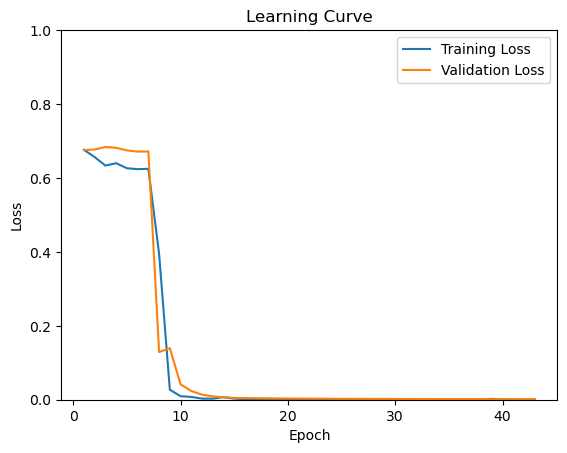

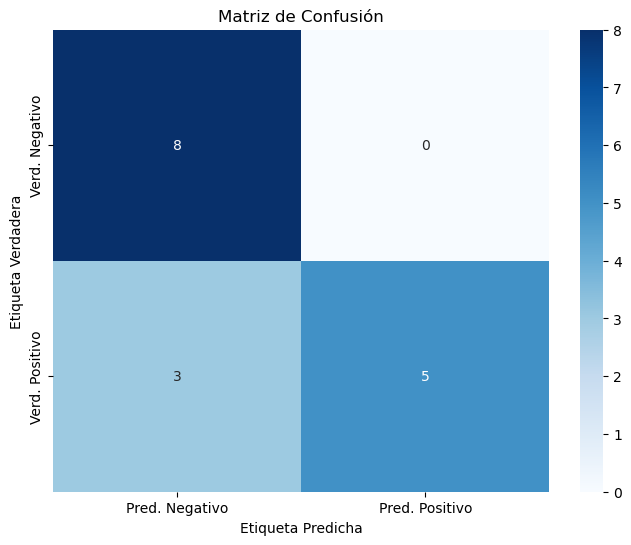

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 32. Best val loss: 0.0021266271360218525


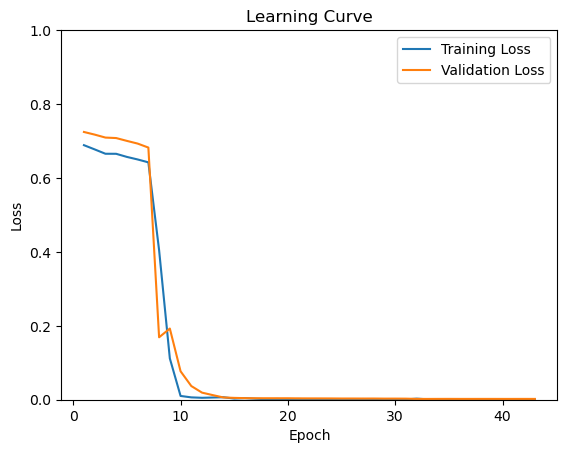

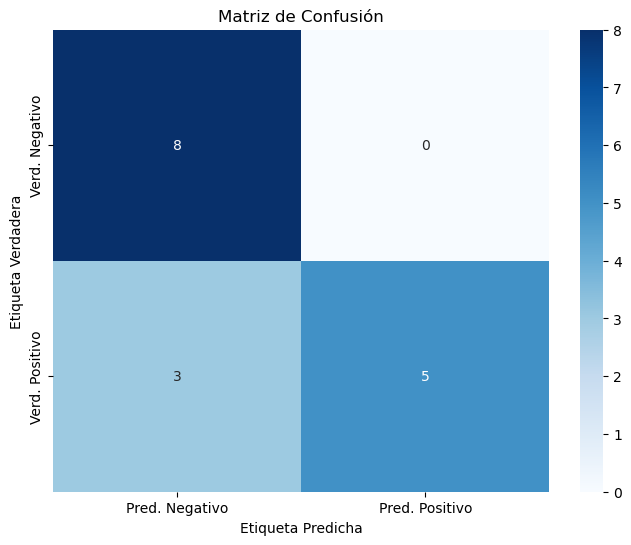

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 0
Best epoc: 42. Best val loss: 0.004094953648746014


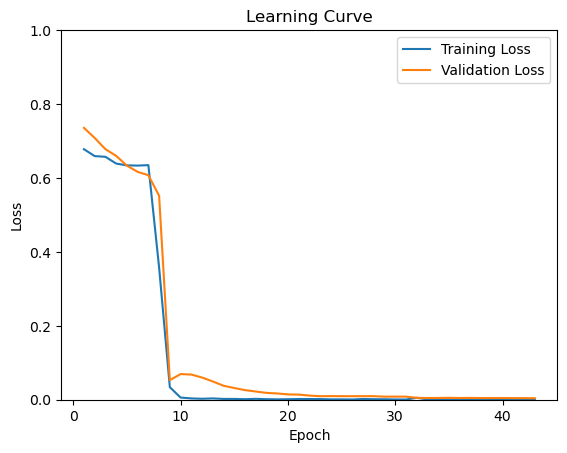

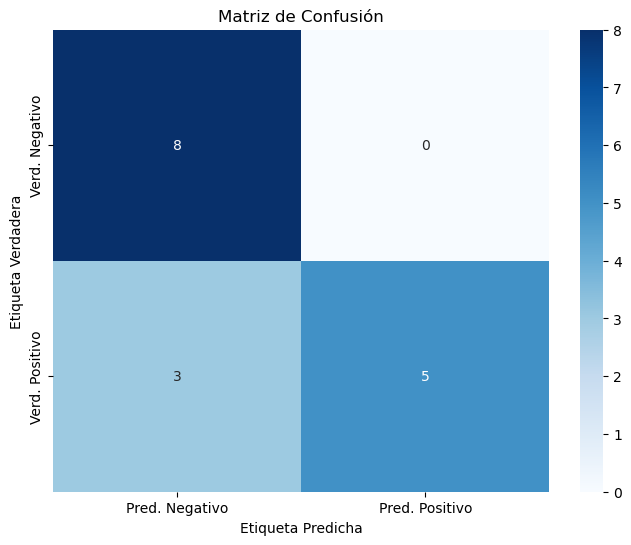

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 1
Best epoc: 42. Best val loss: 0.000545221206266433


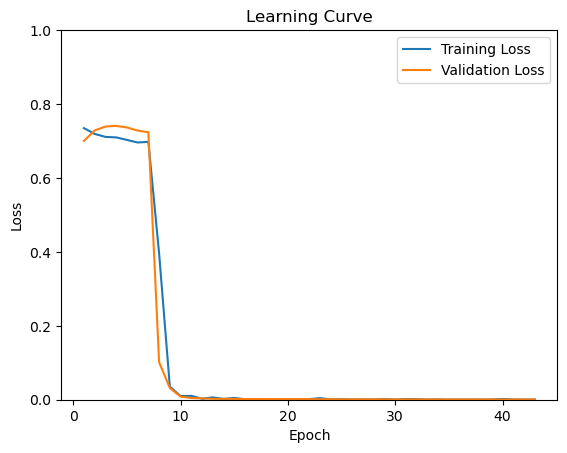

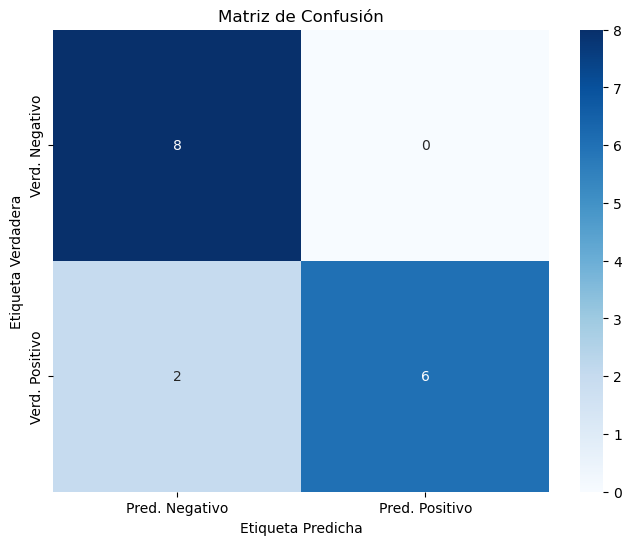

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 42. Best val loss: 0.0021270960569381714


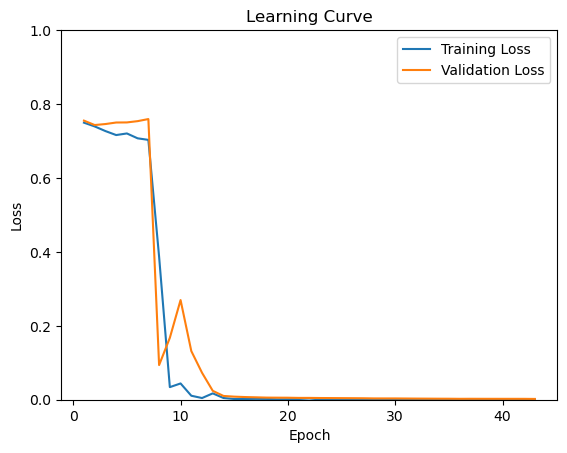

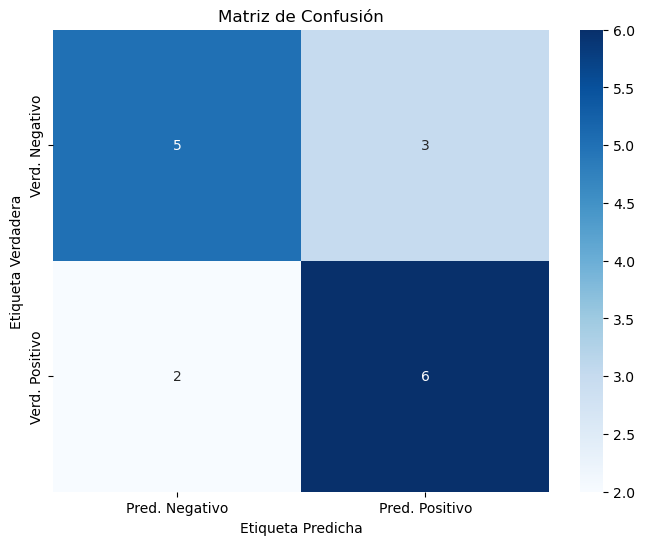

Accuracy: 0.6875. Recall: 0.75. Precision: 0.6666666666666666
Fold 3
Best epoc: 42. Best val loss: 0.0005595699767582119


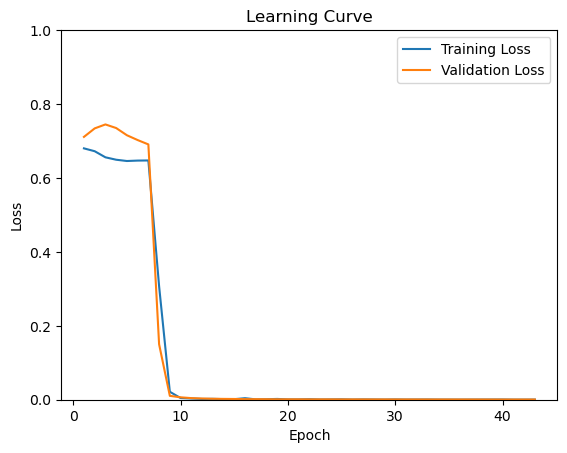

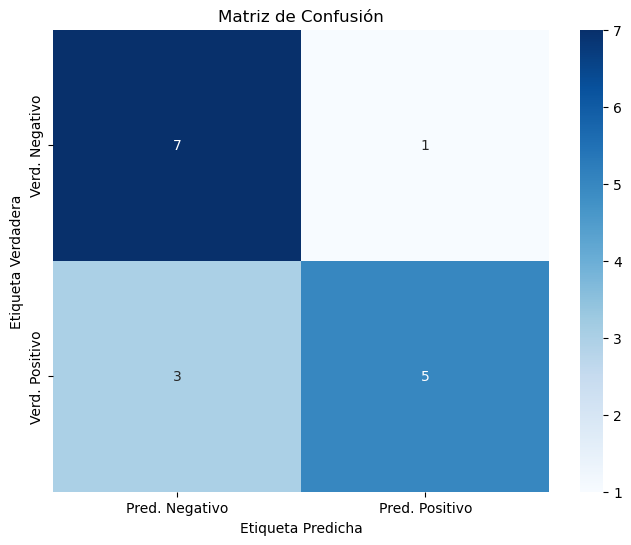

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 4
Best epoc: 42. Best val loss: 0.0014784361701458693


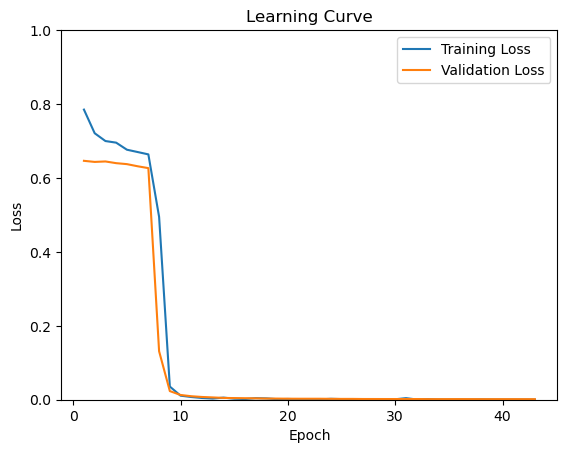

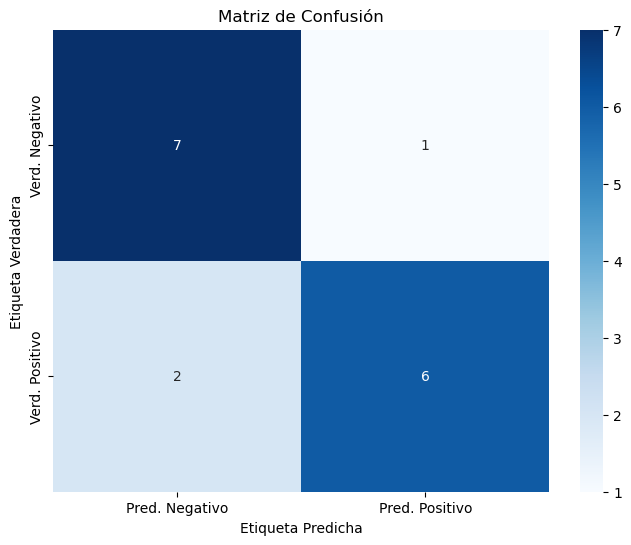

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
ACCS: [0.8125, 0.7875, 0.7875, 0.775, 0.7875]
RECS: [0.7, 0.65, 0.675, 0.625, 0.7]
PRECS: [0.9130952380952382, 0.9016666666666666, 0.8595238095238095, 0.9095238095238095, 0.8714285714285713]
F1S: [0.7924723247232472, 0.755424274973147, 0.7561675717610552, 0.7408844065166796, 0.7763636363636364]
STD-ACC: [0.03952847075210474, 0.0637377439199098, 0.1015504800579495, 0.049999999999999996, 0.0637377439199098]
STD-REC: [0.09999999999999999, 0.1224744871391589, 0.1695582495781317, 0.0, 0.06123724356957946]
STD-PREC: [0.072178601862972, 0.08373237791386978, 0.08053111678708459, 0.11703053073756672, 0.12380952380952383]
ACC: 0.79
0.012247448713915888
0.018068807663623825
RECALL: 0.6700000000000002
PRECISION: 0.8910476190476191
F1: 0.7642624428675531
STD-ACC: 0.06371088772997477
STD-REC: 0.09065399605737401
STD-PREC: 0.09545643022220338


In [11]:
accs = []
recs = []
precs = []
f1 = []
std_accs = []
std_recs = []
std_precs = []
seeds = random.sample(range(1,10001), 100)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
for i in range(5):
    acc, rec, prec, std_acc, std_rec, std_prec = prueba_k_fold_resnet_pre_impr_fin(df_mean_a_2, 5, 7, 36, optim.RMSprop, 32, 4.525290596706803e-05, False, None, seeds[0], seeds_tr[0])
    accs.append(acc)
    recs.append(rec)
    precs.append(prec)
    std_accs.append(std_acc)
    std_recs.append(std_rec)
    std_precs.append(std_prec)
    f1.append(2*(rec*prec)/(rec+prec))
    seeds.pop(0)
    seeds_tr.pop(0)

print(f"ACCS: {accs}")
print(f"RECS: {recs}")
print(f"PRECS: {precs}")
print(f"F1S: {f1}")

print(f"STD-ACC: {std_accs}")
print(f"STD-REC: {std_recs}")
print(f"STD-PREC: {std_precs}")

print(f"ACC: {np.mean(accs)}")
print(np.std(accs))
print(np.std(f1))
print(f"RECALL: {np.mean(recs)}")
print(f"PRECISION: {np.mean(precs)}")
print(f"F1: {np.mean(f1)}")
print(f"STD-ACC: {np.mean(std_accs)}")
print(f"STD-REC: {np.mean(std_recs)}")
print(f"STD-PREC: {np.mean(std_precs)}")

Fold 0
Best epoc: 11. Best val loss: 0.00483074551448226


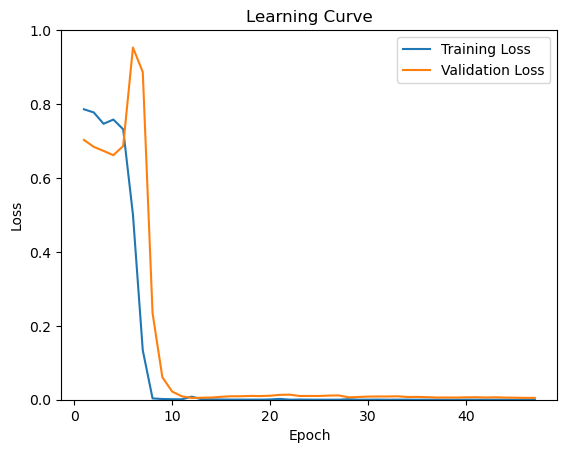

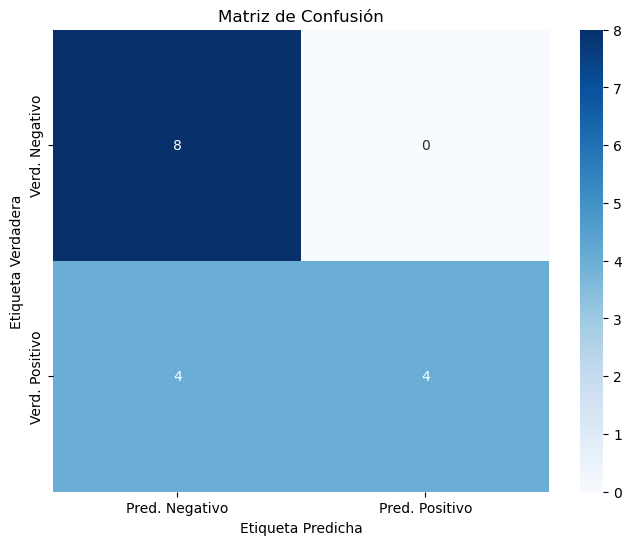

Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 1
Best epoc: 40. Best val loss: 0.0008519082912243903


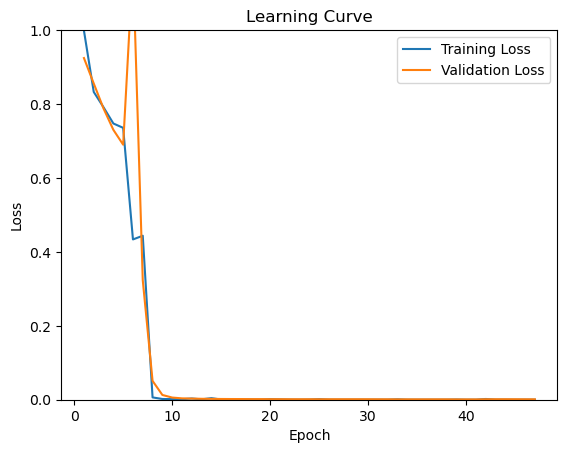

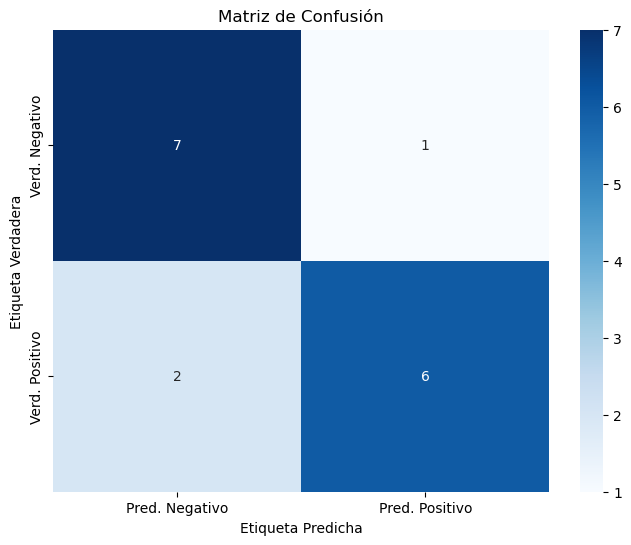

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 2
Best epoc: 44. Best val loss: 7.353110413532704e-05


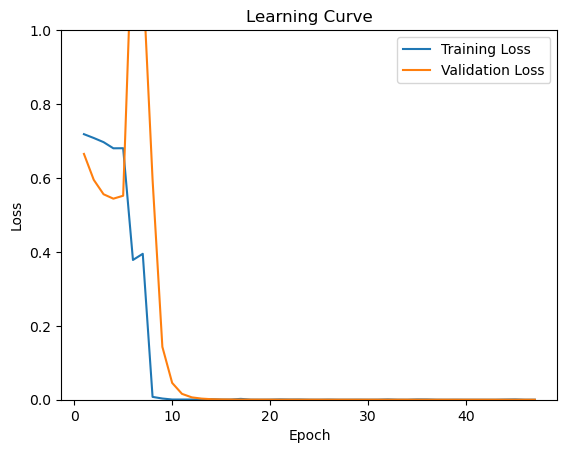

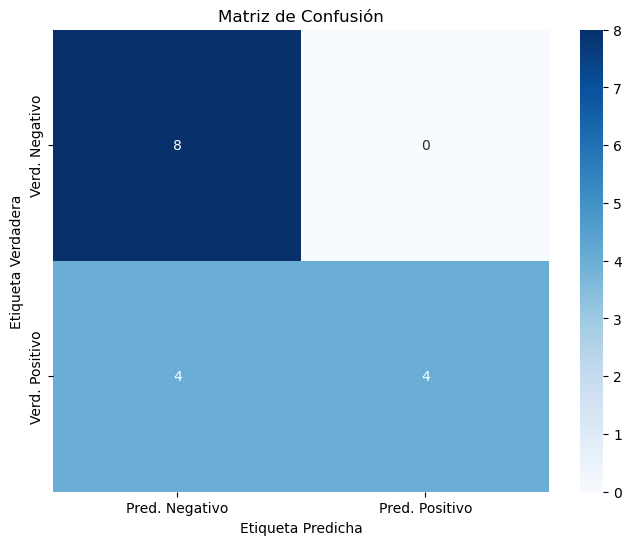

Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 39. Best val loss: 0.0015887748450040817


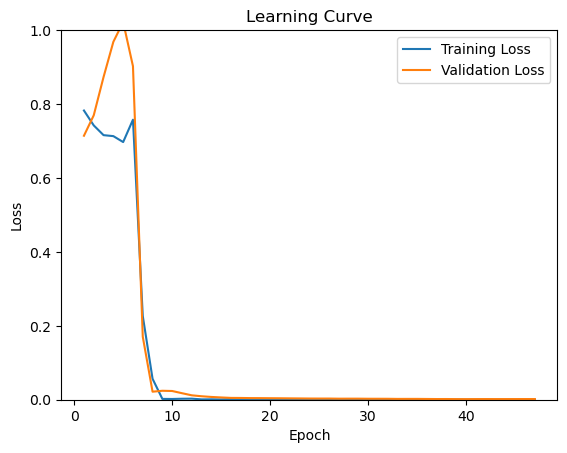

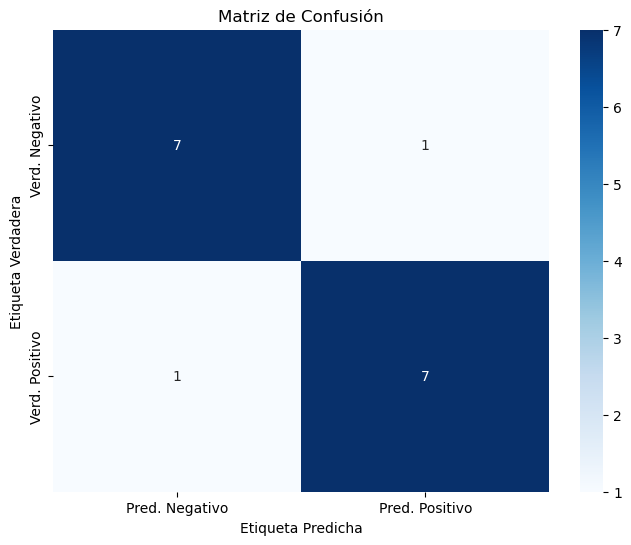

Accuracy: 0.875. Recall: 0.875. Precision: 0.875
Fold 4
Best epoc: 35. Best val loss: 0.010149538516998291


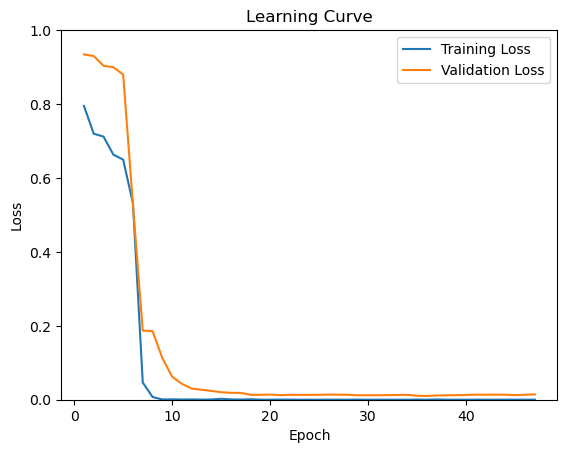

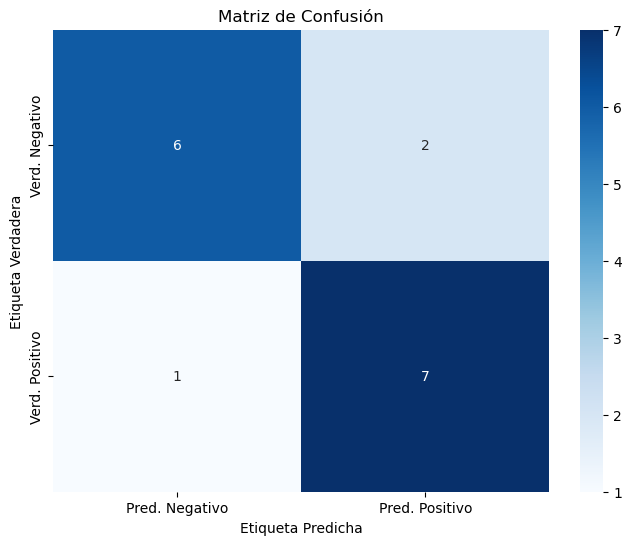

Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 0
Best epoc: 46. Best val loss: 9.881852747639641e-05


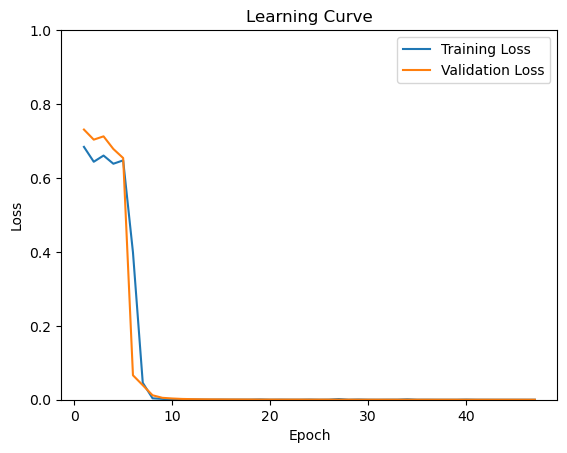

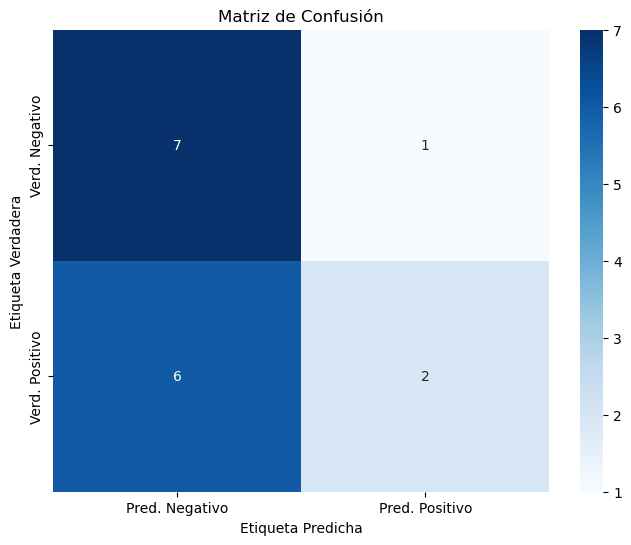

Accuracy: 0.5625. Recall: 0.25. Precision: 0.6666666666666666
Fold 1
Best epoc: 42. Best val loss: 0.00016896500892471522


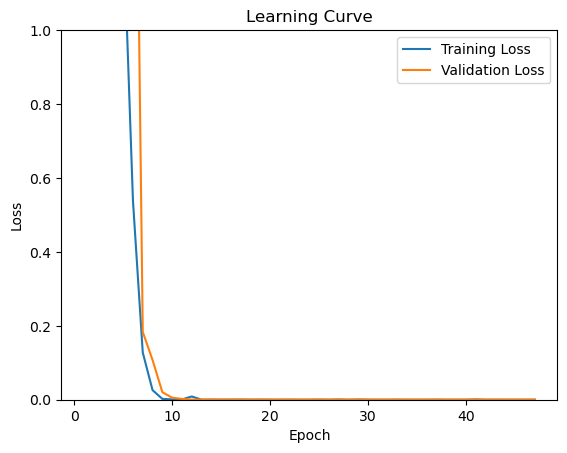

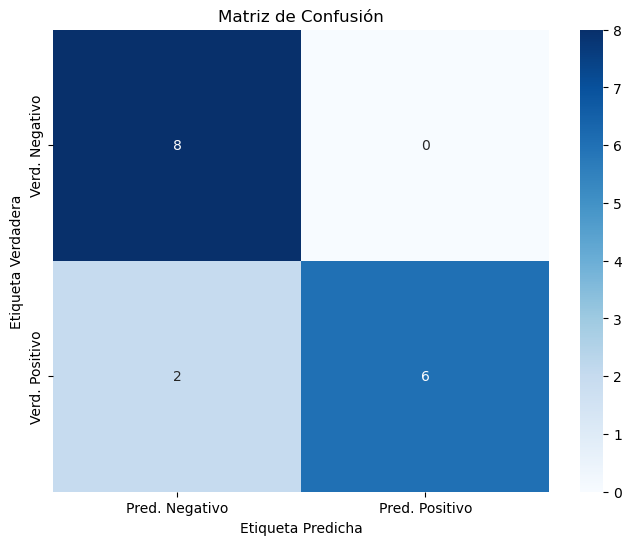

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 46. Best val loss: 0.0003851938236039132


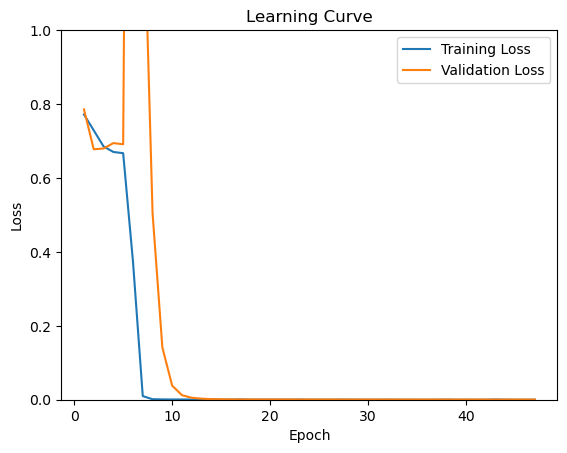

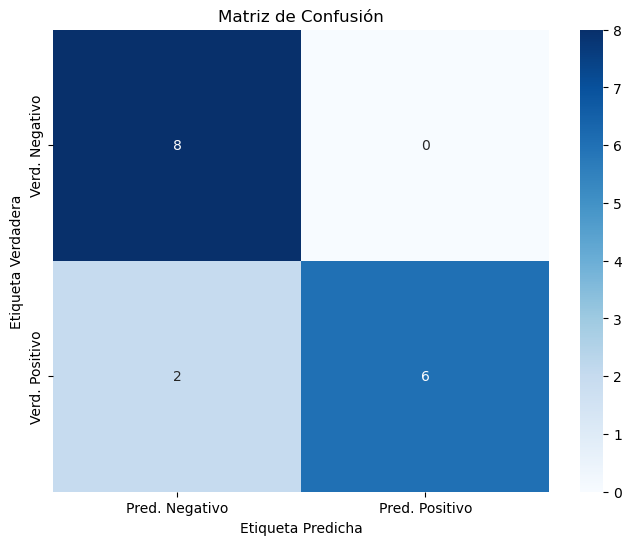

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 46. Best val loss: 0.0005485034198500216


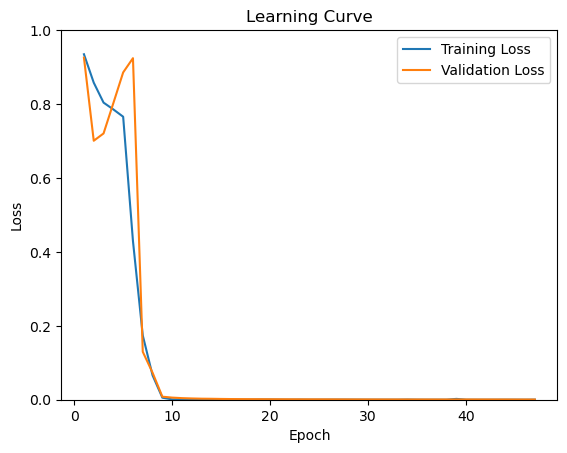

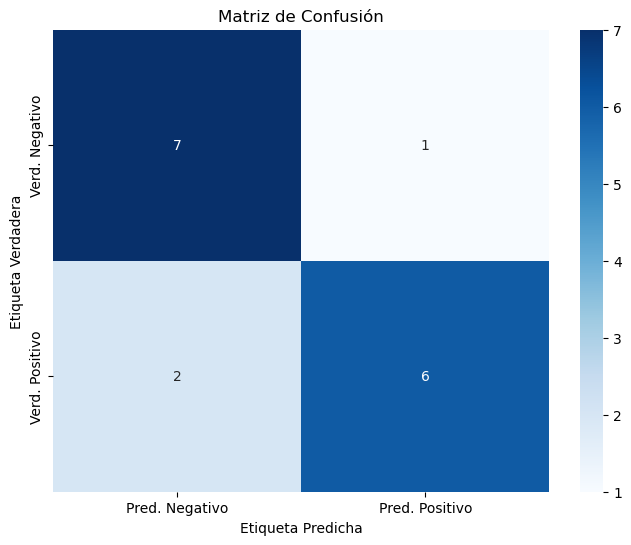

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 4
Best epoc: 5. Best val loss: 0.24886760115623474


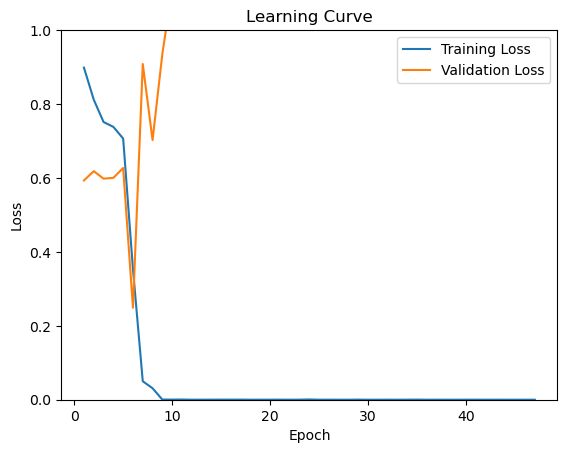

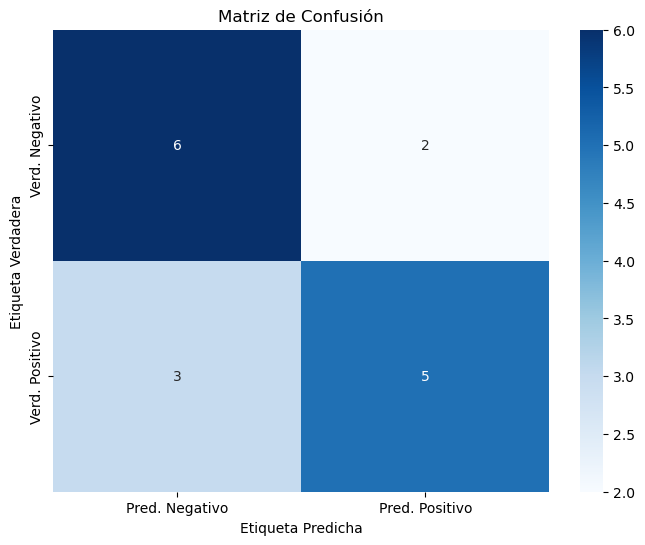

Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 0
Best epoc: 46. Best val loss: 0.0001789653761079535


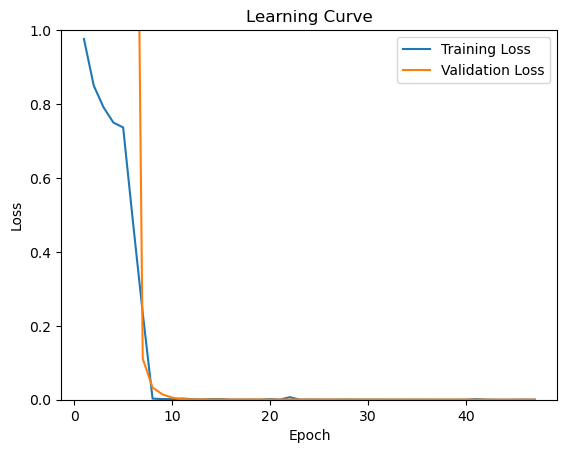

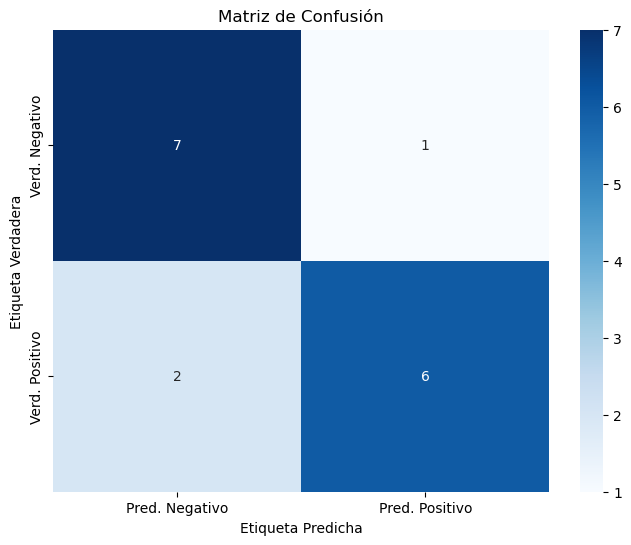

Accuracy: 0.8125. Recall: 0.75. Precision: 0.8571428571428571
Fold 1
Best epoc: 41. Best val loss: 0.0025967631954699755


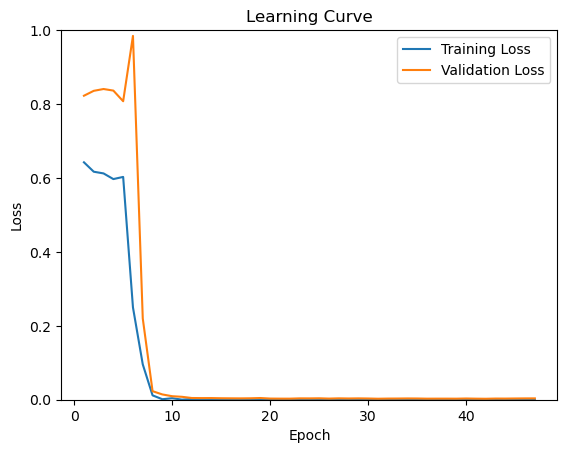

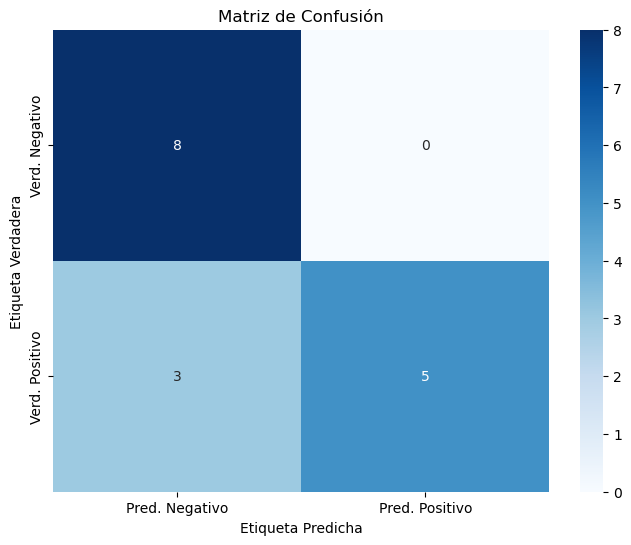

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 2
Best epoc: 45. Best val loss: 0.0002754656597971916


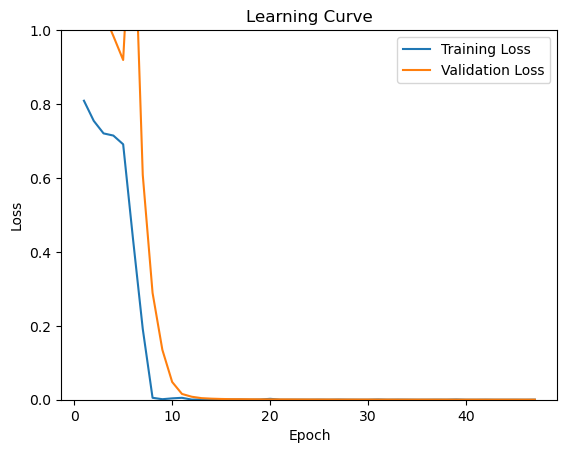

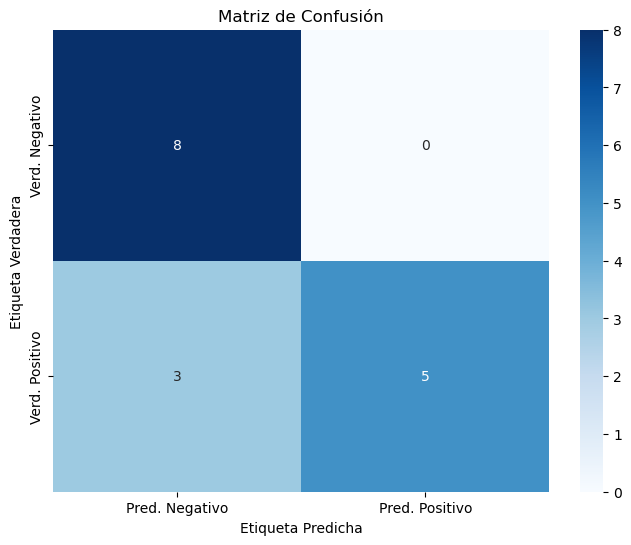

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 3
Best epoc: 46. Best val loss: 0.00014574396482203156


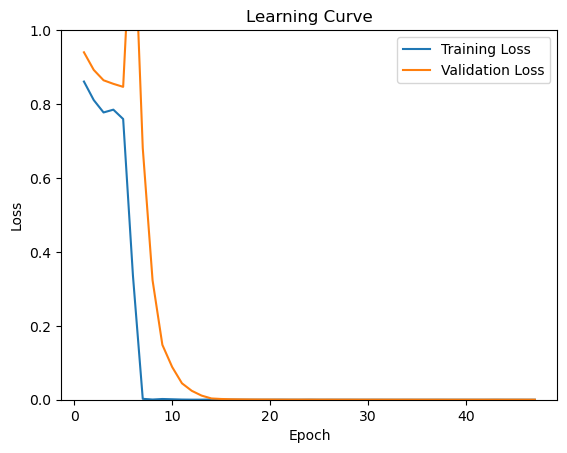

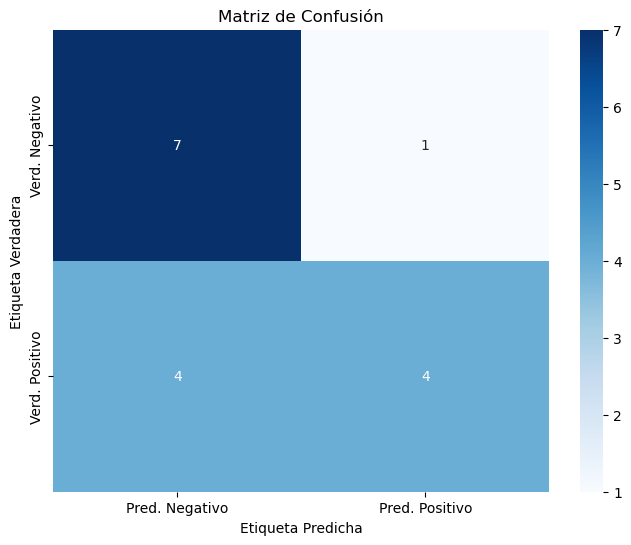

Accuracy: 0.6875. Recall: 0.5. Precision: 0.8
Fold 4
Best epoc: 43. Best val loss: 0.00031928959651850164


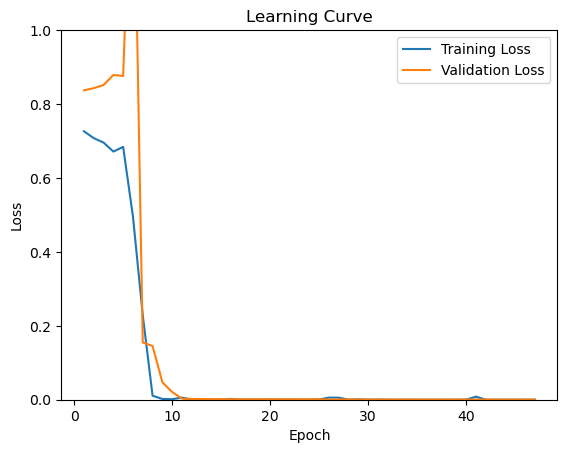

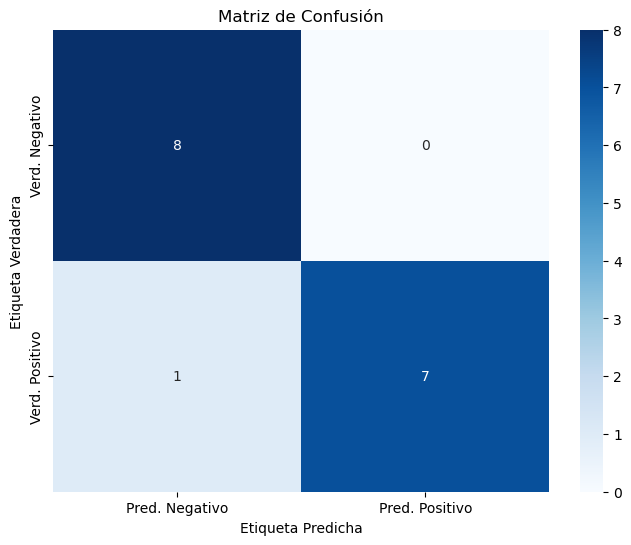

Accuracy: 0.9375. Recall: 0.875. Precision: 1.0
Fold 0
Best epoc: 46. Best val loss: 0.0003156896564178169


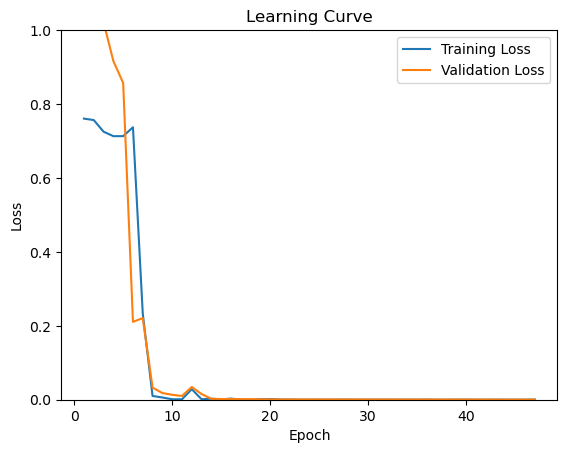

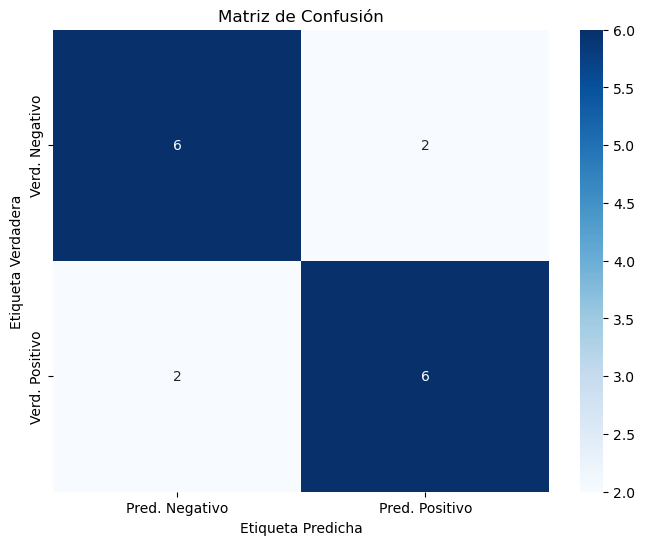

Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 1
Best epoc: 46. Best val loss: 0.00038582258275710046


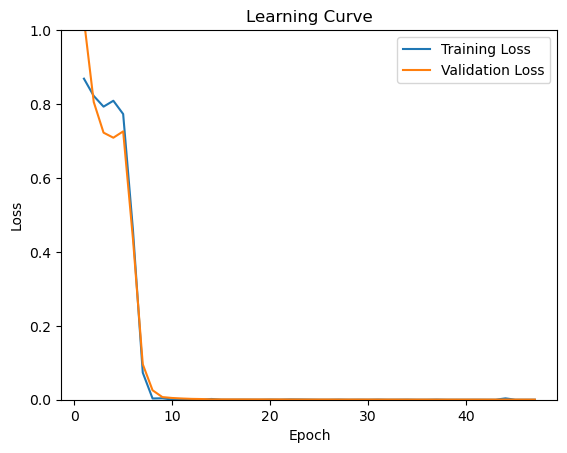

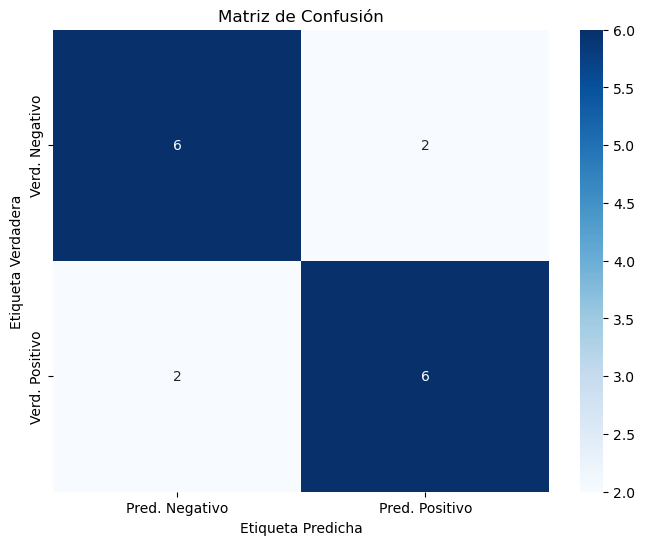

Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 46. Best val loss: 0.00012286409037187696


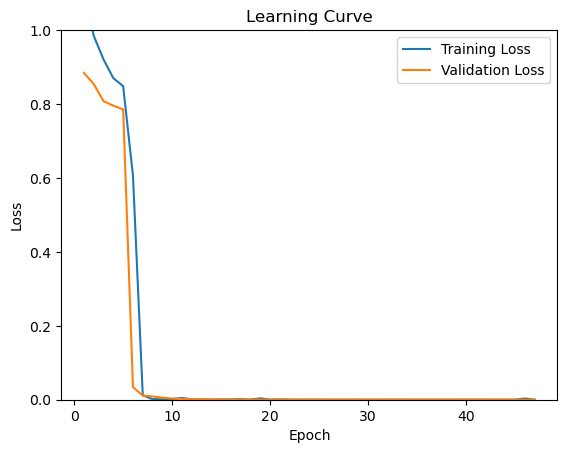

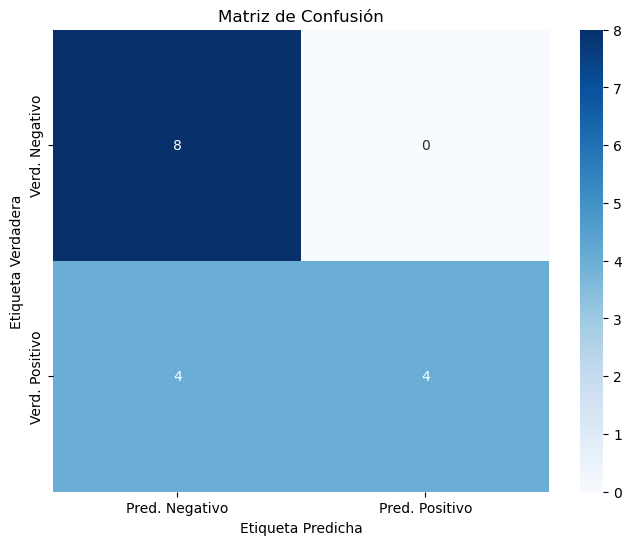

Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 46. Best val loss: 0.0001866608508862555


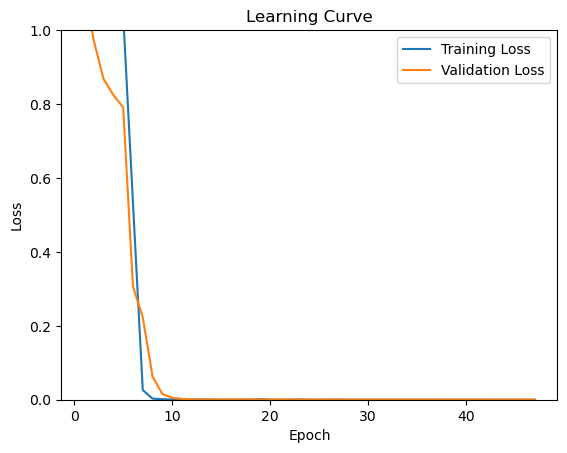

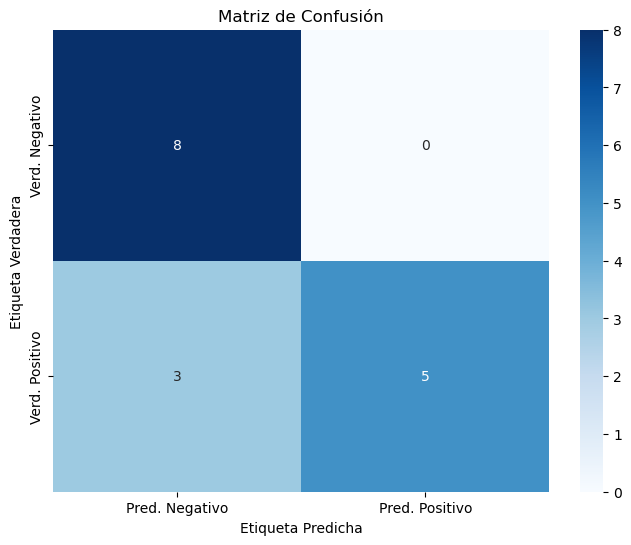

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
Fold 4
Best epoc: 42. Best val loss: 5.829495421494357e-05


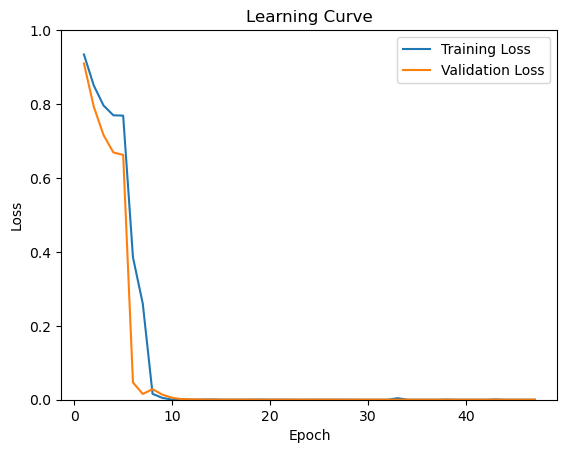

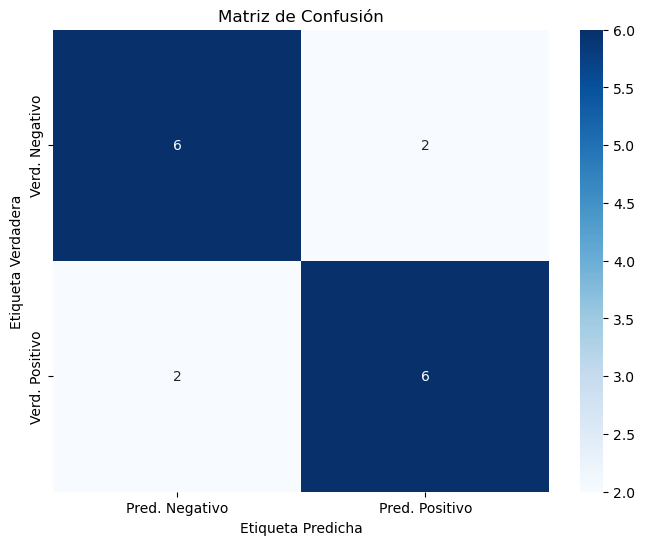

Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 0
Best epoc: 46. Best val loss: 0.0017205451149493456


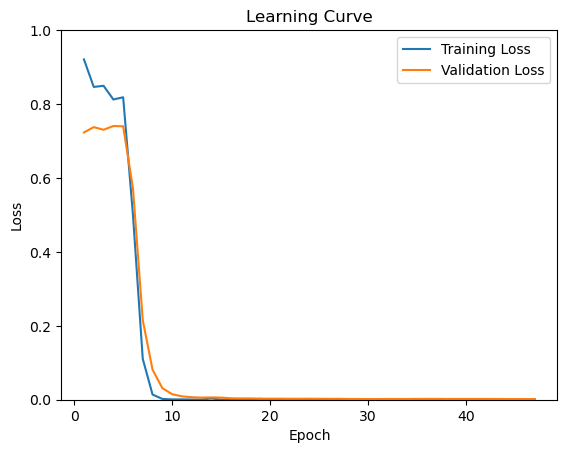

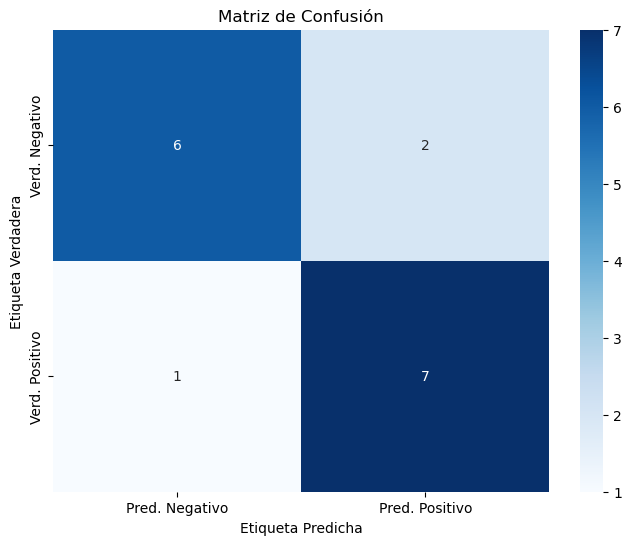

Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 1
Best epoc: 27. Best val loss: 0.004593632649630308


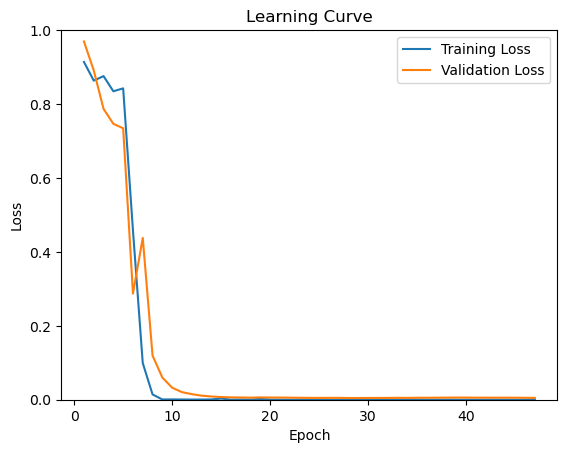

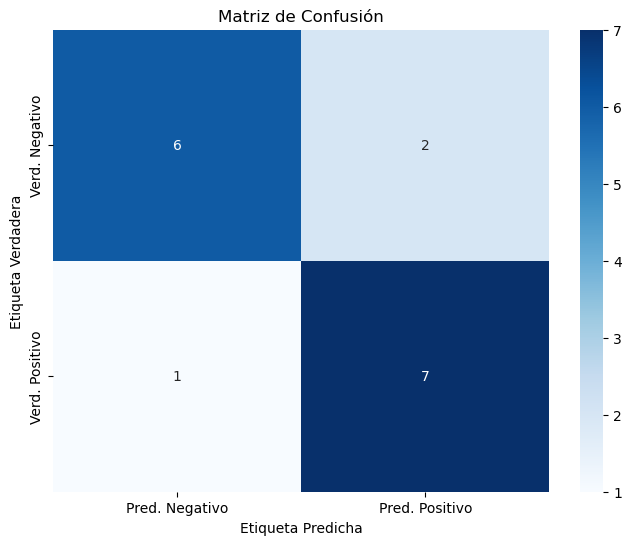

Accuracy: 0.8125. Recall: 0.875. Precision: 0.7777777777777778
Fold 2
Best epoc: 46. Best val loss: 0.0005410244921222329


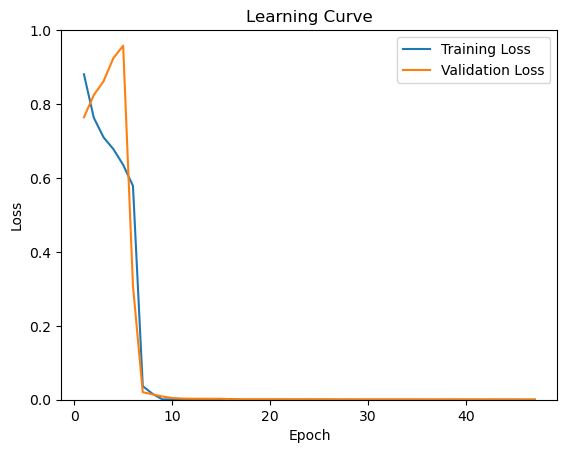

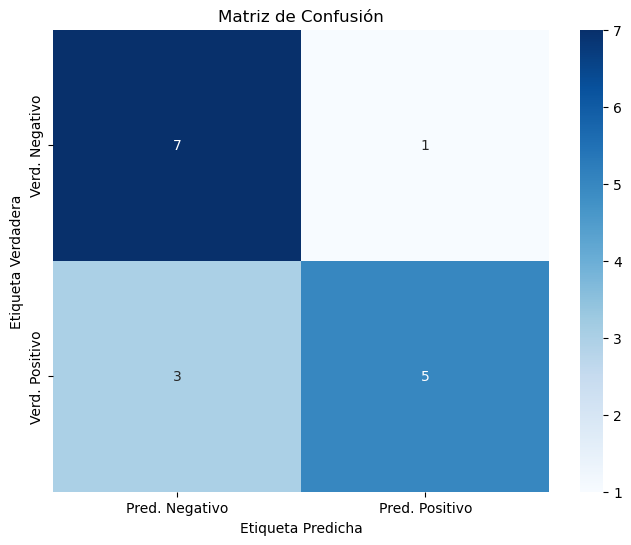

Accuracy: 0.75. Recall: 0.625. Precision: 0.8333333333333334
Fold 3
Best epoc: 46. Best val loss: 0.000229649172979407


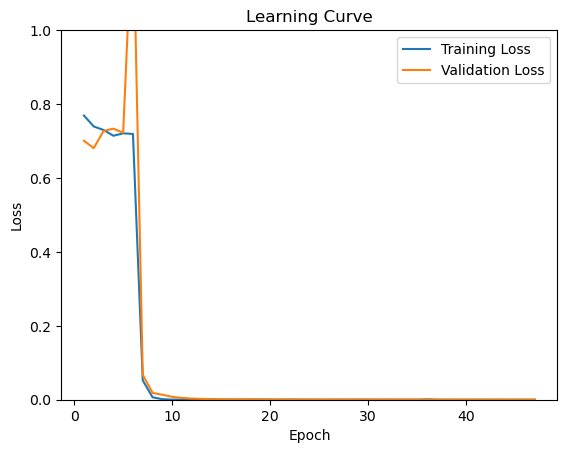

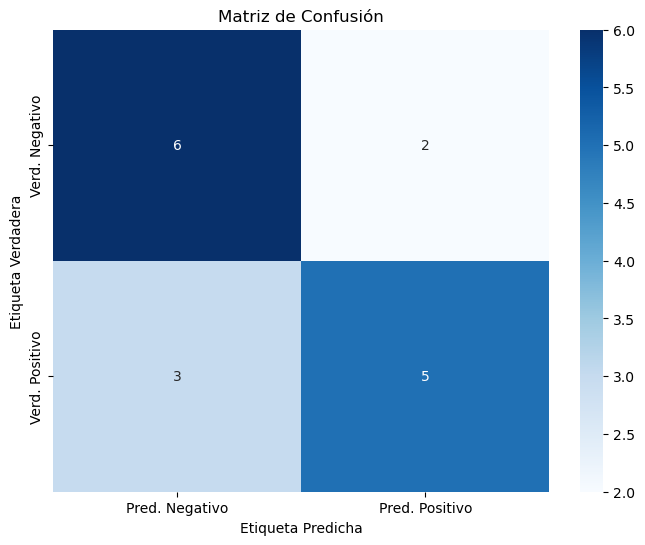

Accuracy: 0.6875. Recall: 0.625. Precision: 0.7142857142857143
Fold 4
Best epoc: 46. Best val loss: 0.00017630831280257553


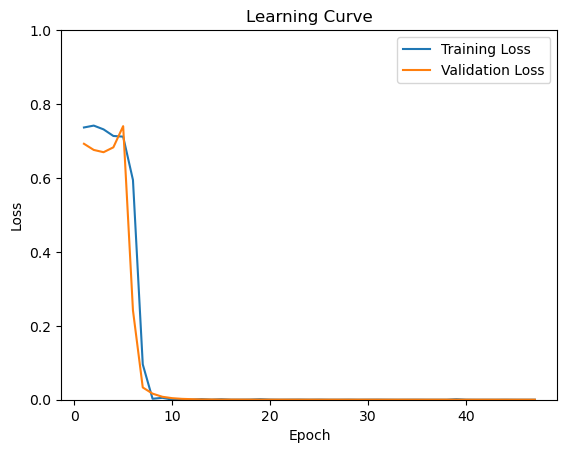

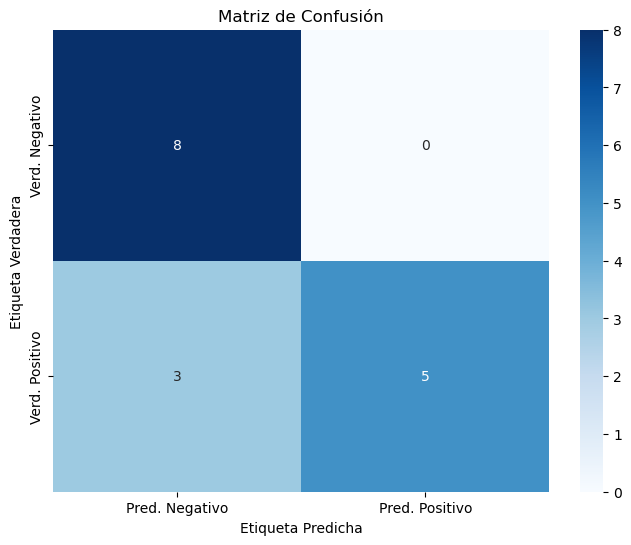

Accuracy: 0.8125. Recall: 0.625. Precision: 1.0
ACCS: [0.8, 0.7625, 0.8125, 0.7625, 0.775]
RECS: [0.7, 0.625, 0.675, 0.675, 0.725]
PRECS: [0.9019841269841271, 0.8476190476190476, 0.9314285714285715, 0.85, 0.8206349206349206]
F1S: [0.7882586078771364, 0.7194826192400969, 0.7827478879502001, 0.7524590163934426, 0.7698587933247754]
STD-ACC: [0.04677071733467427, 0.12119199643540822, 0.07905694150420949, 0.024999999999999998, 0.05]
STD-REC: [0.1695582495781317, 0.19364916731037085, 0.12747548783981963, 0.09999999999999999, 0.1224744871391589]
STD-PREC: [0.08646423827151908, 0.13932132226978852, 0.08590455073355949, 0.1224744871391589, 0.09727970441933055]
ACC: 0.7825
0.020310096011589923
0.024815044807831865
RECALL: 0.6799999999999999
PRECISION: 0.8703333333333333
F1: 0.7625613849571302
STD-ACC: 0.0644039310548584
STD-REC: 0.1426314783734962
STD-PREC: 0.1062888605666713


In [12]:
accs = []
recs = []
precs = []
f1 = []
std_accs = []
std_recs = []
std_precs = []
seeds = random.sample(range(1,10001), 100)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
for i in range(5):
    acc, rec, prec, std_acc, std_rec, std_prec = prueba_k_fold_resnet_pre_impr_fin(df_mean_a_2, 5, 5, 42, optim.RMSprop, 32, 5.501685301399041e-05, False, 'H', seeds[0], seeds_tr[0])
    accs.append(acc)
    recs.append(rec)
    precs.append(prec)
    std_accs.append(std_acc)
    std_recs.append(std_rec)
    std_precs.append(std_prec)
    f1.append(2*(rec*prec)/(rec+prec))
    seeds.pop(0)
    seeds_tr.pop(0)

print(f"ACCS: {accs}")
print(f"RECS: {recs}")
print(f"PRECS: {precs}")
print(f"F1S: {f1}")

print(f"STD-ACC: {std_accs}")
print(f"STD-REC: {std_recs}")
print(f"STD-PREC: {std_precs}")

print(f"ACC: {np.mean(accs)}")
print(np.std(accs))
print(np.std(f1))
print(f"RECALL: {np.mean(recs)}")
print(f"PRECISION: {np.mean(precs)}")
print(f"F1: {np.mean(f1)}")
print(f"STD-ACC: {np.mean(std_accs)}")
print(f"STD-REC: {np.mean(std_recs)}")
print(f"STD-PREC: {np.mean(std_precs)}")